# AI Impact on Students — Exploratory Data Analysis

**Lab 01 · Introduction to Machine Learning · Linear Regression**

Notebook phân tích dữ liệu thực trong `archive/`, xuất artifacts có thể truy vết và chuẩn bị thiết kế hồi quy dự đoán `Post_Semester_GPA`.
Nhận xét định lượng được sinh từ kết quả chạy; không lấy thống kê của tác giả làm kết quả của nhóm.

**Data contract:** structural audit trên toàn file → deterministic cleaning → frozen 70/15/15 split → EDA trên **train** → so sánh thăm dò trên **validation**.
**Test chỉ được dùng cho counts và integrity**, không dùng target test, fit, diagnostics hay lựa chọn mô hình.

Chạy **Restart Kernel → Run All**. Thay đường dẫn và tùy chọn ở cell cấu hình bên dưới. CSV gốc không bị sửa.

In [1]:
# Centralized configuration — edit this cell only for paths and analysis policy.
import os
from pathlib import Path

_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in _candidates if (p / 'brief.md').is_file()), Path.cwd())
DATA_PATH = os.environ.get('LAB_DATA_PATH') or None  # None: discover CSV in archive/, data/raw/, /kaggle/input.
OUTPUT_DIR = Path(os.environ.get('LAB_OUTPUT_DIR', str(PROJECT_ROOT / 'reports')))
SPLIT_DIR = Path(os.environ.get('LAB_SPLIT_DIR', str(PROJECT_ROOT / 'data' / 'splits')))
SOURCE_METADATA_PATH = PROJECT_ROOT / 'data' / 'source_metadata.json'
TARGET_COLUMN = 'Post_Semester_GPA'
ID_COLUMN = 'Student_ID'
RANDOM_STATE = 42
TRAIN_RATIO, VALIDATION_RATIO, TEST_RATIO = 0.70, 0.15, 0.15
PLOT_SAMPLE_SIZE = 5000
FIGURE_DPI = 300
SAVE_FIGURES, SAVE_TABLES = True, True
RUN_OPTIONAL_TESTS = False
PLOT_VALIDATION_TARGET = False
MIN_GROUP_SIZE = 30
GPA_EQUAL_TOLERANCE = 1e-9  # floating-point equality only; measurement precision unverified.
HIGH_CORRELATION_THRESHOLD = 0.8
PREDICTION_CUTOFF = 'Before end-of-semester GPA is known'
SOURCE_URL = 'https://www.kaggle.com/datasets/laveshjadon/ai-impact-on-students'
# Only pre-semester GPA is explicitly located before the cutoff by the source.
VERIFIED_AVAILABLE = ['Pre_Semester_GPA']
# Source documents only an upper GPA endpoint; do not invent a floor.
GPA_UPPER_BOUNDARY = 4.0
GPA_LOWER_BOUNDARY = None
CONFIRMED_HOURS_ADDITIVE = False
assert all(0 < r < 1 for r in [TRAIN_RATIO, VALIDATION_RATIO, TEST_RATIO])
assert abs(TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO - 1) < 1e-10
assert PLOT_SAMPLE_SIZE > 0 and MIN_GROUP_SIZE > 0 and GPA_EQUAL_TOLERANCE >= 0

## Execution helpers

Các hàm lưu output luôn đăng ký scope và trạng thái trong manifest. Rerun cùng dữ liệu/cấu hình được phép;
nếu fingerprint hoặc cấu hình thay đổi, cần chọn thư mục output/split mới để bảo vệ kết quả cũ.
Sampling chỉ áp dụng cho hình; bảng thống kê sử dụng toàn bộ train hợp lệ.

In [2]:
import csv
import hashlib
import importlib.metadata
import io
import json
import math
import platform
import re
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 10, 'axes.labelsize': 9})
pd.set_option('display.max_columns', 14)
pd.set_option('display.precision', 4)

TABLE_TITLES = [
 'Dataset Overview', 'Data Dictionary', 'Feature Type Summary', 'Unique Values Summary',
 'Missing Values Summary', 'Duplicate Records Summary', 'Invalid Values Summary', 'Outlier Summary',
 'Data Quality Report', 'Numerical Descriptive Statistics', 'Categorical Descriptive Statistics',
 'Category Frequency Distribution', 'Distribution Characteristics and Skewness', 'Target Statistics',
 'GPA Change Statistics', 'Improvement Summary', 'GPA Change by Initial GPA Group',
 'GPA Boundary Concentration', 'Pearson with Target', 'Spearman with Target',
 'Categorical vs Target Summary', 'Group Difference Summary', 'AI Usage Intensity Groups',
 'Academic AI Group Summary', 'Interaction Analysis Summary', 'Subgroup Summary',
 'Highly Correlated Predictor Pairs', 'VIF Analysis', 'Exploratory Regression Results',
 'Coefficients', 'Regression Assumption Diagnostics', 'Influential Observations Summary',
 'Derived Feature Definitions', 'Derived Feature Statistics', 'Original vs Transformed Comparison',
 'Encoding Recommendations', 'Scaling Recommendations', 'Feature Selection Recommendations',
 'Leakage Risk Assessment', 'Feature Availability Matrix', 'Split Integrity Report',
 'Dataset Bias and Limitations', 'Research Questions and Evidence', 'Key EDA Findings',
 'Feature Decision Matrix', 'Preprocessing Plan', 'Linear Regression Model Recommendations',
 'Dataset Limitations']
FIGURE_TITLES = [
 'Feature Types Distribution', 'Missing Percentage', 'Missing Pattern', 'Numerical Boxplots',
 'Outlier Percentage by Feature', 'Numerical Histograms', 'Continuous Density Plots',
 'Numerical Boxplots', 'Categorical Count Plots', 'Ordinal Distributions', 'Skewness Comparison',
 'Post GPA Distribution', 'Pre vs Post GPA Distribution', 'GPA Change Distribution',
 'Improved Unchanged Declined', 'Pre vs Post GPA with Identity Line', 'GPA Change by Initial GPA Group',
 'Numerical Predictors vs Post GPA', 'Numerical Predictors vs GPA Change', 'Pearson Heatmap',
 'Spearman Heatmap', 'Feature Correlation with Post GPA', 'Feature Correlation with GPA Change',
 'AI Hours vs GPA Linear and Binned Trend', 'Post GPA by Major', 'Post GPA by Year',
 'Post GPA by Primary Use Case', 'Post GPA by Prompt Skill', 'Post GPA by Paid Subscription',
 'Post GPA by Institutional Policy', 'GPA Change by Categorical Groups', 'GPA Change by AI Usage Hours',
 'AI Hours vs GPA by Prompt Skill', 'AI Hours vs GPA by Major', 'AI Hours and Study Heatmap',
 'Use Case and Prompt Skill Heatmap', 'Dependency and Anxiety Heatmap', 'AI Hours vs Change by Pre GPA',
 'AI Hours Dependency and Skill Retention', 'Predictor Correlation Heatmap', 'VIF Comparison',
 'Actual vs Predicted GPA', 'Residual vs Fitted', 'Residual Distribution', 'QQ Plot',
 'Scale Location', 'Cooks Distance', 'Residuals vs Key Predictors', 'Exploratory Model Comparison',
 'Original vs Transformed AI Hours', 'Derived Feature Distributions', 'Derived Feature Correlations',
 'Linear vs Polynomial Relationship', 'Correlation Before After Engineering', 'Sample Counts Across Splits',
 'Target Distribution Train vs Validation', 'Feature Availability and Leakage Risk Matrix']
T_SECTIONS = [2]*4 + [3]*5 + [4]*4 + [6]*5 + [7]*4 + [8]*4 + [9]*6 + [10]*6 + [11]*4 + [12]*6
F_SECTIONS = [2] + [3]*4 + [5]*6 + [6]*6 + [7]*14 + [8]*8 + [9]*10 + [10]*5 + [11]*3
assert len(TABLE_TITLES) == 48 and len(FIGURE_TITLES) == 57
assert len(T_SECTIONS) == 48 and len(F_SECTIONS) == 57
manifest = {}
tables = {}
warnings_log = []
for prefix, titles, sections, kind in [('T', TABLE_TITLES, T_SECTIONS, 'table'), ('F', FIGURE_TITLES, F_SECTIONS, 'figure')]:
    for i, (title, section) in enumerate(zip(titles, sections), 1):
        aid = f'{prefix}{i:02}'
        manifest[aid] = dict(artifact_id=aid, artifact_type=kind, title=title, relative_path='',
            section=section, data_scope='train', status='pending', related_ids='', reason='')

def note(text):
    display(Markdown(text))

def digest_file(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

def json_write(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str, allow_nan=False), encoding='utf-8')

def filename(aid, extension):
    slug = re.sub(r'[^a-z0-9]+', '_', manifest[aid]['title'].lower()).strip('_')
    return f'{aid}_{slug}.{extension}'

def skip(aid, reason, scope='train'):
    manifest[aid].update(status='skipped', reason=reason, data_scope=scope, relative_path='')

def save_table(aid, frame, scope='train', caption=None):
    frame = pd.DataFrame(frame)
    tables[aid] = frame.copy()
    if frame.shape[1] == 0:
        skip(aid, 'No applicable rows or columns for this optional analysis', scope)
        note(f'**{aid}** skipped: no applicable rows/columns.')
        return frame
    note(f"**{aid} · {manifest[aid]['title']}** — scope: `{scope}`; {len(frame):,} rows. " + (caption or ''))
    display(frame.head(12))
    if SAVE_TABLES:
        path = OUTPUT_DIR / 'tables' / filename(aid, 'csv')
        path.parent.mkdir(parents=True, exist_ok=True)
        frame.to_csv(path, index=False, encoding='utf-8', float_format='%.17g')
        manifest[aid].update(status='generated', data_scope=scope, relative_path=path.relative_to(OUTPUT_DIR).as_posix())
    else:
        skip(aid, 'SAVE_TABLES=False; displayed inline only', scope)
    return frame

def save_figure(aid, fig, scope='train', caption=None):
    fig.suptitle(f"{aid} · {manifest[aid]['title']} [{scope}]", fontsize=12, y=1.02)
    fig.tight_layout()
    if SAVE_FIGURES:
        path = OUTPUT_DIR / 'figures' / filename(aid, 'png')
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=FIGURE_DPI, bbox_inches='tight')
        manifest[aid].update(status='generated', data_scope=scope, relative_path=path.relative_to(OUTPUT_DIR).as_posix())
    else:
        skip(aid, 'SAVE_FIGURES=False; displayed inline only', scope)
    plt.show()
    plt.close(fig)
    if caption:
        note(caption)

def reuse(aid, source):
    record = manifest[source]
    if record['status'] in ['generated', 'reused']:
        manifest[aid].update(status='reused', data_scope=record['data_scope'], relative_path=record['relative_path'],
                            related_ids=source, reason=f'Equivalent panels shared with {source}')
    else:
        skip(aid, f'Alias {source}: {record["reason"]}', record['data_scope'])

def axes_grid(n, columns=3, height=3.1):
    columns = min(columns, max(1, n))
    fig, ax = plt.subplots(math.ceil(max(1,n)/columns), columns, figsize=(5*columns, height*math.ceil(max(1,n)/columns)), squeeze=False)
    for a in ax.flat[n:]:
        a.set_visible(False)
    return fig, list(ax.flat)

def plot_sample(frame):
    return frame.sample(min(len(frame), PLOT_SAMPLE_SIZE), random_state=RANDOM_STATE)

def safe_correlation(frame, x, y, method):
    pair = frame[[x,y]].apply(pd.to_numeric, errors='coerce').replace([np.inf,-np.inf], np.nan).dropna()
    n = len(pair)
    reason = 'insufficient pairs' if n < 3 else ('constant feature or target' if pair.nunique().min() < 2 else '')
    value = np.nan if reason else pair[x].corr(pair[y], method=method)
    return {'feature':x, 'outcome':y, 'method':method, 'valid_n':n, 'coefficient':value, 'reason':reason}

def ordered_levels(series, feature=None):
    if isinstance(series.dtype, pd.CategoricalDtype):
        levels=[str(v) for v in series.cat.categories]
    elif feature in globals().get('orders',{}):
        documented=orders[feature]
        seen=series.dropna().astype(str).unique().tolist()
        levels=[v for v in documented if v in seen]+sorted(set(seen)-set(documented))
    elif pd.api.types.is_numeric_dtype(series):
        levels=[str(v) for v in sorted(series.dropna().unique())]
    else:
        levels=sorted(series.dropna().astype(str).unique())
    return levels+(['<missing>'] if series.isna().any() else [])

def summary_groups(frame, group, outcome=TARGET_COLUMN):
    labels=frame[group].astype('string').fillna('<missing>')
    part = frame.assign(_group=pd.Categorical(labels,categories=ordered_levels(frame[group],group),ordered=True))
    out = part.groupby('_group', observed=True, sort=True)[outcome].agg(['size','count','mean','median','std']).reset_index()
    out = out.rename(columns={'_group':'group','count':'valid_n','size':'group_n'})
    out.insert(0, 'feature', group)
    out['outcome'] = outcome
    out['se'] = out['std'] / np.sqrt(out['valid_n'])
    critical = stats.t.ppf(.975, (out['valid_n']-1).clip(lower=1))
    out['ci95_low'] = out['mean'] - critical*out['se']
    out['ci95_high'] = out['mean'] + critical*out['se']
    out['small_group'] = out['valid_n'] < MIN_GROUP_SIZE
    out['ci_method'] = 't-based mean CI; independence not verified'
    return out

def heatmap(aid, matrix, caption=None):
    if matrix.empty:
        skip(aid, 'No applicable numeric columns')
        return
    fig, ax = plt.subplots(figsize=(max(7, .65*len(matrix.columns)), max(5,.5*len(matrix))))
    sns.heatmap(matrix, vmin=-1, vmax=1, cmap='vlag', center=0, annot=len(matrix)<12, fmt='.2f', ax=ax)
    save_figure(aid, fig, caption=caption)

## Section 1 — Introduction

**Objective.** Dự đoán GPA cuối học kỳ trước khi biết kết quả; xem nhóm thuộc tính AI có bổ sung khả năng dự đoán so với Pre GPA và học tập truyền thống hay không.
Hồi quy phù hợp vì target liên tục; sai số MAE/RMSE và R² cần được xem cùng giới hạn miền GPA.

**Nguồn:** [Kaggle · AI Impact on Students](https://www.kaggle.com/datasets/laveshjadon/ai-impact-on-students),
metadata chính thức đã kiểm tra ngày 2026-11-17, version 1, **synthetic**, CC0-1.0.
Snapshot tại `data/source_metadata.json`; phiên bản byte của CSV cục bộ chưa được publisher checksum xác thực.
Không có hai PDF tham chiếu trong workspace; notebook thực hiện theo `brief.md`, chưa xác minh nguyên văn quy định giảng viên.

| RQ | Research question |
|---|---|
| RQ01 | Schema, completeness và validity có phù hợp regression? |
| RQ02 | Pre GPA dự đoán Post GPA tốt đến đâu? |
| RQ03 | AI Hours liên hệ thế nào với Post GPA và GPA Change? |
| RQ04 | Traditional Study Hours liên hệ thế nào với kết quả? |
| RQ05 | Kết quả có khác theo Prompt Skill, Use Case và nhóm sinh viên? |
| RQ06 | Dependency liên hệ với GPA, Change và Retention? |
| RQ07 | Có bằng chứng phi tuyến, bão hòa hoặc interaction? |
| RQ08 | AI features bổ sung khả năng dự đoán trên validation? |
| RQ09 | Có đa cộng tuyến hoặc phụ thuộc tuyến tính hoàn hảo? |
| RQ10 | Nên impute, encode, scale và engineer như thế nào? |
| RQ11 | OLS có giới hạn giả định, clipping và sai lệch nào? |
| RQ12 | Provenance và representativeness giới hạn khái quát ra sao? |

`GPA_Change = Post − Pre` chỉ là analytical outcome, **không được làm predictor**.
Association không chứng minh causation. E1 dùng Pre GPA là baseline trước kỳ;
E2/E3 dùng biến chưa xác minh thời điểm là **conditional / retrospective**, chưa đủ bằng chứng triển khai forecasting.

## Section 2 — Dataset Overview

**Method.** Tìm CSV trong `archive/` trước; không giải nén lại và không tải mạng khi chạy.
Đọc UTF-8/BOM, giữ chuỗi gốc để kiểm toán coercion. Full-file audit chỉ dùng schema, missing, uniqueness, validity và thông tin chia tập;
min/max/categories phân phối trong Data Dictionary được tính từ **train** sau khi split.

**T01 · Dataset Overview** — scope: `full_structural_audit`; 1 rows. 

,rows,columns,file_bytes,memory_bytes,sha256,missing_optional,extra_columns,encoding,header_mapping,scope
0,50000,16,5892478,44292304,4d911088c4b12d60a450a9acae6b606f4119ebbb486795...,,,utf-8-sig,none,full_structural_audit


**T03 · Feature Type Summary** — scope: `full_structural_audit`; 6 rows. 

,semantic_type,features
0,continuous,5
1,ordinal,5
2,nominal,3
3,identifier,1
4,discrete,1
5,binary,1


**T04 · Unique Values Summary** — scope: `full_structural_audit`; 16 rows. 

,feature,unique_including_blank,loaded_dtype,inferred_dtype_first_1000
0,Student_ID,50000,string,int64
1,Major_Category,5,string,object
2,Year_of_Study,5,string,object
3,Pre_Semester_GPA,2389,string,float64
4,Weekly_GenAI_Hours,3566,string,float64
5,Primary_Use_Case,5,string,object
6,Prompt_Engineering_Skill,3,string,object
7,Tool_Diversity,5,string,int64
8,Paid_Subscription,2,string,bool
9,Traditional_Study_Hours,2516,string,float64


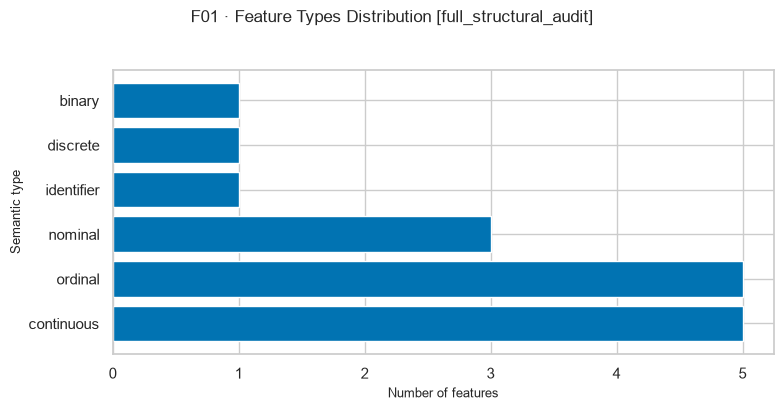

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Student_ID                  50000 non-null  string
 1   Major_Category              50000 non-null  string
 2   Year_of_Study               50000 non-null  string
 3   Pre_Semester_GPA            50000 non-null  string
 4   Weekly_GenAI_Hours          50000 non-null  string
 5   Primary_Use_Case            50000 non-null  string
 6   Prompt_Engineering_Skill    50000 non-null  string
 7   Tool_Diversity              50000 non-null  string
 8   Paid_Subscription           50000 non-null  string
 9   Traditional_Study_Hours     50000 non-null  string
 10  Perceived_AI_Dependency     50000 non-null  string
 11  Institutional_Policy        50000 non-null  string
 12  Anxiety_Level_During_Exams  50000 non-null  string
 13  Post_Semester_GPA           50000 non-null  st

**Interpretation.** T01/T03/T04 mô tả cấu trúc thực tế. Extra columns chỉ audit; thiếu optional sẽ skip phân tích phụ thuộc. Min/max và sample nội dung được giữ đến sau split. ID không phải predictor dù có dạng số.

In [3]:
def discover_csv():
    if DATA_PATH:
        p = Path(DATA_PATH).expanduser()
        p = p if p.is_absolute() else PROJECT_ROOT / p
        if not p.is_file():
            raise FileNotFoundError(f'DATA_PATH does not exist: {p}')
        return p
    candidates = []
    for folder in [PROJECT_ROOT/'archive', PROJECT_ROOT/'data'/'raw', Path('/kaggle/input'), Path('/content')]:
        if folder.is_dir():
            candidates.extend(sorted(folder.rglob('*.csv')))
    valid = []
    for p in candidates:
        with p.open(encoding='utf-8-sig', newline='') as f:
            header = next(csv.reader(f), [])
        if TARGET_COLUMN in header:
            valid.append(p)
    if len(valid) != 1:
        raise ValueError(f'Set DATA_PATH explicitly; found {len(valid)} candidate CSVs: {[str(p) for p in valid]}. No synthetic fallback.')
    return valid[0]

csv_path = discover_csv()
raw_fingerprint = digest_file(csv_path)
raw = pd.read_csv(csv_path, encoding='utf-8-sig', dtype='string', keep_default_na=False)
if raw.empty:
    raise ValueError('CSV has no rows. Attach the actual dataset.')
if not {TARGET_COLUMN, 'Pre_Semester_GPA'}.issubset(raw.columns):
    raise ValueError('Core schema requires Post_Semester_GPA and Pre_Semester_GPA; configure the dataset explicitly.')
with csv_path.open(encoding='utf-8-sig', newline='') as f:
    original_header = next(csv.reader(f))
if len(original_header) != len(set(original_header)):
    raise ValueError('Duplicate CSV headers: resolve source schema explicitly before analysis.')

semantic = {
 'Student_ID':'identifier', 'Major_Category':'nominal', 'Year_of_Study':'ordinal',
 'Pre_Semester_GPA':'continuous', 'Weekly_GenAI_Hours':'continuous', 'Primary_Use_Case':'nominal',
 'Prompt_Engineering_Skill':'ordinal', 'Tool_Diversity':'discrete', 'Paid_Subscription':'binary',
 'Traditional_Study_Hours':'continuous', 'Perceived_AI_Dependency':'ordinal',
 'Institutional_Policy':'nominal', 'Anxiety_Level_During_Exams':'ordinal',
 'Post_Semester_GPA':'continuous', 'Skill_Retention_Score':'continuous', 'Burnout_Risk_Level':'ordinal'}
descriptions = dict(zip(semantic, [
 'Student identifier', 'Field of study', 'Academic standing', 'GPA at start of semester',
 'Average weekly generative AI usage', 'Main AI use purpose', 'Self-rated prompt proficiency',
 'Distinct AI tools used', 'Paid AI subscription', 'Weekly non-AI study time',
 'Self-rated AI dependency', 'Institutional AI policy', 'Exam anxiety self-report',
 'GPA at semester end', 'Post-semester skill retention', 'Assessed burnout risk']))
numeric_expected = ['Pre_Semester_GPA','Weekly_GenAI_Hours','Tool_Diversity','Traditional_Study_Hours',
                    'Perceived_AI_Dependency','Anxiety_Level_During_Exams',TARGET_COLUMN,'Skill_Retention_Score']
orders = {'Year_of_Study':['Freshman','Sophomore','Junior','Senior','Graduate'],
          'Prompt_Engineering_Skill':['Beginner','Intermediate','Advanced'],
          'Burnout_Risk_Level':['Low','Medium','High']}
auxiliary = ['Skill_Retention_Score','Burnout_Risk_Level']
units = {c:('hours/week' if 'Hours' in c else 'GPA points' if 'GPA' in c else
            'tools' if c=='Tool_Diversity' else 'points (0-100)' if c=='Skill_Retention_Score' else
            'ordinal score (1-10)' if c in ['Perceived_AI_Dependency','Anxiety_Level_During_Exams'] else 'category') for c in raw.columns}
source_meta = json.loads(SOURCE_METADATA_PATH.read_text(encoding='utf-8')) if SOURCE_METADATA_PATH.is_file() else {
    'provenance':'unverified', 'license':'unverified', 'dataset_version':'unverified'}
missing_optional = sorted(set(semantic)-set(raw.columns))
extra_columns = sorted(set(raw.columns)-set(semantic))
warnings_log.extend([f'Optional columns absent: {missing_optional}', f'Extra columns excluded from models: {extra_columns}'])

config_record = dict(target=TARGET_COLUMN, id=ID_COLUMN, seed=RANDOM_STATE,
    ratios=[TRAIN_RATIO,VALIDATION_RATIO,TEST_RATIO], plot_sample_size=PLOT_SAMPLE_SIZE, dpi=FIGURE_DPI,
    save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES, optional_tests=RUN_OPTIONAL_TESTS,
    plot_validation_target=PLOT_VALIDATION_TARGET, min_group=MIN_GROUP_SIZE,
    gpa_tolerance=GPA_EQUAL_TOLERANCE, cutoff=PREDICTION_CUTOFF, verified_available=VERIFIED_AVAILABLE,
    high_correlation_threshold=HIGH_CORRELATION_THRESHOLD, gpa_upper=GPA_UPPER_BOUNDARY,
    gpa_lower=GPA_LOWER_BOUNDARY, hours_additive=CONFIRMED_HOURS_ADDITIVE,
    implementation_version='1.0', source_metadata_sha256=digest_file(SOURCE_METADATA_PATH) if SOURCE_METADATA_PATH.is_file() else None)
config_hash = hashlib.sha256(json.dumps(config_record, sort_keys=True).encode()).hexdigest()
run_signature = raw_fingerprint + ':' + config_hash
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
previous_metadata = OUTPUT_DIR/'run_metadata.json'
if previous_metadata.exists():
    prior = json.loads(previous_metadata.read_text(encoding='utf-8'))
    if prior.get('run_signature') != run_signature:
        raise ValueError('Output contains a different data/config run. Choose a NEW OUTPUT_DIR and SPLIT_DIR; prior run preserved.')
elif any(OUTPUT_DIR.iterdir()):
    raise ValueError('OUTPUT_DIR is nonempty without owned run_metadata.json; choose an empty directory.')
run_metadata = dict(run_signature=run_signature, status='running', started_at=datetime.now(timezone.utc).isoformat(),
    dataset_path=str(csv_path.resolve()), dataset_sha256=raw_fingerprint, config_sha256=config_hash,
    config=config_record, source_metadata=source_meta, row_count_raw=len(raw), columns_raw=len(raw.columns),
    versions={name:importlib.metadata.version(name) for name in ['numpy','pandas','matplotlib','seaborn','scipy','scikit-learn','statsmodels','nbformat','nbclient']},
    python=platform.python_version(), warnings=warnings_log)
json_write(previous_metadata, run_metadata)

observed_dtype = pd.read_csv(csv_path, encoding='utf-8-sig', nrows=1000).dtypes.astype(str)
save_table('T01', pd.DataFrame([dict(rows=len(raw), columns=len(raw.columns), file_bytes=csv_path.stat().st_size,
    memory_bytes=int(raw.memory_usage(deep=True).sum()), sha256=raw_fingerprint,
    missing_optional='; '.join(missing_optional), extra_columns='; '.join(extra_columns),
    encoding='utf-8-sig', header_mapping='none', scope='full_structural_audit')]), 'full_structural_audit')
type_counts = pd.Series([semantic.get(c,'unknown') for c in raw.columns]).value_counts().rename_axis('semantic_type').reset_index(name='features')
save_table('T03', type_counts, 'full_structural_audit')
save_table('T04', pd.DataFrame({'feature':raw.columns, 'unique_including_blank':[raw[c].nunique(dropna=False) for c in raw],
    'loaded_dtype':[str(raw[c].dtype) for c in raw], 'inferred_dtype_first_1000':[observed_dtype.get(c,'unknown') for c in raw]}), 'full_structural_audit')
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(type_counts.semantic_type, type_counts.features)
ax.set(xlabel='Number of features', ylabel='Semantic type')
save_figure('F01', fig, 'full_structural_audit')
info_buffer = io.StringIO()
raw.info(buf=info_buffer, memory_usage='deep')
print(info_buffer.getvalue())
print('CSV SHA-256:', raw_fingerprint)
note('**Interpretation.** T01/T03/T04 mô tả cấu trúc thực tế. Extra columns chỉ audit; thiếu optional sẽ skip phân tích phụ thuộc. '
     'Min/max và sample nội dung được giữ đến sau split. ID không phải predictor dù có dạng số.')

## Section 3 — Data Quality Assessment and Frozen Splits

**Method.** Blank/whitespace → missing; không xem `0` là missing. Không tự nhận `NA`, `-1` là sentinel khi chưa có evidence.
Log trim/case normalization/coercion; invalid predictor → missing (impute sau split), invalid target → exclude.
GPA chỉ kiểm tra finite và upper boundary 4.0 được mô tả trong nguồn, chưa có floor đã xác minh.
Exact duplicates loại bản ghi lặp; cùng Student ID hoặc cùng nội dung ngoài ID được **group** trước split, không xóa các sinh viên khác ID.
Mọi row vẫn có stable key từ SHA-256 và vị trí dòng gốc; assignment chứa cả lý do exclusion.

In [4]:
clean = raw.copy()
quality_log, invalid_log = [], []
missing_rows = []
for c in raw:
    blank = raw[c].str.strip().eq('')
    missing_rows.append(dict(feature=c, missing_count=int(blank.sum()), missing_pct=100*blank.mean(),
                             denominator=len(raw), sentinel_policy='none verified; zero retained'))
    trimmed = raw[c].str.strip()
    affected = int((trimmed != raw[c]).sum())
    quality_log.append(dict(feature=c, issue='surrounding whitespace', affected_rows=affected, severity='low',
        rule='strip surrounding whitespace only', action='correct' if affected else 'retain',
        reason='Semantics preserved; raw file unchanged', data_scope='full_structural_audit'))
    clean[c] = trimmed.mask(blank, pd.NA)
    if c in numeric_expected:
        parsed = pd.to_numeric(clean[c], errors='coerce').astype(float)
        invalid = clean[c].notna() & (parsed.isna() | ~np.isfinite(parsed))
        invalid_log.append(dict(feature=c, issue='numeric parse or nonfinite', affected_rows=int(invalid.sum()),
            rule='numeric and finite', action='exclude target / set predictor missing'))
        clean[c] = parsed.mask(invalid)
    elif c in semantic and semantic[c] in ['nominal','ordinal','binary']:
        # Resolve only case variants of documented/observed categories; preserve other labels.
        if c in orders:
            lookup = {s.casefold():s for s in orders[c]}
        elif c == 'Paid_Subscription':
            lookup = {'true':'True','false':'False'}
        else:
            values = clean[c].dropna().unique().tolist()
            lookup = {s.casefold():s for s in sorted(values, reverse=True)}
        mapped = clean[c].map(lambda v:lookup.get(v.casefold(),v) if pd.notna(v) else pd.NA)
        changed = (clean[c].fillna('<missing>') != mapped.fillna('<missing>'))
        quality_log.append(dict(feature=c, issue='case normalization', affected_rows=int(changed.sum()), severity='low',
            rule=json.dumps(lookup, ensure_ascii=False), action='correct' if changed.any() else 'retain',
            reason='Category mapping is logged explicitly', data_scope='full_structural_audit'))
        clean[c] = mapped.astype('string')

domains = {'Weekly_GenAI_Hours':(0,None), 'Traditional_Study_Hours':(0,None),
           'Tool_Diversity':(1,5), 'Perceived_AI_Dependency':(1,10),
           'Anxiety_Level_During_Exams':(1,10), 'Skill_Retention_Score':(0,100),
           'Pre_Semester_GPA':(GPA_LOWER_BOUNDARY,GPA_UPPER_BOUNDARY),
           TARGET_COLUMN:(GPA_LOWER_BOUNDARY,GPA_UPPER_BOUNDARY)}
integer_domains = ['Tool_Diversity','Perceived_AI_Dependency','Anxiety_Level_During_Exams']
for c, (lo,hi) in domains.items():
    if c not in clean:
        continue
    bad = pd.Series(False, index=clean.index)
    if lo is not None:
        bad |= clean[c] < lo
    if hi is not None:
        bad |= clean[c] > hi
    if c in integer_domains:
        bad |= clean[c].notna() & ~np.isclose(clean[c].fillna(0), clean[c].fillna(0).round())
    invalid_log.append(dict(feature=c, issue='domain violation', affected_rows=int(bad.sum()),
        rule=f'lower={lo}; upper={hi}; integer={c in integer_domains}; source=Kaggle metadata / nonnegative elapsed time',
        action='exclude target' if c==TARGET_COLUMN else 'set predictor missing; retain row'))
    clean.loc[bad,c] = np.nan
for c, allowed in {**orders,'Paid_Subscription':['True','False']}.items():
    if c in clean:
        bad = clean[c].notna() & ~clean[c].isin(allowed)
        invalid_log.append(dict(feature=c, issue='unknown documented category', affected_rows=int(bad.sum()),
            rule='documented categories: '+str(allowed), action='retain unknown category; one-hot; investigate'))

exact_mask = raw.duplicated(keep='first')
content_cols = [c for c in raw if c != ID_COLUMN]
duplicate_metrics = [
 dict(issue='exact duplicate', groups=int(raw[raw.duplicated(keep=False)].drop_duplicates().shape[0]),
      affected_rows=int(raw.duplicated(keep=False).sum()), removed_rows=int(exact_mask.sum()), action='remove subsequent exact records'),
 dict(issue='duplicate content excluding ID', groups=int(raw.loc[raw.duplicated(content_cols,keep=False),content_cols].drop_duplicates().shape[0]),
      affected_rows=int(raw.duplicated(content_cols,keep=False).sum()), removed_rows=0, action='retain different IDs; group connected content')]
if ID_COLUMN in clean:
    ids = clean[ID_COLUMN]
    repeated = ids.notna() & ids.duplicated(keep=False)
    conflicts = clean.loc[repeated].groupby(ID_COLUMN, dropna=False)[content_cols].nunique(dropna=False).gt(1).any(axis=1)
    duplicate_metrics.extend([
        dict(issue='repeated nonmissing Student ID',groups=int(ids[repeated].nunique()),affected_rows=int(repeated.sum()),removed_rows=0,action='group all records'),
        dict(issue='same ID conflicting content',groups=int(conflicts.sum()),affected_rows=int(ids.isin(conflicts[conflicts].index).sum()),removed_rows=0,action='retain and group; investigate')])
else:
    duplicate_metrics.append(dict(issue='Student ID absent',groups=0,affected_rows=0,removed_rows=0,action='content grouping only'))

row_keys = pd.Series([hashlib.sha256(f'{raw_fingerprint}:{i}'.encode()).hexdigest() for i in range(len(raw))], index=raw.index)
exclusion = pd.Series('', index=raw.index)
exclusion.loc[clean[TARGET_COLUMN].isna()] = 'missing_or_invalid_target'
exclusion.loc[exact_mask] = 'exact_duplicate'
eligible_idx = clean.index[exclusion.eq('')].to_numpy()
if len(eligible_idx) < 40:
    raise ValueError(f'Only {len(eligible_idx)} eligible rows; at least 40 required for split and exploratory regression.')

# Union-find joins shared IDs and shared content, including transitive connections; no N x N matrix.
parent = np.arange(len(raw))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return int(i)
def join_labels(indices, labels):
    first = {}
    for i, label in zip(indices, labels):
        if pd.isna(label):
            continue
        if label in first:
            a,b = find(int(i)),find(first[label])
            parent[max(a,b)] = min(a,b)
        else:
            first[label] = int(i)
if ID_COLUMN in clean:
    join_labels(eligible_idx, clean.loc[eligible_idx,ID_COLUMN])
content_hash = pd.util.hash_pandas_object(clean[content_cols], index=False).astype(str)
join_labels(eligible_idx, content_hash.loc[eligible_idx])
group_root = pd.Series({int(i):find(int(i)) for i in eligible_idx})
groups = group_root.to_numpy()
has_groups = len(set(groups)) < len(eligible_idx)
if has_groups:
    if len(set(groups)) < 7:
        raise ValueError('Too few independent groups to form usable train/validation/test. Revise split protocol explicitly.')
    splitter = GroupShuffleSplit(n_splits=1, train_size=TRAIN_RATIO, random_state=RANDOM_STATE)
    a,b = next(splitter.split(eligible_idx, groups=groups))
    train_idx, hold_idx = eligible_idx[a], eligible_idx[b]
    hold_groups = groups[b]
    splitter2 = GroupShuffleSplit(n_splits=1, train_size=VALIDATION_RATIO/(VALIDATION_RATIO+TEST_RATIO), random_state=RANDOM_STATE)
    v,t = next(splitter2.split(hold_idx, groups=hold_groups))
    val_idx, test_idx = hold_idx[v],hold_idx[t]
else:
    train_idx, hold_idx = train_test_split(eligible_idx, train_size=TRAIN_RATIO, random_state=RANDOM_STATE)
    val_idx, test_idx = train_test_split(hold_idx, train_size=VALIDATION_RATIO/(VALIDATION_RATIO+TEST_RATIO), random_state=RANDOM_STATE)
if min(len(train_idx),len(val_idx),len(test_idx)) < 5:
    raise ValueError('A split has fewer than 5 rows; cannot run trustworthy exploratory comparisons.')
assignments = pd.DataFrame({'source_row_position':raw.index, 'row_key':row_keys, 'split':'excluded',
                            'exclusion_reason':exclusion, 'group_key':''})
for label, indices in [('train',train_idx),('validation',val_idx),('test',test_idx)]:
    assignments.loc[indices,'split'] = label
    assignments.loc[indices,'group_key'] = [row_keys.loc[group_root.loc[i]] for i in indices]
assignment_hash = hashlib.sha256(assignments.to_csv(index=False).encode()).hexdigest()
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
split_meta_path = SPLIT_DIR/'split_metadata.json'
if split_meta_path.exists():
    old = json.loads(split_meta_path.read_text(encoding='utf-8'))
    if old.get('dataset_sha256') != raw_fingerprint or old.get('split_config') != {
        'seed':RANDOM_STATE,'ratios':[TRAIN_RATIO,VALIDATION_RATIO,TEST_RATIO]} or old.get('assignment_sha256') != assignment_hash:
        raise ValueError('Existing split differs from data/config/algorithm. Choose NEW SPLIT_DIR; no silent overwrite.')
elif any(SPLIT_DIR.iterdir()):
    raise ValueError('Nonempty SPLIT_DIR without owned metadata; choose an empty split directory.')
assignments.to_csv(SPLIT_DIR/'split_assignment.csv', index=False, encoding='utf-8')
split_metadata = dict(dataset_sha256=raw_fingerprint, assignment_sha256=assignment_hash,
    split_config={'seed':RANDOM_STATE,'ratios':[TRAIN_RATIO,VALIDATION_RATIO,TEST_RATIO]},
    split_rule='group connected ID/content' if has_groups else 'random rows; no repeated groups',
    stable_key='sha256(dataset sha256 + colon + zero-based source row position)',
    content_group_method='pandas stable uint64 row content hash; independent of Python randomized hash',
    counts=assignments.split.value_counts().to_dict(), eligible_rows=len(eligible_idx), raw_rows=len(raw),
    actual_ratios={s:len(ix)/len(eligible_idx) for s,ix in [('train',train_idx),('validation',val_idx),('test',test_idx)]},
    exclusions=exclusion[exclusion.ne('')].value_counts().to_dict(), target_in_assignment=False)
json_write(split_meta_path, split_metadata)

# Materialize only train and validation data. Never create a test feature/target frame.
train = clean.loc[sorted(train_idx)].copy()
validation = clean.loc[sorted(val_idx)].copy()
if train[TARGET_COLUMN].nunique() < 2:
    raise ValueError('Training target is constant or missing: exploratory regression/R² is not meaningful. Check actual data and split.')
for part in [train, validation]:
    part['GPA_Change'] = part[TARGET_COLUMN] - part['Pre_Semester_GPA']
numeric_cols = [c for c in numeric_expected if c in train]
continuous_cols = [c for c in train if semantic.get(c)=='continuous']
categorical_cols = [c for c in train if semantic.get(c) in ['nominal','binary','ordinal'] and c not in numeric_cols]
ordinal_cols = [c for c in train if semantic.get(c)=='ordinal']
quantitative_predictors = [c for c in numeric_cols if c not in [TARGET_COLUMN,*auxiliary] and semantic.get(c)!='ordinal']
analysis_predictors = [c for c in numeric_cols if c not in [TARGET_COLUMN,*auxiliary]]
missing_table = save_table('T05', missing_rows, 'full_structural_audit')
save_table('T06', duplicate_metrics, 'full_structural_audit')
save_table('T07', invalid_log, 'full_structural_audit')
for r in invalid_log:
    quality_log.append(dict(feature=r['feature'],issue=r['issue'],affected_rows=r['affected_rows'],
        severity='high' if r['affected_rows'] else 'none', rule=r['rule'], action='investigate' if 'category' in r['issue'] else ('correct' if r['affected_rows'] else 'retain'),
        reason=r['action'],data_scope='full_structural_audit'))
quality_log.append(dict(feature='ALL',issue='regression sample exclusions',affected_rows=int(exclusion.ne('').sum()),severity='info',
    rule='no target imputation; exact duplicate removal only',action='remove',
    reason=f'before={len(raw)}; after={len(eligible_idx)}',data_scope='full_structural_audit'))
save_table('T09', quality_log, 'full_structural_audit')
dictionary = []
for c in raw:
    s = train[c]
    is_num = c in numeric_cols
    role = 'target' if c==TARGET_COLUMN else 'identifier' if c==ID_COLUMN else 'auxiliary outcome' if c in auxiliary else 'candidate predictor' if c in semantic else 'unknown; excluded'
    dictionary.append(dict(feature=c, description=descriptions.get(c,'unknown'), observed_dtype=str(s.dtype),
        loaded_dtype=str(raw[c].dtype), semantic_type=semantic.get(c,'unknown'), unit=units[c],
        verified_domain=str(domains.get(c,orders.get(c,'unverified'))),
        train_min=s.min() if is_num else np.nan, train_max=s.max() if is_num else np.nan,
        train_categories='<identifier values withheld>' if c==ID_COLUMN else '' if is_num else json.dumps(sorted(s.dropna().astype(str).unique()),ensure_ascii=False),
        structural_missing_count=int(missing_table.set_index('feature').loc[c,'missing_count']),
        train_missing_count=int(s.isna().sum()), train_unique=int(s.nunique()), role=role,
        availability='available' if c in VERIFIED_AVAILABLE else 'unavailable' if c in [ID_COLUMN,TARGET_COLUMN,*auxiliary] else 'unknown',
        verification_source=SOURCE_URL if c in semantic else 'unknown',
        data_scope='full_structural_audit (schema/missing); train (min/max/categories/unique)'))
save_table('T02', dictionary, 'train', 'Schema/missing is structural; observed ranges/categories are train only. ID sample values omitted.')
note(f'**Cleaning result.** Raw={len(raw):,}; eligible={len(eligible_idx):,}; excluded={exclusion.ne("").sum():,}. '
     f'Split: train={len(train_idx):,}, validation={len(val_idx):,}, test={len(test_idx):,}. '
     f'Grouped split={has_groups}. T06 phân biệt groups/affected rows. Các tỷ lệ thực tế nằm trong split_metadata.json.')
display(train.drop(columns=[ID_COLUMN],errors='ignore').head())

**T05 · Missing Values Summary** — scope: `full_structural_audit`; 16 rows. 

,feature,missing_count,missing_pct,denominator,sentinel_policy
0,Student_ID,0,0.0,50000,none verified; zero retained
1,Major_Category,0,0.0,50000,none verified; zero retained
2,Year_of_Study,0,0.0,50000,none verified; zero retained
3,Pre_Semester_GPA,0,0.0,50000,none verified; zero retained
4,Weekly_GenAI_Hours,0,0.0,50000,none verified; zero retained
5,Primary_Use_Case,0,0.0,50000,none verified; zero retained
6,Prompt_Engineering_Skill,0,0.0,50000,none verified; zero retained
7,Tool_Diversity,0,0.0,50000,none verified; zero retained
8,Paid_Subscription,0,0.0,50000,none verified; zero retained
9,Traditional_Study_Hours,0,0.0,50000,none verified; zero retained


**T06 · Duplicate Records Summary** — scope: `full_structural_audit`; 4 rows. 

,issue,groups,affected_rows,removed_rows,action
0,exact duplicate,0,0,0,remove subsequent exact records
1,duplicate content excluding ID,0,0,0,retain different IDs; group connected content
2,repeated nonmissing Student ID,0,0,0,group all records
3,same ID conflicting content,0,0,0,retain and group; investigate


**T07 · Invalid Values Summary** — scope: `full_structural_audit`; 20 rows. 

,feature,issue,affected_rows,rule,action
0,Pre_Semester_GPA,numeric parse or nonfinite,0,numeric and finite,exclude target / set predictor missing
1,Weekly_GenAI_Hours,numeric parse or nonfinite,0,numeric and finite,exclude target / set predictor missing
2,Tool_Diversity,numeric parse or nonfinite,0,numeric and finite,exclude target / set predictor missing
3,Traditional_Study_Hours,numeric parse or nonfinite,0,numeric and finite,exclude target / set predictor missing
4,Perceived_AI_Dependency,numeric parse or nonfinite,0,numeric and finite,exclude target / set predictor missing
5,Anxiety_Level_During_Exams,numeric parse or nonfinite,0,numeric and finite,exclude target / set predictor missing
6,Post_Semester_GPA,numeric parse or nonfinite,0,numeric and finite,exclude target / set predictor missing
7,Skill_Retention_Score,numeric parse or nonfinite,0,numeric and finite,exclude target / set predictor missing
8,Weekly_GenAI_Hours,domain violation,0,lower=0; upper=None; integer=False; source=Kag...,set predictor missing; retain row
9,Traditional_Study_Hours,domain violation,0,lower=0; upper=None; integer=False; source=Kag...,set predictor missing; retain row


... (2 outputs left out)

**T02 · Data Dictionary** — scope: `train`; 16 rows. Schema/missing is structural; observed ranges/categories are train only. ID sample values omitted.

,feature,description,observed_dtype,loaded_dtype,semantic_type,unit,verified_domain,...,structural_missing_count,train_missing_count,train_unique,role,availability,verification_source,data_scope
0,Student_ID,Student identifier,string,string,identifier,category,unverified,...,0,0,35000,identifier,unavailable,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
1,Major_Category,Field of study,string,string,nominal,category,unverified,...,0,0,5,candidate predictor,unknown,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
2,Year_of_Study,Academic standing,string,string,ordinal,category,"['Freshman', 'Sophomore', 'Junior', 'Senior', ...",...,0,0,5,candidate predictor,unknown,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
3,Pre_Semester_GPA,GPA at start of semester,float64,string,continuous,GPA points,"(None, 4.0)",...,0,0,2316,candidate predictor,available,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
4,Weekly_GenAI_Hours,Average weekly generative AI usage,float64,string,continuous,hours/week,"(0, None)",...,0,0,3361,candidate predictor,unknown,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
5,Primary_Use_Case,Main AI use purpose,string,string,nominal,category,unverified,...,0,0,5,candidate predictor,unknown,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
6,Prompt_Engineering_Skill,Self-rated prompt proficiency,string,string,ordinal,category,"['Beginner', 'Intermediate', 'Advanced']",...,0,0,3,candidate predictor,unknown,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
7,Tool_Diversity,Distinct AI tools used,float64,string,discrete,tools,"(1, 5)",...,0,0,5,candidate predictor,unknown,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
8,Paid_Subscription,Paid AI subscription,string,string,binary,category,unverified,...,0,0,2,candidate predictor,unknown,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...
9,Traditional_Study_Hours,Weekly non-AI study time,float64,string,continuous,hours/week,"(0, None)",...,0,0,2452,candidate predictor,unknown,https://www.kaggle.com/datasets/laveshjadon/ai...,full_structural_audit (schema/missing); train ...


**Cleaning result.** Raw=50,000; eligible=50,000; excluded=0. Split: train=35,000, validation=7,500, test=7,500. Grouped split=False. T06 phân biệt groups/affected rows. Các tỷ lệ thực tế nằm trong split_metadata.json.

,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,...,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level,GPA_Change
2,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2.0,...,5.0,Strict_Ban,9.0,3.499,73.93,Medium,0.101
3,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4.0,...,2.0,Allowed_With_Citation,2.0,4.000,63.58,Medium,0.211
5,STEM,Junior,3.449,6.50,Debugging/Troubleshooting,Beginner,1.0,...,4.0,Allowed_With_Citation,5.0,3.666,65.92,High,0.217
8,Business,Sophomore,3.420,2.00,Debugging/Troubleshooting,Beginner,2.0,...,1.0,Strict_Ban,5.0,3.396,55.71,Medium,-0.024
9,Business,Sophomore,3.046,19.99,Debugging/Troubleshooting,Intermediate,2.0,...,3.0,Strict_Ban,8.0,2.978,87.18,High,-0.068


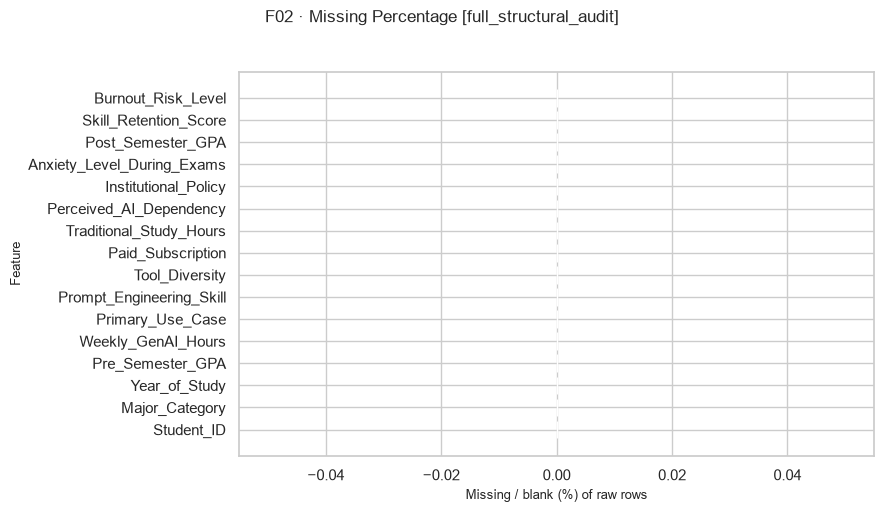

**T08 · Outlier Summary** — scope: `train`; 8 rows. 

,feature,valid_n,q1,q3,iqr,lower_fence,upper_fence,flagged_count,flagged_pct,p01,p99,reason,action
0,Pre_Semester_GPA,35000,2.8360,3.5210,0.6850,1.8085,4.5485,234.0,0.6686,1.8830,3.9200,,retain; investigate; no automatic deletion
1,Weekly_GenAI_Hours,35000,2.3900,11.6925,9.3025,-11.5637,25.6462,1832.0,5.2343,0.0900,38.6205,,retain; investigate; no automatic deletion
2,Tool_Diversity,35000,2.0000,4.0000,2.0000,-1.0000,7.0000,NaN,NaN,1.0000,5.0000,"IQR not meaningful: discrete/ordinal, constant...",retain; investigate; no automatic deletion
3,Traditional_Study_Hours,35000,7.5200,14.7100,7.1900,-3.2650,25.4950,107.0,0.3057,1.0000,23.3400,,retain; investigate; no automatic deletion
4,Perceived_AI_Dependency,35000,2.0000,5.0000,3.0000,-2.5000,9.5000,NaN,NaN,1.0000,9.0000,"IQR not meaningful: discrete/ordinal, constant...",retain; investigate; no automatic deletion
5,Anxiety_Level_During_Exams,35000,3.0000,6.0000,3.0000,-1.5000,10.5000,NaN,NaN,1.0000,10.0000,"IQR not meaningful: discrete/ordinal, constant...",retain; investigate; no automatic deletion
6,Post_Semester_GPA,35000,3.0230,3.7490,0.7260,1.9340,4.8380,237.0,0.6771,2.0190,4.0000,,retain; investigate; no automatic deletion
7,Skill_Retention_Score,35000,66.8175,85.1100,18.2925,39.3787,112.5488,156.0,0.4457,43.8798,100.0000,,retain; investigate; no automatic deletion


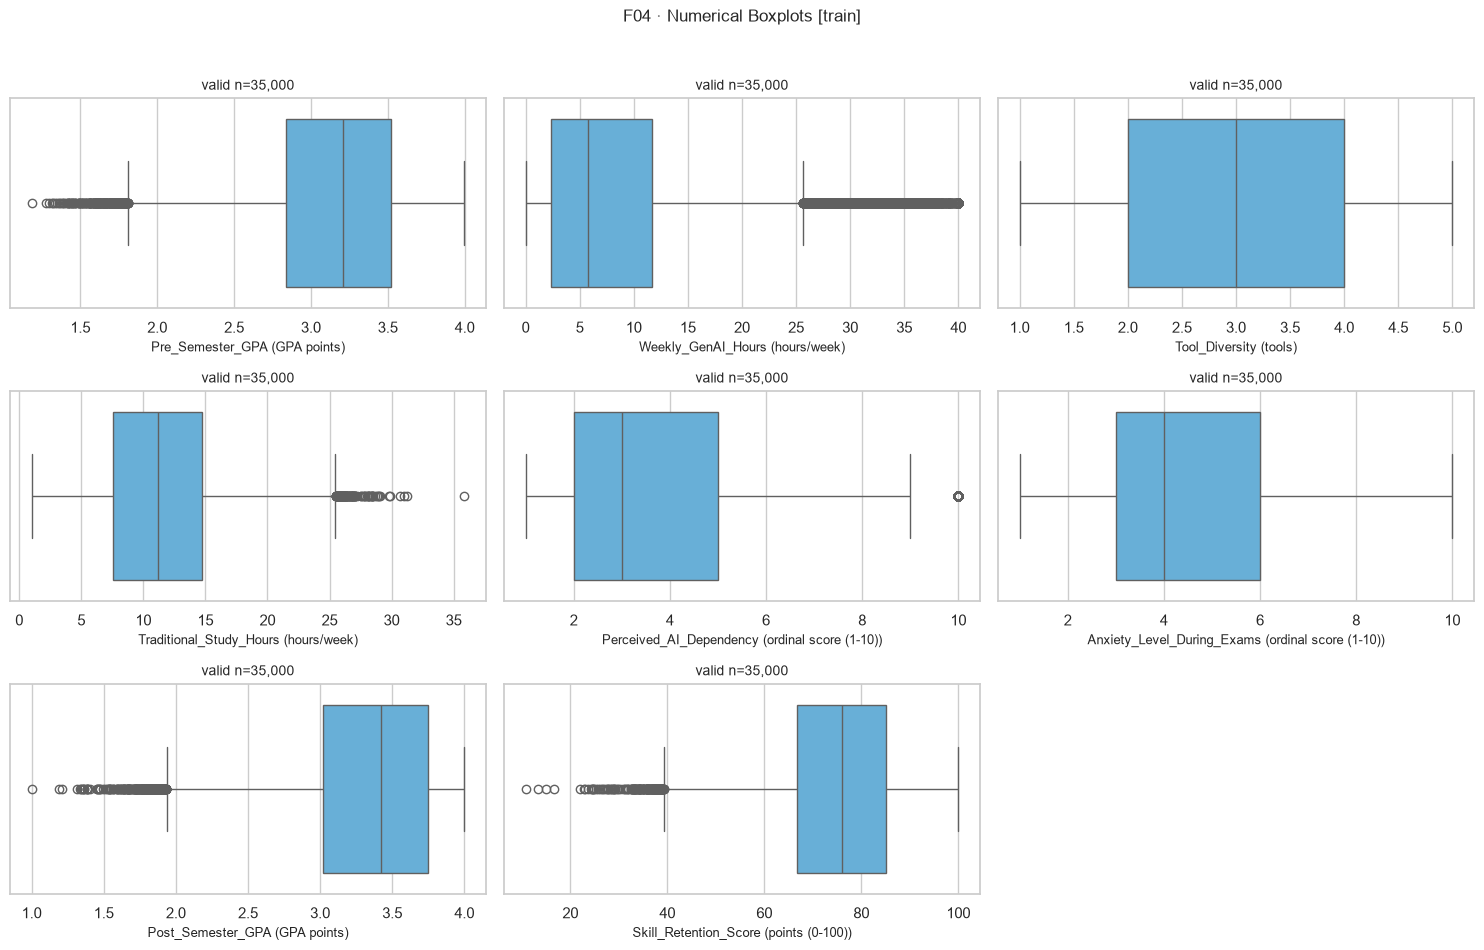

IQR fences are train-only heuristics. Valid extreme observations are retained.

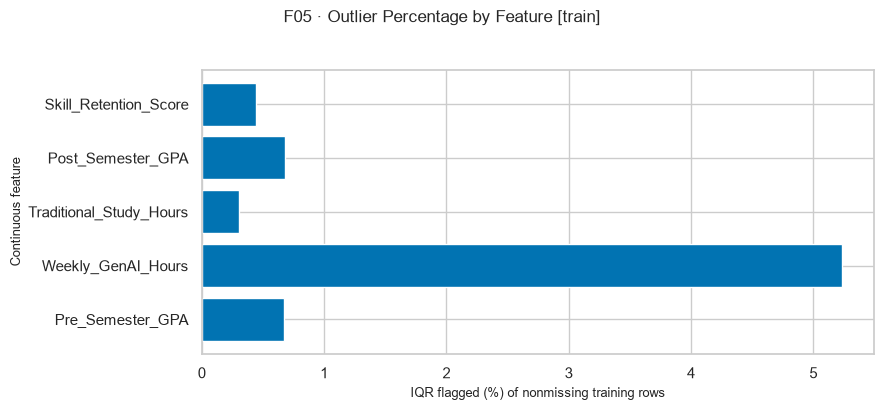

**Implication.** 2,566 feature-level IQR flags (không phải số sinh viên duy nhất). Giữ dữ liệu hợp lệ; imputer/encoder chỉ fit train. Không áp IQR máy móc cho ordinal/count hoặc biến có IQR=0.

In [5]:
fig, ax = plt.subplots(figsize=(9,5))
ax.barh(missing_table.feature, missing_table.missing_pct)
ax.set(xlabel='Missing / blank (%) of raw rows',ylabel='Feature')
save_figure('F02',fig,'full_structural_audit')
if train.isna().any().any():
    fig,ax=plt.subplots(figsize=(12,5))
    sns.heatmap(plot_sample(train.drop(columns=[ID_COLUMN],errors='ignore')).isna(),cbar=False,yticklabels=False,ax=ax)
    ax.set(xlabel='Feature',ylabel='Sampled training rows')
    save_figure('F03',fig,caption=f'Train-only sample, maximum n={PLOT_SAMPLE_SIZE}, seed={RANDOM_STATE}.')
else:
    skip('F03','No missing values in training data after documented cleaning')

outlier_rows=[]
for c in numeric_cols:
    s=train[c].dropna()
    q1,q3=s.quantile([.25,.75]) if len(s) else (np.nan,np.nan)
    iqr=q3-q1
    applicable=len(s)>3 and s.nunique()>2 and iqr>0 and semantic.get(c)=='continuous'
    lower,upper=q1-1.5*iqr,q3+1.5*iqr
    n_flag=int(((s<lower)|(s>upper)).sum()) if applicable else np.nan
    outlier_rows.append(dict(feature=c,valid_n=len(s),q1=q1,q3=q3,iqr=iqr,lower_fence=lower,upper_fence=upper,
        flagged_count=n_flag,flagged_pct=100*n_flag/len(s) if applicable else np.nan,
        p01=s.quantile(.01),p99=s.quantile(.99),
        reason='' if applicable else 'IQR not meaningful: discrete/ordinal, constant, missing, or IQR=0',action='retain; investigate; no automatic deletion'))
outlier_table=save_table('T08',outlier_rows)
fig,axes=axes_grid(len(numeric_cols))
for ax,c in zip(axes,numeric_cols):
    sns.boxplot(x=train[c],ax=ax,color='#56B4E9')
    ax.set(xlabel=f'{c} ({units[c]})',title=f'valid n={train[c].notna().sum():,}')
save_figure('F04',fig,caption='IQR fences are train-only heuristics. Valid extreme observations are retained.')
fig,ax=plt.subplots(figsize=(9,4))
valid_outliers=outlier_table.dropna(subset=['flagged_pct'])
ax.barh(valid_outliers.feature,valid_outliers.flagged_pct)
ax.set(xlabel='IQR flagged (%) of nonmissing training rows',ylabel='Continuous feature')
save_figure('F05',fig)
note(f'**Implication.** {int(outlier_table.flagged_count.fillna(0).sum()):,} feature-level IQR flags (không phải số sinh viên duy nhất). '
     'Giữ dữ liệu hợp lệ; imputer/encoder chỉ fit train. Không áp IQR máy móc cho ordinal/count hoặc biến có IQR=0.')

## Section 4 — Descriptive Statistics

**Method.** Toàn bộ thống kê dưới đây chỉ dùng **train**. Numerical sample variance/std dùng `ddof=1`;
skewness là pandas adjusted Fisher–Pearson và kurtosis là **excess Fisher** (normal = 0).
Ordinal scales được trình bày thêm bằng tần suất; nominal không có mean.
Percentage của category dùng tổng số dòng train, bao gồm missing như một nhóm riêng.

In [6]:
numeric_stats=[]
for c in numeric_cols:
    s=train[c].dropna()
    numeric_stats.append(dict(feature=c,semantic_type=semantic[c],valid_n=len(s),missing_pct=100*train[c].isna().mean(),
        mean=s.mean(),median=s.median(),mode=s.mode().iloc[0] if semantic[c]=='discrete' and len(s.mode()) else np.nan,
        std=s.std(ddof=1),variance=s.var(ddof=1),minimum=s.min(),maximum=s.max(),range=s.max()-s.min(),
        q1=s.quantile(.25),q3=s.quantile(.75),iqr=s.quantile(.75)-s.quantile(.25),
        p01=s.quantile(.01),p05=s.quantile(.05),p95=s.quantile(.95),p99=s.quantile(.99),
        skewness=s.skew(),excess_kurtosis=s.kurt(),
        limitation='ordinal numeric summaries assume coding distances; use frequencies for interpretation' if semantic[c]=='ordinal' else ''))
numerical_summary=save_table('T10',numeric_stats)
frequency_cols=list(dict.fromkeys(categorical_cols+ordinal_cols+[c for c in raw if c not in semantic]))
category_summary,frequency_rows=[],[]
for c in frequency_cols:
    counts=train[c].astype('string').fillna('<missing>').value_counts(dropna=False)
    category_summary.append(dict(feature=c,valid_n=int(train[c].notna().sum()),unique_nonmissing=int(train[c].nunique()),
        mode=str(counts.index[0]),mode_n=int(counts.iloc[0]),least_frequent=str(counts.index[-1]),least_n=int(counts.iloc[-1]),
        missing_pct=100*train[c].isna().mean(),rare_groups=int((counts<MIN_GROUP_SIZE).sum()),denominator=len(train)))
    frequency_rows.extend(dict(feature=c,category=str(level),count=int(n),percentage=100*n/len(train),
        denominator=len(train),small_group=bool(n<MIN_GROUP_SIZE)) for level,n in counts.items())
save_table('T11',category_summary)
frequencies=save_table('T12',frequency_rows,caption='Denominator = all training rows, including a missing group.')
save_table('T13',numerical_summary[['feature','valid_n','skewness','excess_kurtosis','std','iqr','p01','p99','limitation']])
note('**Interpretation.** T10–T13 là cơ sở cho missing handling và encoding. Mean của rating ordinal chỉ mô tả coding, '
     'không chứng minh khoảng cách tâm lý bằng nhau. Predictor không cần phân phối chuẩn để OLS hợp lệ.')

**T10 · Numerical Descriptive Statistics** — scope: `train`; 8 rows. 

,feature,semantic_type,valid_n,missing_pct,mean,median,mode,...,p01,p05,p95,p99,skewness,excess_kurtosis,limitation
0,Pre_Semester_GPA,continuous,35000,0.0,3.1469,3.211,NaN,...,1.8830,2.256,3.812,3.9200,-0.6118,-0.0803,
1,Weekly_GenAI_Hours,continuous,35000,0.0,8.4366,5.800,NaN,...,0.0900,0.420,26.060,38.6205,1.6062,2.5251,
2,Tool_Diversity,discrete,35000,0.0,2.8027,3.000,3.0,...,1.0000,1.000,5.000,5.0000,0.1689,-0.7482,
3,Traditional_Study_Hours,continuous,35000,0.0,11.1957,11.180,NaN,...,1.0000,2.470,19.760,23.3400,0.1241,-0.3199,
4,Perceived_AI_Dependency,ordinal,35000,0.0,3.5019,3.000,NaN,...,1.0000,1.000,7.000,9.0000,0.6587,0.2722,ordinal numeric summaries assume coding distan...
5,Anxiety_Level_During_Exams,ordinal,35000,0.0,4.2768,4.000,NaN,...,1.0000,1.000,8.000,10.0000,0.3633,-0.4057,ordinal numeric summaries assume coding distan...
6,Post_Semester_GPA,continuous,35000,0.0,3.3496,3.424,NaN,...,2.0190,2.427,4.000,4.0000,-0.6850,-0.0106,
7,Skill_Retention_Score,continuous,35000,0.0,75.8046,75.990,NaN,...,43.8798,53.370,98.870,100.0000,-0.2166,-0.1929,


**T11 · Categorical Descriptive Statistics** — scope: `train`; 9 rows. 

,feature,valid_n,unique_nonmissing,mode,mode_n,least_frequent,least_n,missing_pct,rare_groups,denominator
0,Major_Category,35000,5,STEM,10508,Arts,4204,0.0,0,35000
1,Year_of_Study,35000,5,Junior,7733,Graduate,5204,0.0,0,35000
2,Primary_Use_Case,35000,5,Debugging/Troubleshooting,8581,Direct_Answer_Generation,4418,0.0,0,35000
3,Prompt_Engineering_Skill,35000,3,Beginner,12925,Advanced,9647,0.0,0,35000
4,Paid_Subscription,35000,2,False,20155,True,14845,0.0,0,35000
5,Institutional_Policy,35000,3,Allowed_With_Citation,17658,Strict_Ban,6869,0.0,0,35000
6,Burnout_Risk_Level,35000,3,Medium,14830,High,8697,0.0,0,35000
7,Perceived_AI_Dependency,35000,10,3.0,7308,10.0,138,0.0,0,35000
8,Anxiety_Level_During_Exams,35000,10,4.0,6083,10.0,447,0.0,0,35000


**T12 · Category Frequency Distribution** — scope: `train`; 46 rows. Denominator = all training rows, including a missing group.

,feature,category,count,percentage,denominator,small_group
0,Major_Category,STEM,10508,30.0229,35000,False
1,Major_Category,Business,8753,25.0086,35000,False
2,Major_Category,Humanities,7024,20.0686,35000,False
3,Major_Category,Medical,4511,12.8886,35000,False
4,Major_Category,Arts,4204,12.0114,35000,False
5,Year_of_Study,Junior,7733,22.0943,35000,False
6,Year_of_Study,Freshman,7700,22.0000,35000,False
7,Year_of_Study,Senior,7431,21.2314,35000,False
8,Year_of_Study,Sophomore,6932,19.8057,35000,False
9,Year_of_Study,Graduate,5204,14.8686,35000,False


**T13 · Distribution Characteristics and Skewness** — scope: `train`; 8 rows. 

,feature,valid_n,skewness,excess_kurtosis,std,iqr,p01,p99,limitation
0,Pre_Semester_GPA,35000,-0.6118,-0.0803,0.4791,0.6850,1.8830,3.9200,
1,Weekly_GenAI_Hours,35000,1.6062,2.5251,8.2825,9.3025,0.0900,38.6205,
2,Tool_Diversity,35000,0.1689,-0.7482,1.1912,2.0000,1.0000,5.0000,
3,Traditional_Study_Hours,35000,0.1241,-0.3199,5.1529,7.1900,1.0000,23.3400,
4,Perceived_AI_Dependency,35000,0.6587,0.2722,1.8214,3.0000,1.0000,9.0000,ordinal numeric summaries assume coding distan...
5,Anxiety_Level_During_Exams,35000,0.3633,-0.4057,2.1491,3.0000,1.0000,10.0000,ordinal numeric summaries assume coding distan...
6,Post_Semester_GPA,35000,-0.6850,-0.0106,0.4965,0.7260,2.0190,4.0000,
7,Skill_Retention_Score,35000,-0.2166,-0.1929,13.2516,18.2925,43.8798,100.0000,


**Interpretation.** T10–T13 là cơ sở cho missing handling và encoding. Mean của rating ordinal chỉ mô tả coding, không chứng minh khoảng cách tâm lý bằng nhau. Predictor không cần phân phối chuẩn để OLS hợp lệ.

## Section 5 — Univariate Analysis

**Method.** Continuous: histogram/KDE/boxplot. Discrete, ordinal và binary: frequency bar, theo thứ tự được mô tả trong nguồn khi có.
KDE chỉ chạy với biến liên tục có ít nhất ba giá trị phân biệt. Auxiliary outcomes được mô tả, không dùng làm predictors.
Không xóa biến chỉ vì skewness hay IQR flag; transformations là ứng viên cần kiểm chứng.

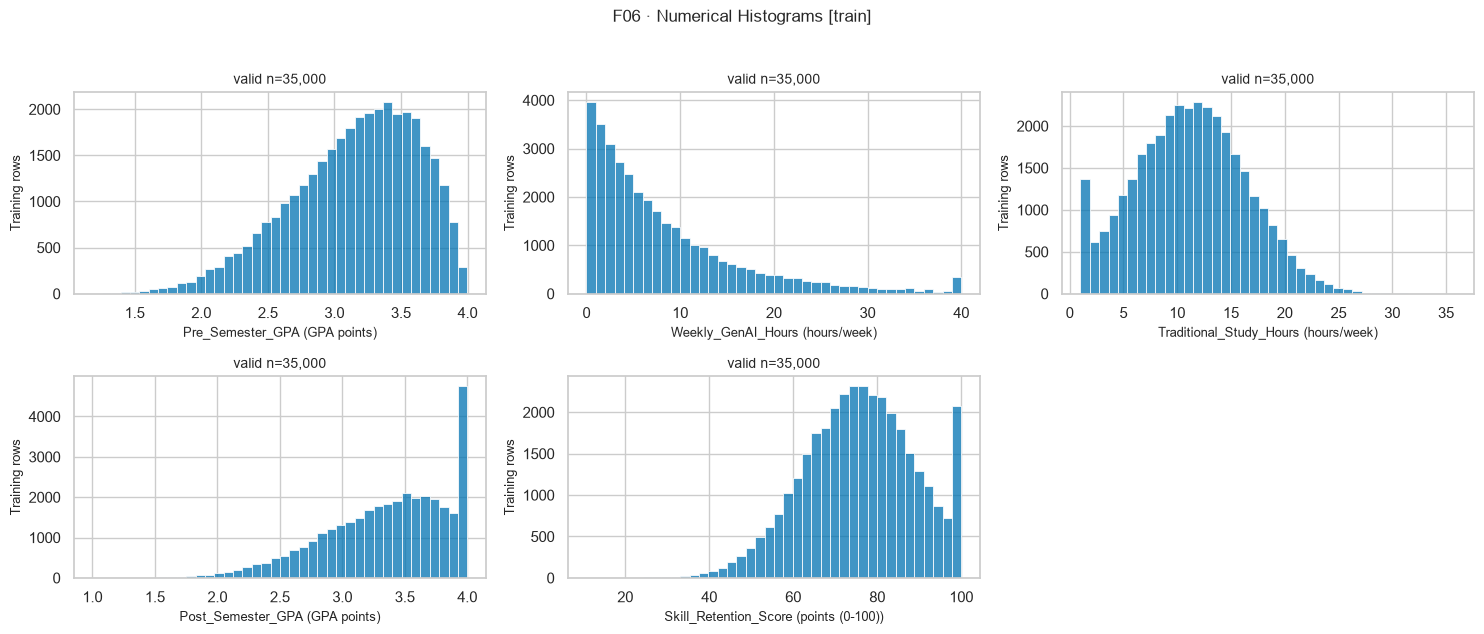

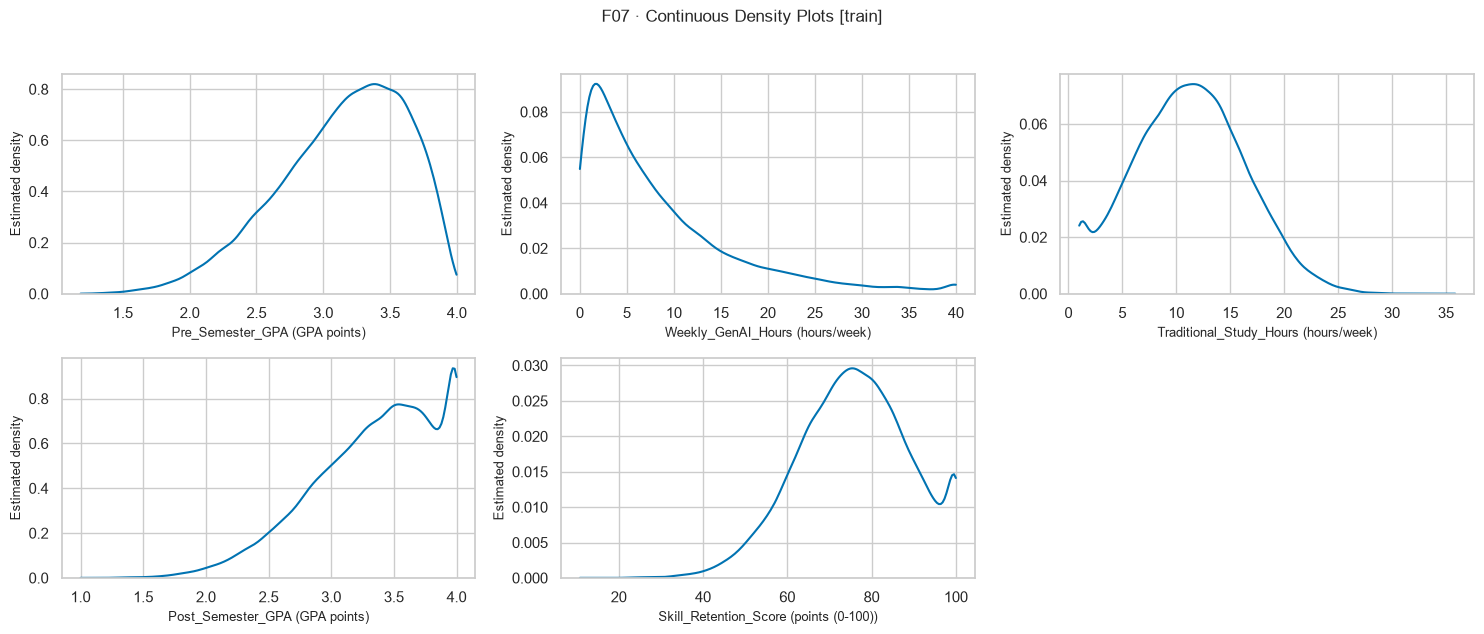

KDE is a descriptive smooth, not evidence of normality or a generating distribution.

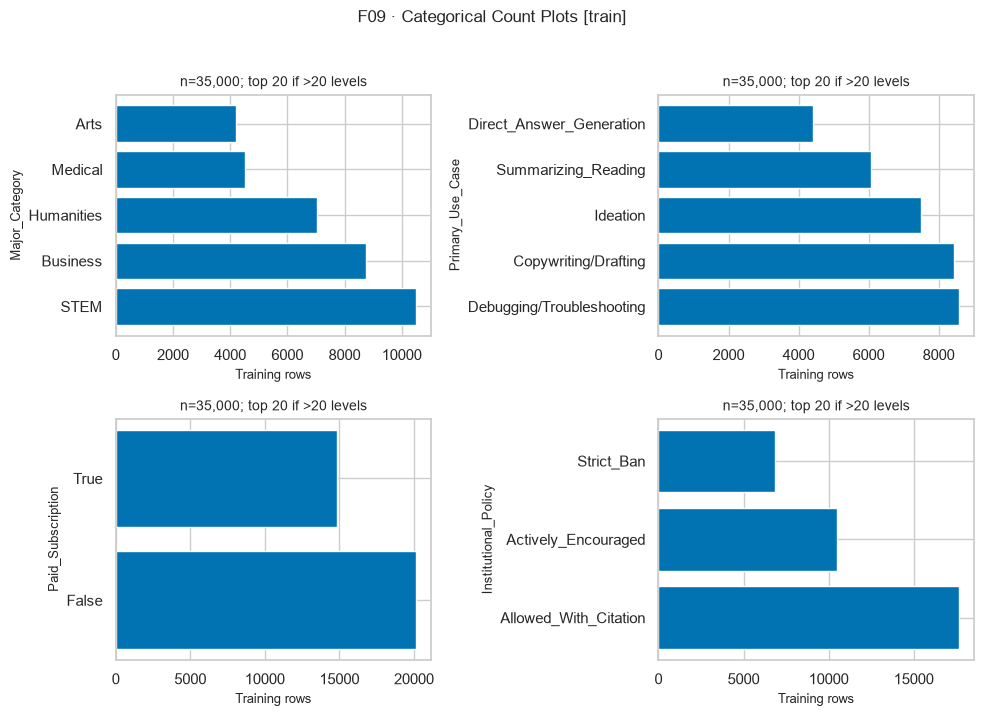

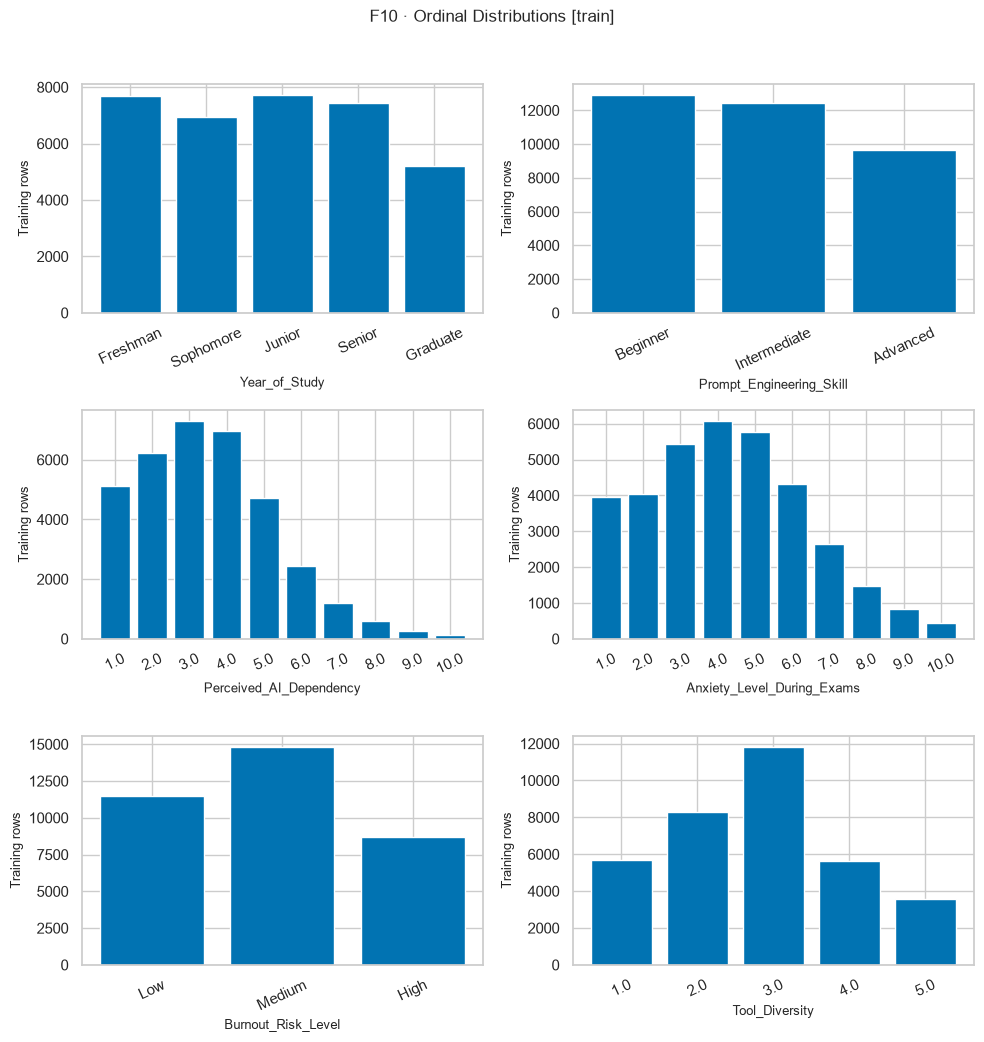

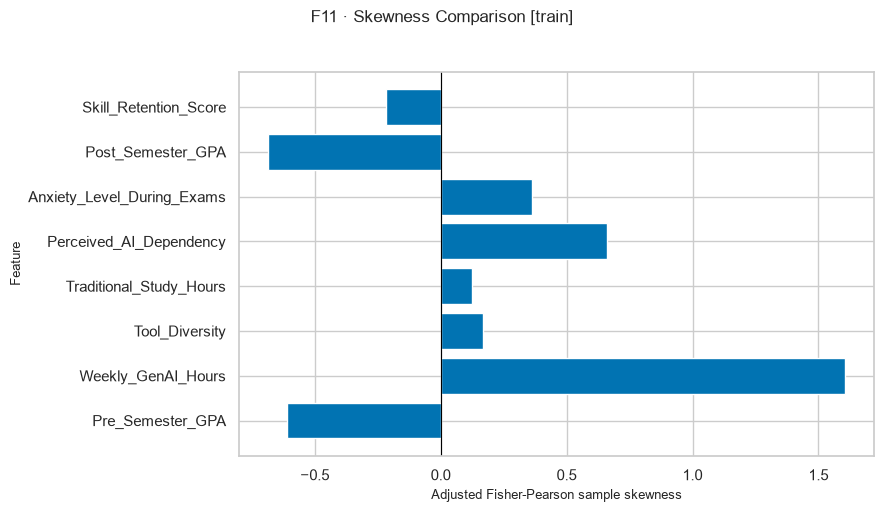

**Major_Category:** 5 nonmissing levels; largest group `STEM` n=10,508 (30.02%), missing=0.000%. Implication: one-hot for candidates; auxiliary/unknown columns excluded; flag rare groups. [T11/T12]

**Year_of_Study:** 5 nonmissing levels; largest group `Junior` n=7,733 (22.09%), missing=0.000%. Implication: one-hot for candidates; auxiliary/unknown columns excluded; flag rare groups. [T11/T12]

**Pre_Semester_GPA:** valid n=35,000, median=3.211, IQR=0.685, skew=-0.612, missing=0.000%. Implication: candidate; confirm availability; retain valid extremes; median imputation fit on train if needed.

**Weekly_GenAI_Hours:** valid n=35,000, median=5.8, IQR=9.302, skew=1.606, missing=0.000%. Implication: candidate; confirm availability; retain valid extremes; median imputation fit on train if needed.

**Primary_Use_Case:** 5 nonmissing levels; largest group `Debugging/Troubleshooting` n=8,581 (24.52%), missing=0.000%. Implication: one-hot for candidates; auxiliary/unknown columns excluded; flag rare groups. [T11/T12]

**Prompt_Engineering_Skill:** 3 nonmissing levels; largest group `Beginner` n=12,925 (36.93%), missing=0.000%. Implication: one-hot for candidates; auxiliary/unknown columns excluded; flag rare groups. [T11/T12]

... (5 outputs left out)

**Anxiety_Level_During_Exams:** valid n=35,000, median=4, IQR=3, skew=0.363, missing=0.000%. Implication: candidate; confirm availability; one-hot ordinal coding; no automatic log transform.

**Post_Semester_GPA:** valid n=35,000, median=3.424, IQR=0.726, skew=-0.685, missing=0.000%. Implication: primary target; retain valid extremes; median imputation fit on train if needed.

**Skill_Retention_Score:** valid n=35,000, median=75.99, IQR=18.29, skew=-0.217, missing=0.000%. Implication: auxiliary outcome, exclude from X; retain valid extremes; median imputation fit on train if needed.

**Burnout_Risk_Level:** 3 nonmissing levels; largest group `Medium` n=14,830 (42.37%), missing=0.000%. Implication: one-hot for candidates; auxiliary/unknown columns excluded; flag rare groups. [T11/T12]

In [7]:
fig,axes=axes_grid(len(continuous_cols))
for ax,c in zip(axes,continuous_cols):
    sns.histplot(train[c].dropna(),bins=40,ax=ax,color='#0072B2')
    ax.set(xlabel=f'{c} ({units[c]})',ylabel='Training rows',title=f'valid n={train[c].notna().sum():,}')
save_figure('F06',fig)
kde_cols=[c for c in continuous_cols if train[c].nunique()>=3 and train[c].notna().sum()>=10]
if kde_cols:
    fig,axes=axes_grid(len(kde_cols))
    for ax,c in zip(axes,kde_cols):
        sns.kdeplot(x=train[c].dropna(),ax=ax,cut=0)
        ax.set(xlabel=f'{c} ({units[c]})',ylabel='Estimated density')
    save_figure('F07',fig,caption='KDE is a descriptive smooth, not evidence of normality or a generating distribution.')
else:
    skip('F07','No continuous feature has sufficient distinct observations for KDE')
reuse('F08','F04')
nominal_plot_cols=[c for c in frequency_cols if c not in ordinal_cols]
if nominal_plot_cols:
    fig,axes=axes_grid(len(nominal_plot_cols),columns=2,height=3.5)
    for ax,c in zip(axes,nominal_plot_cols):
        counts=train[c].astype('string').fillna('<missing>').value_counts().head(20)
        ax.barh(counts.index.astype(str),counts.values)
        ax.set(xlabel='Training rows',ylabel=c,title=f'n={len(train):,}; top 20 if >20 levels')
    save_figure('F09',fig)
else:
    skip('F09','No nominal/binary/unknown feature')
ordered_plot_cols=list(dict.fromkeys(ordinal_cols+[c for c in numeric_cols if semantic[c]=='discrete']))
if ordered_plot_cols:
    fig,axes=axes_grid(len(ordered_plot_cols),columns=2,height=3.4)
    for ax,c in zip(axes,ordered_plot_cols):
        values=train[c].astype('string').fillna('<missing>')
        level_order=orders[c] if c in orders else sorted(values[values.ne('<missing>')].unique(), key=lambda v:float(v))
        level_order=list(level_order)+[v for v in values.unique() if v not in level_order]
        counts=values.value_counts().reindex(level_order,fill_value=0)
        ax.bar(counts.index.astype(str),counts.values)
        ax.tick_params(axis='x',rotation=25)
        ax.set(xlabel=c,ylabel='Training rows')
    save_figure('F10',fig)
else:
    skip('F10','No ordinal or discrete columns')
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(numerical_summary.feature,numerical_summary.skewness)
ax.axvline(0,color='black',lw=.8)
ax.set(xlabel='Adjusted Fisher-Pearson sample skewness',ylabel='Feature')
save_figure('F11',fig)
for c in raw:
    if c==ID_COLUMN:
        continue
    missing_pct=100*train[c].isna().mean()
    if c in numeric_cols:
        s=train[c].dropna()
        role='auxiliary outcome, exclude from X' if c in auxiliary else 'primary target' if c==TARGET_COLUMN else 'candidate; confirm availability'
        note(f'**{c}:** valid n={len(s):,}, median={s.median():.4g}, IQR={s.quantile(.75)-s.quantile(.25):.4g}, '
             f'skew={s.skew():.3f}, missing={missing_pct:.3f}%. Implication: {role}; '
             + ('one-hot ordinal coding; no automatic log transform.' if semantic[c]=='ordinal' else 'retain valid extremes; median imputation fit on train if needed.'))
    else:
        counts=train[c].astype('string').fillna('<missing>').value_counts()
        note(f'**{c}:** {train[c].nunique()} nonmissing levels; largest group `{counts.index[0]}` '
             f'n={counts.iloc[0]:,} ({100*counts.iloc[0]/len(train):.2f}%), missing={missing_pct:.3f}%. '
             'Implication: one-hot for candidates; auxiliary/unknown columns excluded; flag rare groups. [T11/T12]')

## Section 6 — Target Variable Analysis

**Method.** Post GPA và paired comparison chỉ trên train. `GPA_Change` dùng những dòng có cả hai GPA hợp lệ.
Improved/unchanged/declined dùng tolerance `1e-9` để chống sai số float, chưa phải ngưỡng thay đổi có ý nghĩa học thuật.
Nguồn ghi upper endpoint 4.0; không tự giả định floor. Pre GPA groups dùng quartiles train, ghi edges và bỏ duplicate edges.
GPA Change liên hệ cơ học với Pre GPA; cần cân nhắc mathematical coupling, regression to the mean và ceiling.

**T14 · Target Statistics** — scope: `train`; 8 rows. 

,statistic,value
0,count,35000.0000
1,mean,3.3496
2,std,0.4965
3,min,1.0000
4,25%,3.0230
5,50%,3.4240
6,75%,3.7490
7,max,4.0000


**T15 · GPA Change Statistics** — scope: `train`; 13 rows. 

,statistic,value
0,count,35000.0000
1,mean,0.2027
2,std,0.1879
3,min,-0.8980
4,25%,0.0860
5,50%,0.2040
6,75%,0.3250
7,max,0.9300
8,sample_std_ddof1,0.1879
9,paired_pearson,0.9264


**T16 · Improvement Summary** — scope: `train`; 3 rows. 

,status,count,percentage,denominator,tolerance
0,Improved,30575,87.3571,35000,1.0000e-09
1,Unchanged,36,0.1029,35000,1.0000e-09
2,Declined,4389,12.5400,35000,1.0000e-09


**T17 · GPA Change by Initial GPA Group** — scope: `train`; 4 rows. Quartiles fitted on train only; CI descriptive and assumes independence.

,feature,group,group_n,valid_n,mean,median,std,outcome,se,ci95_low,ci95_high,small_group,ci_method
0,Pre_GPA_Group,"(1.1820000000000002, 2.836]",8759,8759,0.2164,0.214,0.1948,GPA_Change,0.0021,0.2123,0.2205,False,t-based mean CI; independence not verified
1,Pre_GPA_Group,"(2.836, 3.211]",8757,8757,0.2175,0.219,0.2009,GPA_Change,0.0021,0.2133,0.2218,False,t-based mean CI; independence not verified
2,Pre_GPA_Group,"(3.211, 3.521]",8735,8735,0.2155,0.218,0.1933,GPA_Change,0.0021,0.2114,0.2195,False,t-based mean CI; independence not verified
3,Pre_GPA_Group,"(3.521, 3.998]",8749,8749,0.1613,0.170,0.1526,GPA_Change,0.0016,0.1581,0.1645,False,t-based mean CI; independence not verified


**T18 · GPA Boundary Concentration** — scope: `train`; 4 rows. 

,feature,boundary_type,boundary,count,percentage,valid_n,reason
0,Pre_Semester_GPA,upper,4.0,0.0,0.0000,35000,source-documented upper endpoint
1,Pre_Semester_GPA,lower,NaN,NaN,NaN,35000,theoretical lower boundary unverified; not inf...
2,Post_Semester_GPA,upper,4.0,3371.0,9.6314,35000,source-documented upper endpoint
3,Post_Semester_GPA,lower,NaN,NaN,NaN,35000,theoretical lower boundary unverified; not inf...


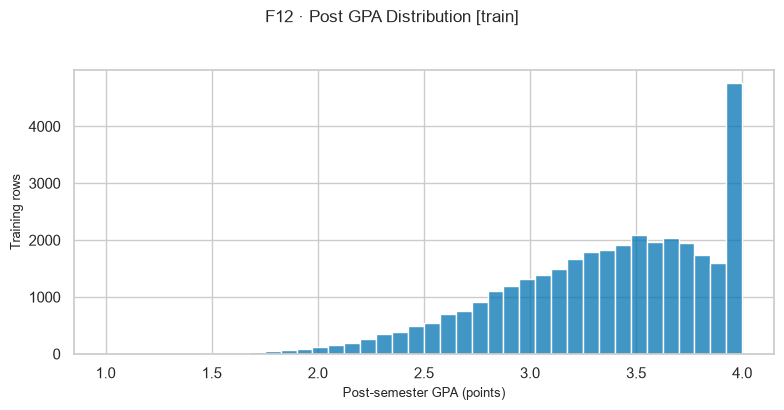

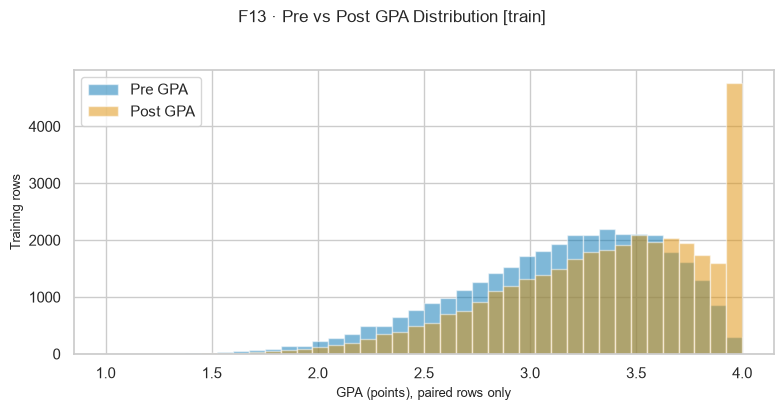

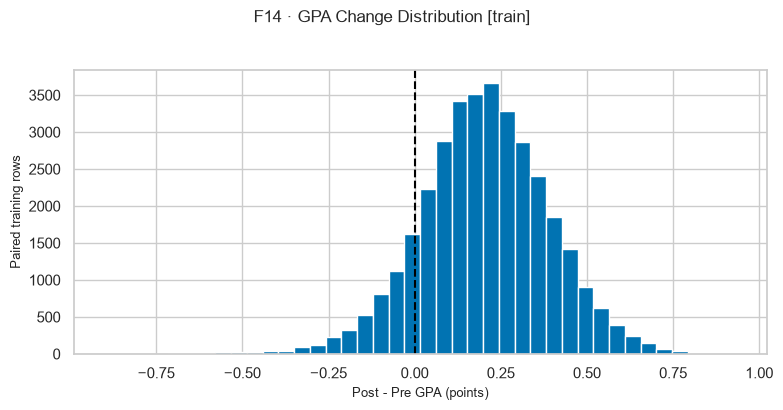

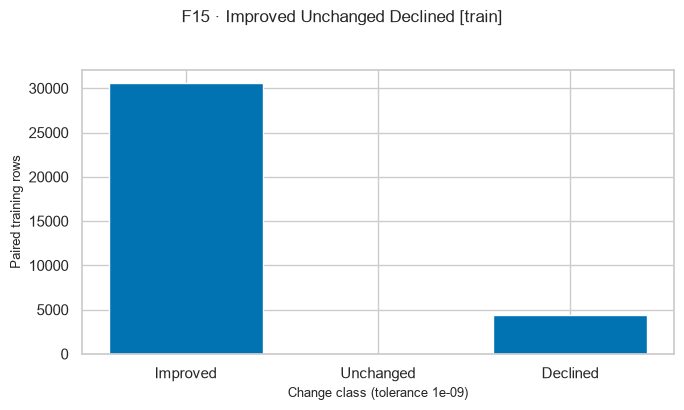

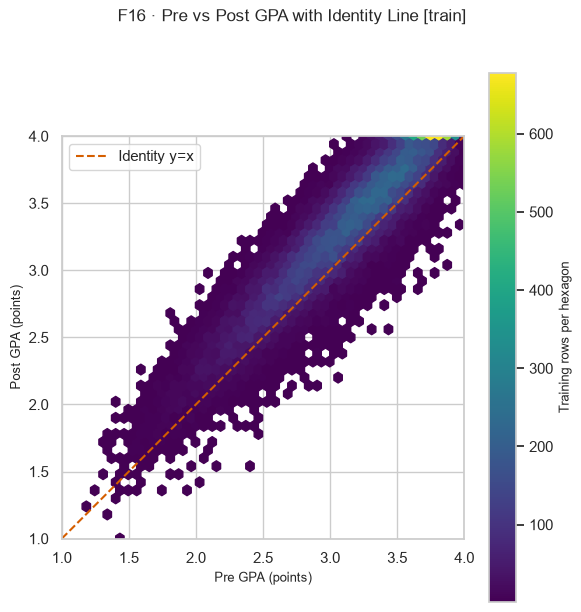

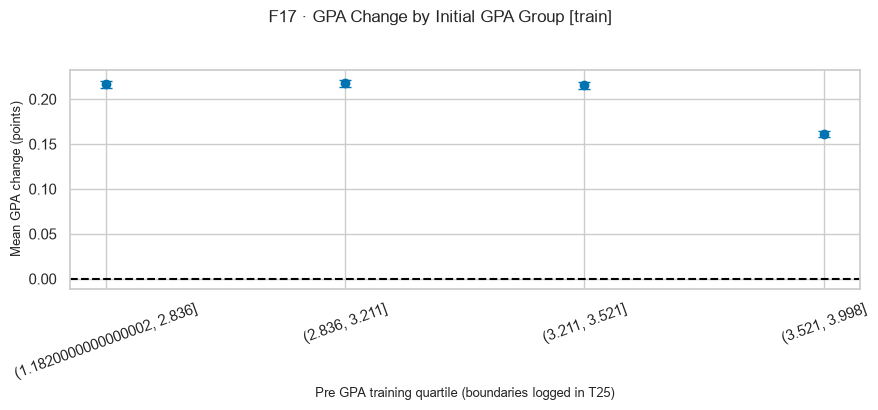

95% t-based CI; not a causal or independent effect of starting GPA.

**Evidence.** Paired n=35,000; mean change=0.2027, median=0.2040, sample std=0.1879. Improved=30,575, unchanged=36, declined=4,389. Đây là thay đổi quan sát trong dữ liệu synthetic, chưa quy được cho AI. [T15/T16/T18]

In [8]:
target_stats=train[TARGET_COLUMN].describe().rename_axis('statistic').reset_index(name='value')
save_table('T14',target_stats)
paired=train[['Pre_Semester_GPA',TARGET_COLUMN,'GPA_Change']].dropna()
change=paired.GPA_Change
change_stats=change.describe().rename_axis('statistic').reset_index(name='value')
change_stats.loc[len(change_stats)]=['sample_std_ddof1',change.std(ddof=1)]
for method in ['pearson','spearman']:
    record=safe_correlation(paired,'Pre_Semester_GPA',TARGET_COLUMN,method)
    change_stats.loc[len(change_stats)]=[f'paired_{method}',record['coefficient']]
change_stats.loc[len(change_stats)]=['paired_mean_pre',paired.Pre_Semester_GPA.mean()]
change_stats.loc[len(change_stats)]=['paired_mean_post',paired[TARGET_COLUMN].mean()]
save_table('T15',change_stats)
improvement=pd.Series(np.select([change>GPA_EQUAL_TOLERANCE,change < -GPA_EQUAL_TOLERANCE],['Improved','Declined'],default='Unchanged'),index=change.index)
improvement_counts=improvement.value_counts().reindex(['Improved','Unchanged','Declined'],fill_value=0)
save_table('T16',pd.DataFrame({'status':improvement_counts.index,'count':improvement_counts.values,
    'percentage':100*improvement_counts.values/len(change) if len(change) else np.nan,
    'denominator':len(change),'tolerance':GPA_EQUAL_TOLERANCE}))

bin_log=[]
def quantile_bins(frame,column,label,q=4):
    if frame[column].dropna().nunique()<2:
        warnings_log.append(f'{label}: fewer than 2 distinct values; bins undefined')
        return pd.Series(pd.NA,index=frame.index,dtype='string')
    binned,edges=pd.qcut(frame[column],q=q,duplicates='drop',retbins=True)
    bin_log.append(dict(label=label,feature=column,edges=json.dumps(edges.tolist()),method='train qcut; duplicate edges dropped',valid_n=int(frame[column].notna().sum())))
    return binned
train['Pre_GPA_Group']=quantile_bins(train,'Pre_Semester_GPA','Pre GPA quartiles')
pre_groups=summary_groups(train,'Pre_GPA_Group','GPA_Change')
save_table('T17',pre_groups,caption='Quartiles fitted on train only; CI descriptive and assumes independence.')
boundary_rows=[]
for c in ['Pre_Semester_GPA',TARGET_COLUMN]:
    for label,boundary in [('upper',GPA_UPPER_BOUNDARY),('lower',GPA_LOWER_BOUNDARY)]:
        valid=train[c].dropna()
        n=int(np.isclose(valid,boundary,atol=GPA_EQUAL_TOLERANCE,rtol=0).sum()) if boundary is not None else np.nan
        boundary_rows.append(dict(feature=c,boundary_type=label,boundary=boundary,count=n,
            percentage=100*n/len(valid) if len(valid) and boundary is not None else np.nan,valid_n=len(valid),
            reason='source-documented upper endpoint' if boundary is not None else 'theoretical lower boundary unverified; not inferred from sample minimum'))
boundary_table=save_table('T18',boundary_rows)

fig,ax=plt.subplots(figsize=(8,4))
sns.histplot(train[TARGET_COLUMN],bins=40,ax=ax)
ax.set(xlabel='Post-semester GPA (points)',ylabel='Training rows')
save_figure('F12',fig)
fig,ax=plt.subplots(figsize=(8,4))
if len(paired):
    common_bins=np.histogram_bin_edges(paired[['Pre_Semester_GPA',TARGET_COLUMN]].to_numpy().ravel(),bins=40)
    ax.hist(paired.Pre_Semester_GPA,bins=common_bins,alpha=.5,label='Pre GPA')
    ax.hist(paired[TARGET_COLUMN],bins=common_bins,alpha=.5,label='Post GPA')
    ax.legend()
ax.set(xlabel='GPA (points), paired rows only',ylabel='Training rows')
save_figure('F13',fig)
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(change,bins=40)
ax.axvline(0,color='black',ls='--')
ax.set(xlabel='Post - Pre GPA (points)',ylabel='Paired training rows')
save_figure('F14',fig)
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(improvement_counts.index,improvement_counts.values)
ax.set(xlabel=f'Change class (tolerance {GPA_EQUAL_TOLERANCE:g})',ylabel='Paired training rows')
save_figure('F15',fig)
if len(paired):
    fig,ax=plt.subplots(figsize=(6,6))
    h=ax.hexbin(paired.Pre_Semester_GPA,paired[TARGET_COLUMN],gridsize=45,mincnt=1,cmap='viridis')
    limits=[paired[['Pre_Semester_GPA',TARGET_COLUMN]].min().min(),paired[['Pre_Semester_GPA',TARGET_COLUMN]].max().max()]
    ax.plot(limits,limits,'r--',label='Identity y=x')
    ax.set(xlim=limits,ylim=limits,xlabel='Pre GPA (points)',ylabel='Post GPA (points)',aspect='equal')
    fig.colorbar(h,ax=ax,label='Training rows per hexagon')
    ax.legend()
    save_figure('F16',fig)
else:
    skip('F16','No complete paired GPA records')
fig,ax=plt.subplots(figsize=(9,4))
ax.errorbar(pre_groups['group'],pre_groups['mean'],yerr=[pre_groups['mean']-pre_groups.ci95_low,pre_groups.ci95_high-pre_groups['mean']],fmt='o',capsize=4)
ax.axhline(0,color='black',ls='--')
ax.set(xlabel='Pre GPA training quartile (boundaries logged in T25)',ylabel='Mean GPA change (points)')
ax.tick_params(axis='x',rotation=20)
save_figure('F17',fig,caption='95% t-based CI; not a causal or independent effect of starting GPA.')
note(f'**Evidence.** Paired n={len(change):,}; mean change={change.mean():.4f}, median={change.median():.4f}, '
     f'sample std={change.std(ddof=1):.4f}. Improved={improvement_counts["Improved"]:,}, '
     f'unchanged={improvement_counts["Unchanged"]:,}, declined={improvement_counts["Declined"]:,}. '
     'Đây là thay đổi quan sát trong dữ liệu synthetic, chưa quy được cho AI. [T15/T16/T18]')

## Section 7 — Bivariate Analysis

**Method.** Pearson cho quantitative; Spearman cho quantitative/ordinal có thứ tự đã được mô tả.
Nominal không được gán số để tính Pearson. Bảng ghi valid pair n và lý do N/A.
Predictor-only heatmaps loại ID, target và auxiliary outcomes. Auxiliary retention có bảng/hình riêng.
Group summaries báo n, mean, median, sample std và 95% t-based CI; CI có giả định independence chưa xác minh.
Không coi chênh lệch mean giữa nhóm là tác động AI; không screening chỉ bằng p-value.

**T19 · Pearson with Target** — scope: `train`; 8 rows. 

,feature,outcome,method,valid_n,coefficient,reason
0,Pre_Semester_GPA,Post_Semester_GPA,pearson,35000,0.9264,
1,Weekly_GenAI_Hours,Post_Semester_GPA,pearson,35000,-0.0191,
2,Tool_Diversity,Post_Semester_GPA,pearson,35000,0.0260,
3,Traditional_Study_Hours,Post_Semester_GPA,pearson,35000,0.1338,
4,Pre_Semester_GPA,GPA_Change,pearson,35000,-0.1020,
5,Weekly_GenAI_Hours,GPA_Change,pearson,35000,-0.0481,
6,Tool_Diversity,GPA_Change,pearson,35000,0.0827,
7,Traditional_Study_Hours,GPA_Change,pearson,35000,0.3775,


**T20 · Spearman with Target** — scope: `train`; 16 rows. Documented ordinal order used for ranks only; no interval-distance assumption.

,feature,outcome,method,valid_n,coefficient,reason
0,Pre_Semester_GPA,Post_Semester_GPA,spearman,35000,0.9160,
1,Weekly_GenAI_Hours,Post_Semester_GPA,spearman,35000,0.0079,
2,Tool_Diversity,Post_Semester_GPA,spearman,35000,0.0300,
3,Traditional_Study_Hours,Post_Semester_GPA,spearman,35000,0.1367,
4,Perceived_AI_Dependency,Post_Semester_GPA,spearman,35000,-0.0094,
5,Anxiety_Level_During_Exams,Post_Semester_GPA,spearman,35000,-0.0135,
6,Year_of_Study,Post_Semester_GPA,spearman,35000,0.0840,
7,Prompt_Engineering_Skill,Post_Semester_GPA,spearman,35000,0.0411,
8,Pre_Semester_GPA,GPA_Change,spearman,35000,-0.1151,
9,Weekly_GenAI_Hours,GPA_Change,spearman,35000,0.0313,


**T21 · Categorical vs Target Summary** — scope: `train`; 86 rows. 

,feature,group,group_n,valid_n,mean,median,std,outcome,se,ci95_low,ci95_high,small_group,ci_method
0,Major_Category,Arts,4204,4204,3.3472,3.420,0.4955,Post_Semester_GPA,0.0076,3.3322,3.3622,False,t-based mean CI; independence not verified
1,Major_Category,Business,8753,8753,3.3369,3.410,0.4990,Post_Semester_GPA,0.0053,3.3264,3.3473,False,t-based mean CI; independence not verified
2,Major_Category,Humanities,7024,7024,3.3449,3.412,0.4956,Post_Semester_GPA,0.0059,3.3333,3.3565,False,t-based mean CI; independence not verified
3,Major_Category,Medical,4511,4511,3.3507,3.426,0.4930,Post_Semester_GPA,0.0073,3.3363,3.3651,False,t-based mean CI; independence not verified
4,Major_Category,STEM,10508,10508,3.3639,3.444,0.4966,Post_Semester_GPA,0.0048,3.3544,3.3734,False,t-based mean CI; independence not verified
5,Major_Category,Arts,4204,4204,0.1969,0.202,0.1831,GPA_Change,0.0028,0.1913,0.2024,False,t-based mean CI; independence not verified
6,Major_Category,Business,8753,8753,0.1935,0.194,0.1831,GPA_Change,0.0020,0.1896,0.1973,False,t-based mean CI; independence not verified
7,Major_Category,Humanities,7024,7024,0.2002,0.199,0.1770,GPA_Change,0.0021,0.1960,0.2043,False,t-based mean CI; independence not verified
8,Major_Category,Medical,4511,4511,0.1997,0.201,0.1816,GPA_Change,0.0027,0.1944,0.2050,False,t-based mean CI; independence not verified
9,Major_Category,STEM,10508,10508,0.2156,0.216,0.2023,GPA_Change,0.0020,0.2117,0.2195,False,t-based mean CI; independence not verified


**T22 · Group Difference Summary** — scope: `train`; 16 rows. 

,feature,outcome,groups,largest_mean_group,smallest_mean_group,mean_range,small_groups,test_status,limitation
0,Major_Category,Post_Semester_GPA,5,STEM,Business,0.0271,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
1,Major_Category,GPA_Change,5,STEM,Business,0.0221,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
2,Year_of_Study,Post_Semester_GPA,5,Senior,Freshman,0.1112,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
3,Year_of_Study,GPA_Change,5,Graduate,Freshman,0.1208,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
4,Primary_Use_Case,Post_Semester_GPA,5,Debugging/Troubleshooting,Direct_Answer_Generation,0.1025,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
5,Primary_Use_Case,GPA_Change,5,Debugging/Troubleshooting,Direct_Answer_Generation,0.1153,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
6,Prompt_Engineering_Skill,Post_Semester_GPA,3,Advanced,Intermediate,0.0546,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
7,Prompt_Engineering_Skill,GPA_Change,3,Advanced,Beginner,0.0635,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
8,Paid_Subscription,Post_Semester_GPA,2,True,False,0.0034,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."
9,Paid_Subscription,GPA_Change,2,True,False,0.0074,0,not run; optional tests disabled,"unadjusted association; CIs descriptive, multi..."


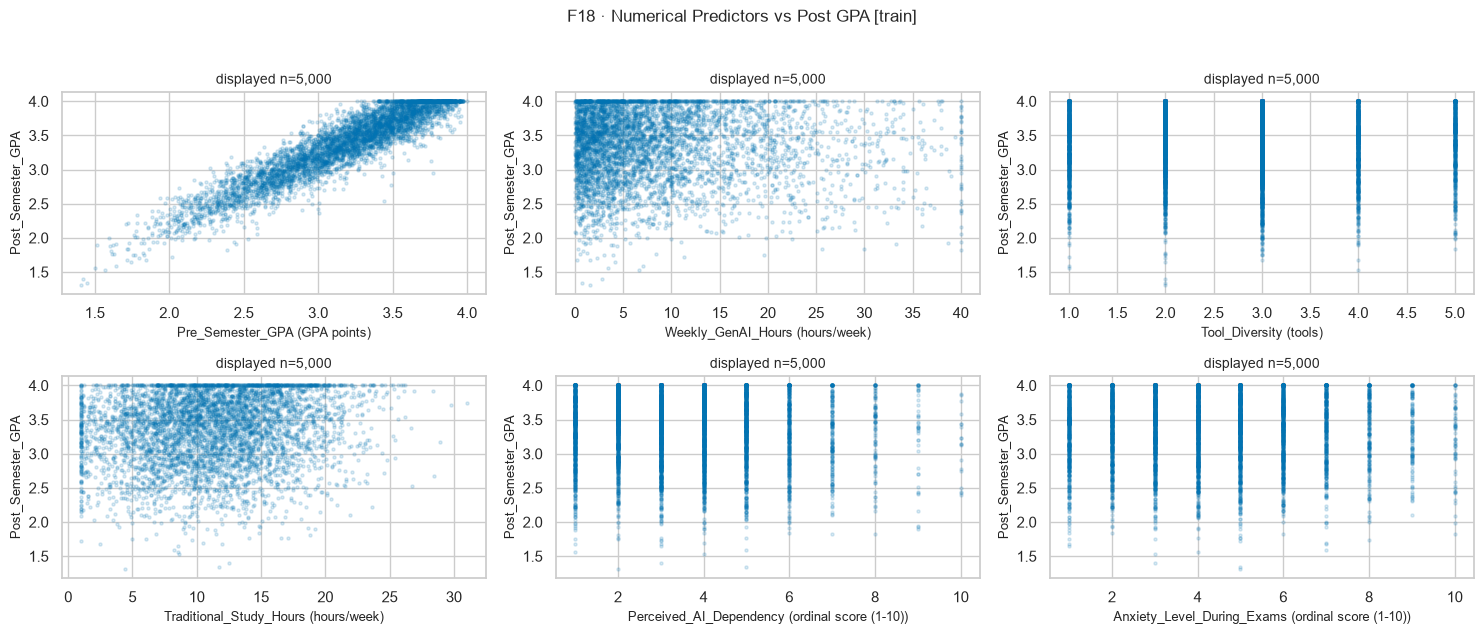

Plots sampled at most 5,000, seed 42; correlations use all valid train pairs.

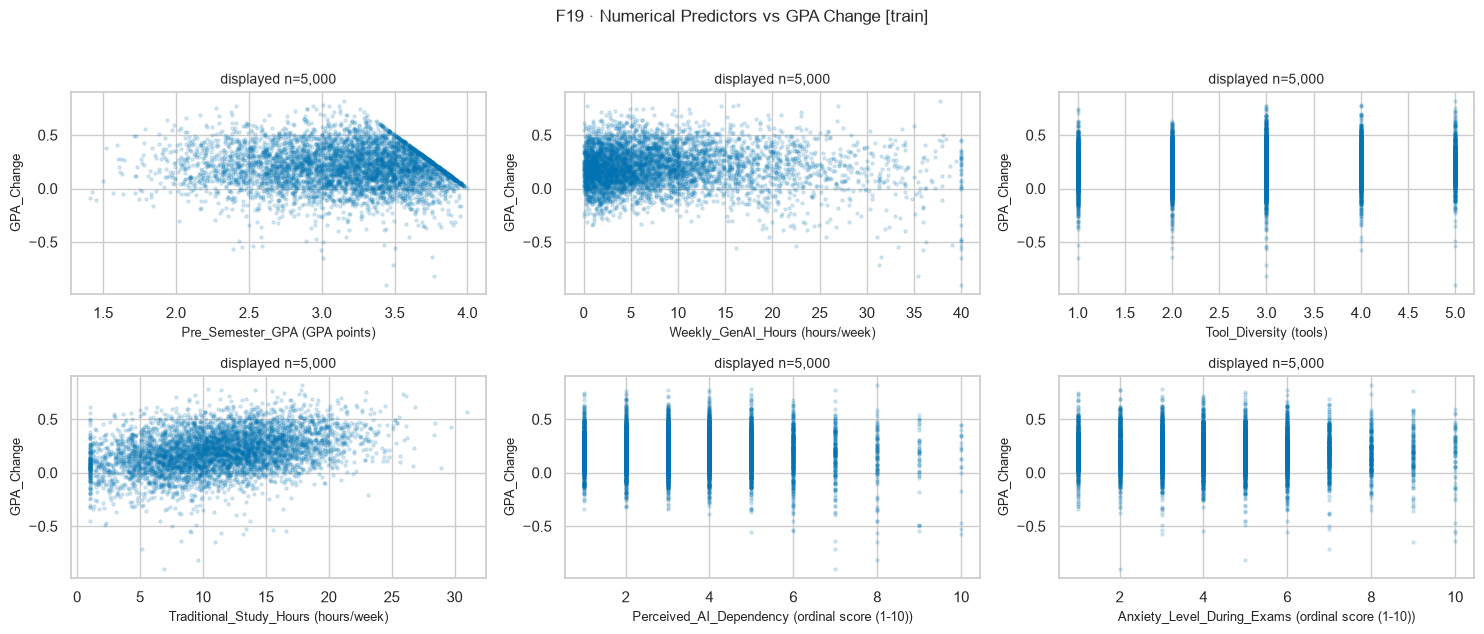

Plots sampled at most 5,000, seed 42; correlations use all valid train pairs.

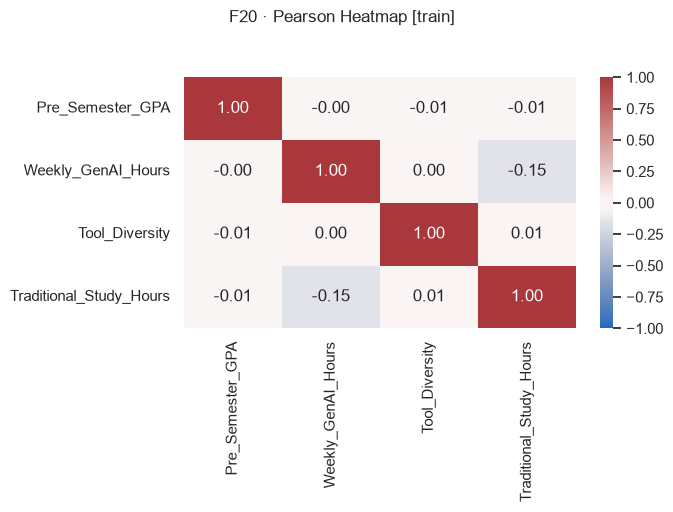

Predictors only; target and auxiliary outcomes excluded. Pair counts available from train missingness and T19 for target pairs.

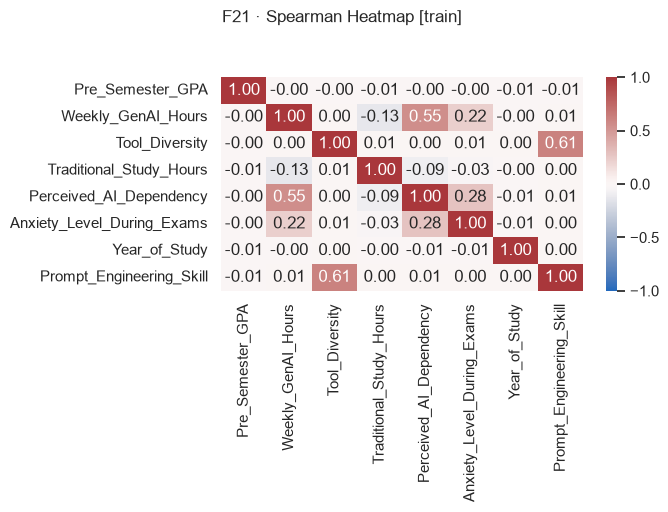

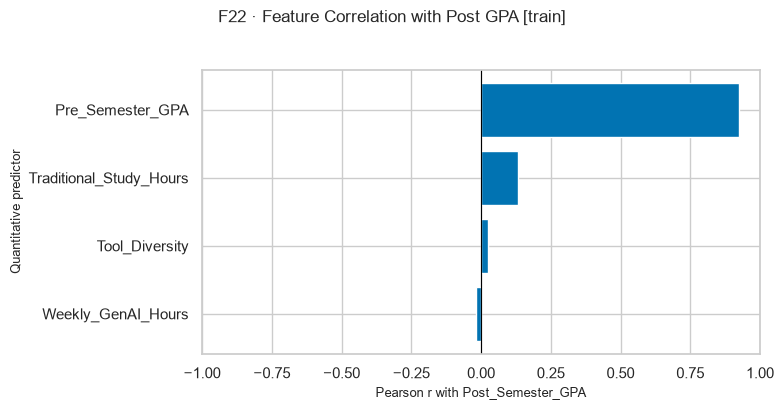

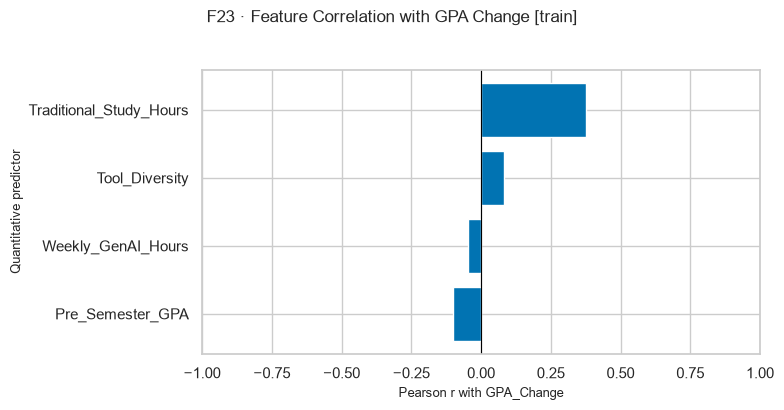

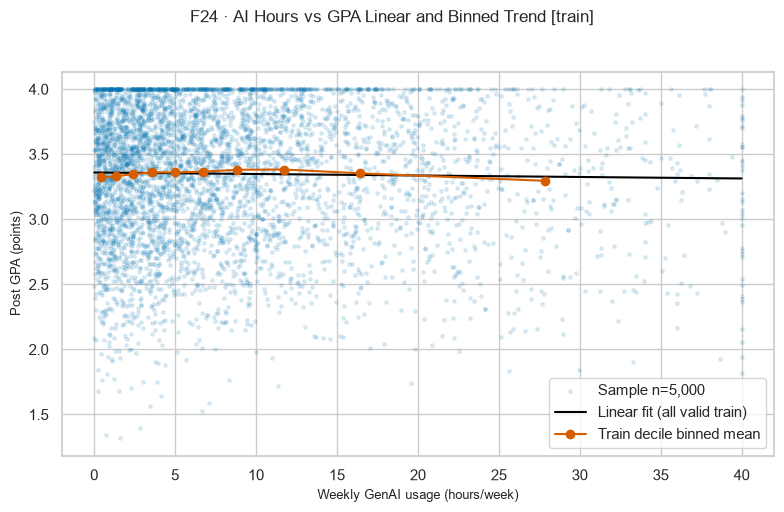

Binned smoother avoids expensive full-data LOWESS. Marginal association, without academic adjustment.

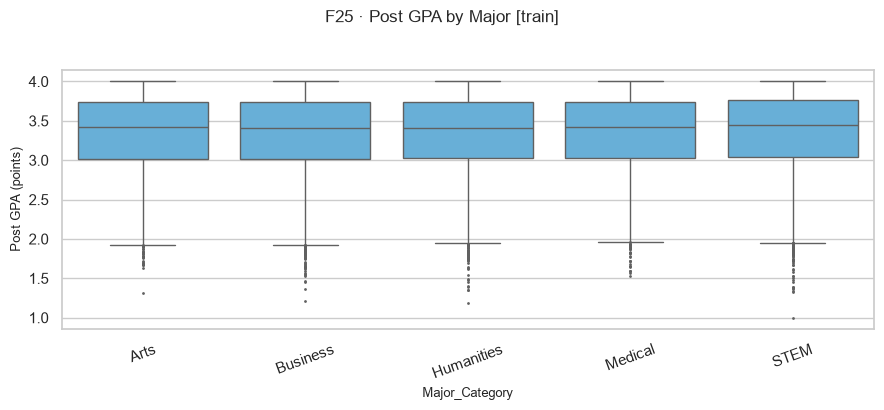

Valid group n and small-group flags in T21; marginal comparison only.

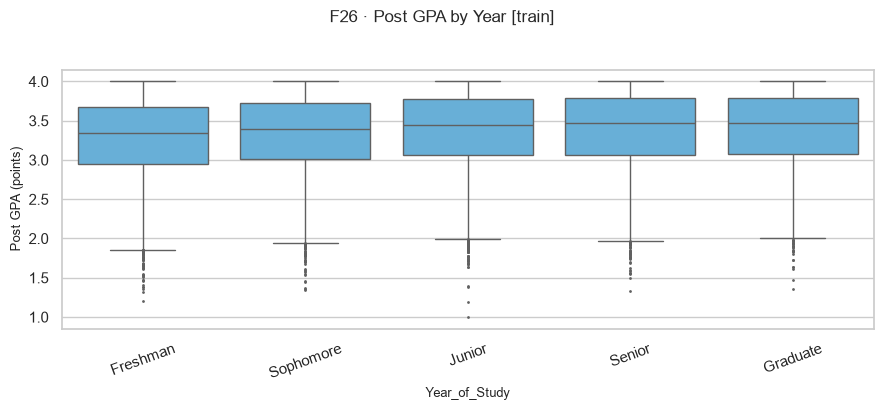

Valid group n and small-group flags in T21; marginal comparison only.

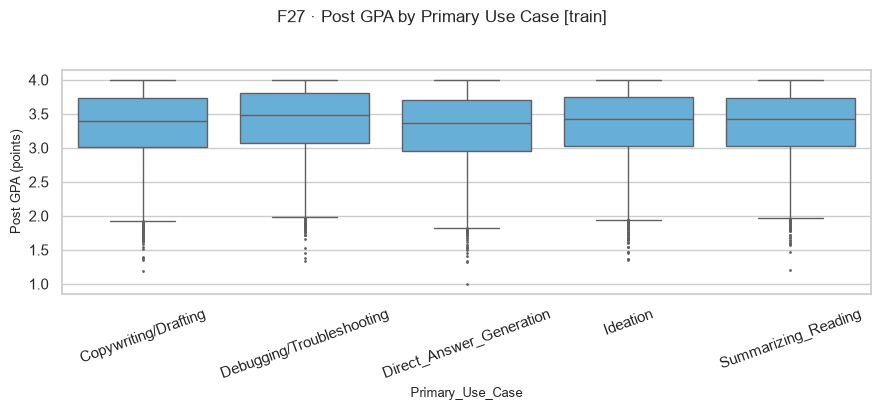

Valid group n and small-group flags in T21; marginal comparison only.

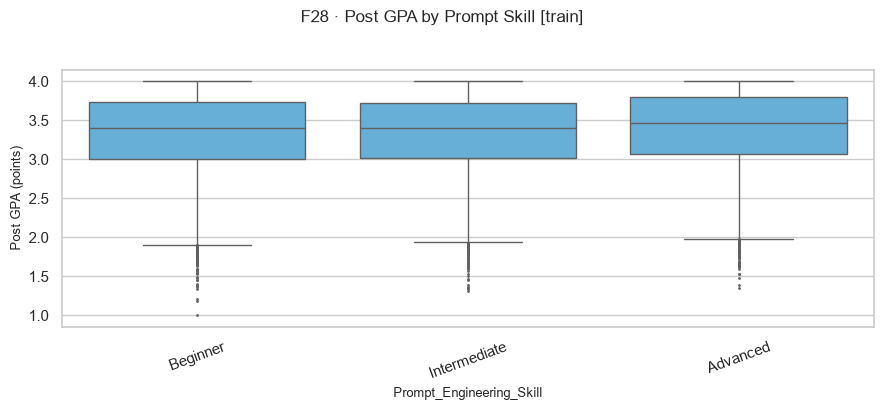

Valid group n and small-group flags in T21; marginal comparison only.

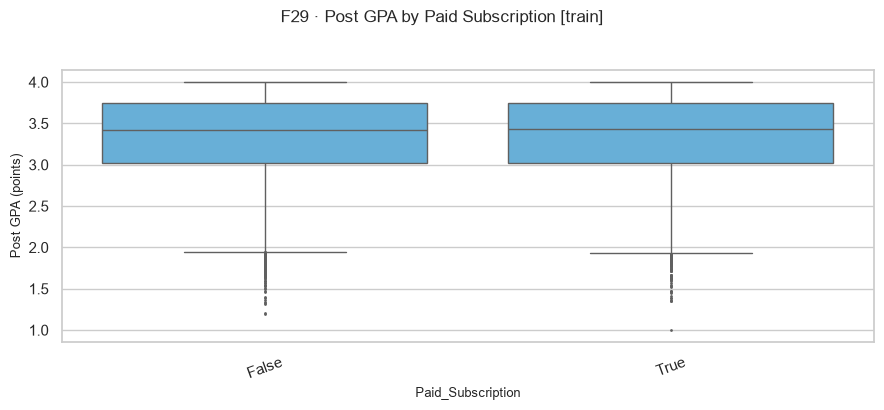

Valid group n and small-group flags in T21; marginal comparison only.

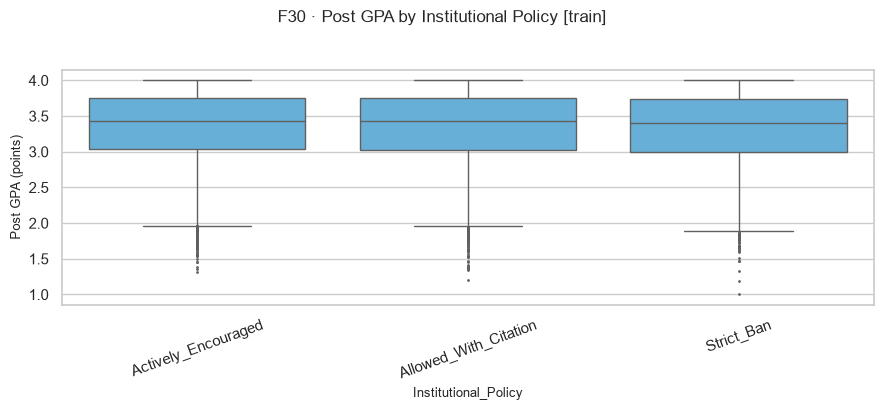

Valid group n and small-group flags in T21; marginal comparison only.

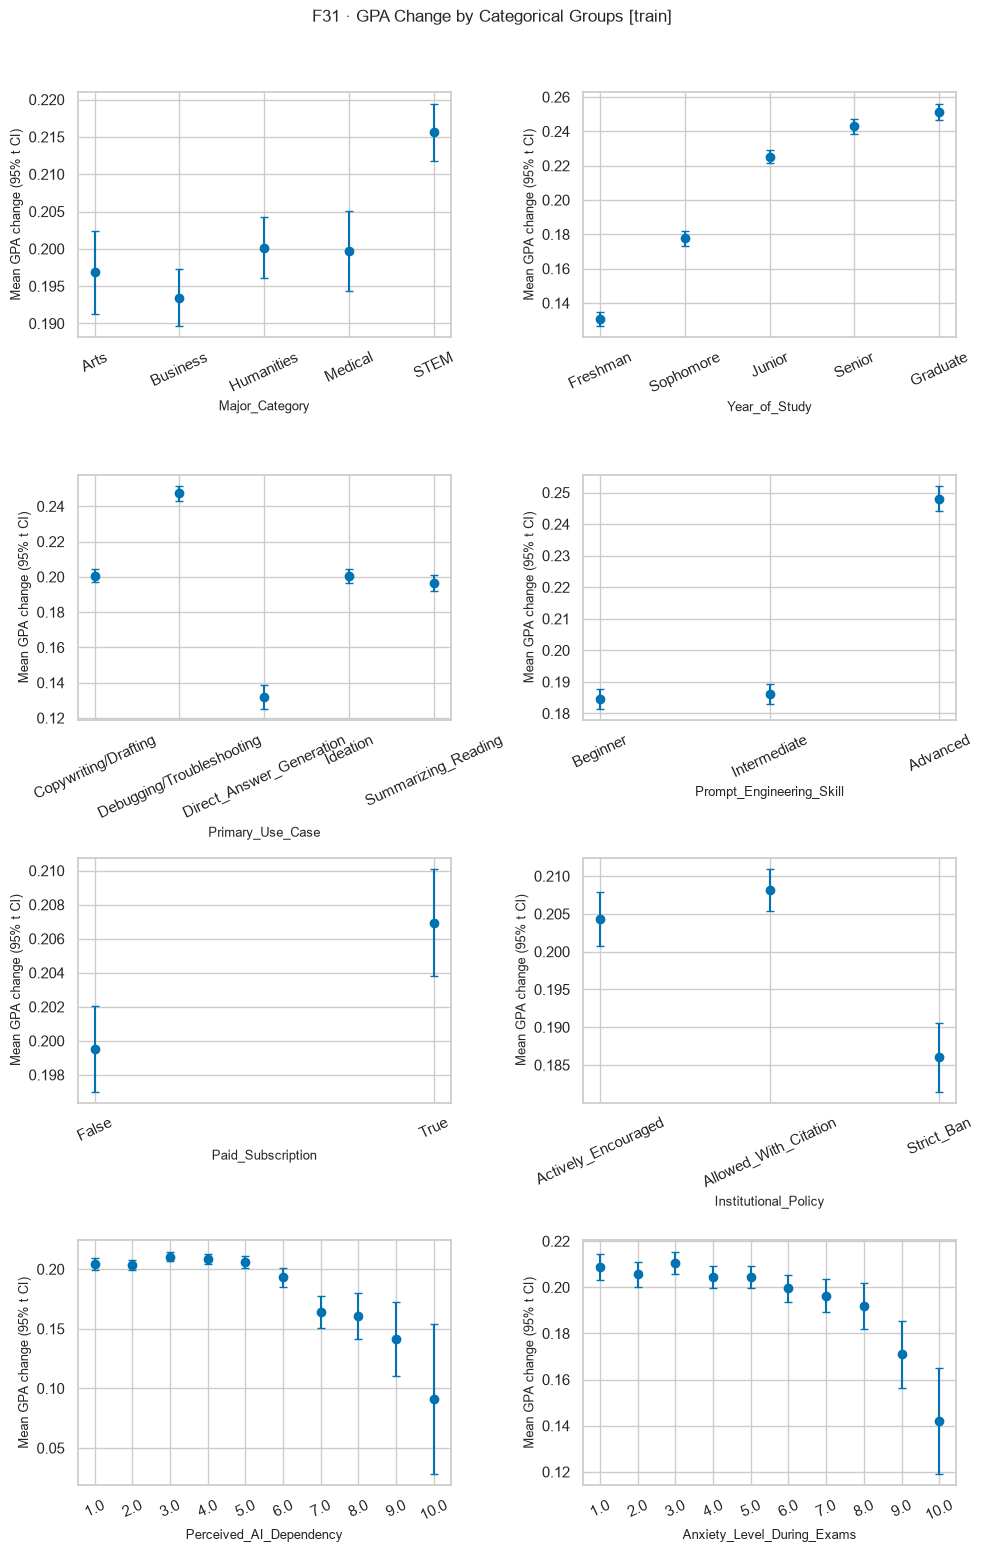

**Weekly_GenAI_Hours** — Post_Semester_GPA: Spearman=0.0079, valid n=35,000; GPA_Change: Spearman=0.0313, valid n=35,000. [T20] Liên hệ marginal; chưa điều chỉnh Pre GPA và không chứng minh nhân quả.

**Traditional_Study_Hours** — Post_Semester_GPA: Spearman=0.1367, valid n=35,000; GPA_Change: Spearman=0.3714, valid n=35,000. [T20] Liên hệ marginal; chưa điều chỉnh Pre GPA và không chứng minh nhân quả.

**Perceived_AI_Dependency** — Post_Semester_GPA: Spearman=-0.0094, valid n=35,000; GPA_Change: Spearman=-0.0118, valid n=35,000. [T20] Liên hệ marginal; chưa điều chỉnh Pre GPA và không chứng minh nhân quả.

In [9]:
pearson_records=[]
spearman_records=[]
rank_data=train.copy()
rank_features=analysis_predictors.copy()
for c,levels in orders.items():
    if c in train and c not in auxiliary:
        rank_data[c]=train[c].map({v:i for i,v in enumerate(levels)}).astype(float)
        rank_features.append(c)
for outcome in [TARGET_COLUMN,'GPA_Change']:
    for c in quantitative_predictors:
        pearson_records.append(safe_correlation(train,c,outcome,'pearson'))
    for c in rank_features:
        spearman_records.append(safe_correlation(rank_data,c,outcome,'spearman'))
pearson_table=save_table('T19',pearson_records)
spearman_table=save_table('T20',spearman_records,caption='Documented ordinal order used for ranks only; no interval-distance assumption.')
group_cols=[c for c in dict.fromkeys(categorical_cols+ordinal_cols) if c not in auxiliary]
group_frames=[summary_groups(train,c,outcome) for c in group_cols for outcome in [TARGET_COLUMN,'GPA_Change']]
group_summary=pd.concat(group_frames,ignore_index=True) if group_frames else pd.DataFrame(columns=['feature','outcome','group','valid_n','mean','small_group'])
save_table('T21',group_summary)
group_differences=[]
for (feature,outcome),part in group_summary.groupby(['feature','outcome'],sort=False):
    valid=part.dropna(subset=['mean'])
    group_differences.append(dict(feature=feature,outcome=outcome,groups=len(valid),
        largest_mean_group=valid.loc[valid['mean'].idxmax(),'group'] if len(valid) else '',
        smallest_mean_group=valid.loc[valid['mean'].idxmin(),'group'] if len(valid) else '',
        mean_range=valid['mean'].max()-valid['mean'].min(),small_groups=int(valid.small_group.sum()),
        test_status='not run; optional tests disabled' if not RUN_OPTIONAL_TESTS else 'group tests deferred: no prespecified independent sampling design',
        limitation='unadjusted association; CIs descriptive, multiple comparisons not inferential'))
save_table('T22',group_differences)

def scatter_grid(aid,outcome,columns):
    if not columns:
        skip(aid,'No applicable numeric predictors')
        return
    fig,axes=axes_grid(len(columns))
    for ax,c in zip(axes,columns):
        pair=plot_sample(train[[c,outcome]].dropna())
        ax.scatter(pair[c],pair[outcome],s=5,alpha=.15,rasterized=True)
        ax.set(xlabel=f'{c} ({units.get(c,"rank")})',ylabel=outcome,title=f'displayed n={len(pair):,}')
    save_figure(aid,fig,caption=f'Plots sampled at most {PLOT_SAMPLE_SIZE:,}, seed {RANDOM_STATE}; correlations use all valid train pairs.')
scatter_grid('F18',TARGET_COLUMN,analysis_predictors)
scatter_grid('F19','GPA_Change',analysis_predictors)
predictor_corr=train[quantitative_predictors].corr(method='pearson',min_periods=3)
heatmap('F20',predictor_corr,'Predictors only; target and auxiliary outcomes excluded. Pair counts available from train missingness and T19 for target pairs.')
heatmap('F21',rank_data[rank_features].corr(method='spearman',min_periods=3))
for aid,outcome in [('F22',TARGET_COLUMN),('F23','GPA_Change')]:
    part=pearson_table[pearson_table.outcome.eq(outcome)].sort_values('coefficient')
    if len(part):
        fig,ax=plt.subplots(figsize=(8,4))
        ax.barh(part.feature,part.coefficient)
        ax.axvline(0,color='black',lw=.8)
        ax.set(xlabel=f'Pearson r with {outcome}',xlim=(-1,1),ylabel='Quantitative predictor')
        save_figure(aid,fig)
    else:
        skip(aid,'No applicable Pearson predictors')

H='Weekly_GenAI_Hours'
def binned_trend(frame,x,y,q=10,context=None):
    part=frame[[x,y]].dropna()
    if len(part)<3 or part[x].nunique()<2:
        return pd.DataFrame(columns=['x_mean','y_mean','n','bin_left','bin_right'])
    bins,edges=pd.qcut(part[x],q=q,duplicates='drop',retbins=True,labels=False)
    part=part.assign(_bin=bins)
    result=part.groupby('_bin',observed=True).agg(x_mean=(x,'mean'),y_mean=(y,'mean'),n=(y,'count')).reset_index()
    codes=result['_bin'].to_numpy(int)
    result['bin_left']=edges[codes]
    result['bin_right']=edges[codes+1]
    if context is not None:
        bin_log.append(dict(label=context,feature=x,edges=json.dumps(edges.tolist()),method=f'train qcut q={q}; duplicate edges dropped',valid_n=len(part)))
    return result.drop(columns='_bin')
if H in train and train[H].nunique()>1:
    fig,ax=plt.subplots(figsize=(8,5))
    pair=plot_sample(train[[H,TARGET_COLUMN]].dropna())
    ax.scatter(pair[H],pair[TARGET_COLUMN],s=6,alpha=.12,label=f'Sample n={len(pair):,}')
    all_pair=train[[H,TARGET_COLUMN]].dropna()
    slope,intercept=np.polyfit(all_pair[H],all_pair[TARGET_COLUMN],1)
    xline=np.linspace(all_pair[H].min(),all_pair[H].max(),100)
    ax.plot(xline,intercept+slope*xline,color='black',label='Linear fit (all valid train)')
    trend=binned_trend(train,H,TARGET_COLUMN,context='F24: marginal AI Hours vs Post GPA')
    ax.plot(trend.x_mean,trend.y_mean,'o-',color='#D55E00',label='Train decile binned mean')
    ax.set(xlabel='Weekly GenAI usage (hours/week)',ylabel='Post GPA (points)')
    ax.legend()
    save_figure('F24',fig,caption='Binned smoother avoids expensive full-data LOWESS. Marginal association, without academic adjustment.')
else:
    skip('F24','AI Hours absent or constant')
for aid,c in [('F25','Major_Category'),('F26','Year_of_Study'),('F27','Primary_Use_Case'),
              ('F28','Prompt_Engineering_Skill'),('F29','Paid_Subscription'),('F30','Institutional_Policy')]:
    if c not in train:
        skip(aid,f'Optional column absent: {c}')
        continue
    fig,ax=plt.subplots(figsize=(9,4))
    part=train[[c,TARGET_COLUMN]].dropna().copy()
    part[c]=part[c].astype(str)
    order=[v for v in orders.get(c,sorted(part[c].unique())) if v in set(part[c])]
    extras=sorted(set(part[c])-set(order))
    sns.boxplot(data=part,x=c,y=TARGET_COLUMN,order=order+extras,ax=ax,color='#56B4E9',fliersize=1)
    ax.tick_params(axis='x',rotation=20)
    ax.set(ylabel='Post GPA (points)',xlabel=c)
    save_figure(aid,fig,caption='Valid group n and small-group flags in T21; marginal comparison only.')
if group_cols:
    fig,axes=axes_grid(len(group_cols),columns=2,height=3.8)
    for ax,c in zip(axes,group_cols):
        part=group_summary[group_summary.feature.eq(c)&group_summary.outcome.eq('GPA_Change')]
        ax.errorbar(part['group'],part['mean'],yerr=[part['mean']-part.ci95_low,part.ci95_high-part['mean']],fmt='o',capsize=3)
        ax.set(xlabel=c,ylabel='Mean GPA change (95% t CI)')
        ax.tick_params(axis='x',rotation=25)
    save_figure('F31',fig)
else:
    skip('F31','No grouping predictors present')
for c in [H,'Traditional_Study_Hours','Perceived_AI_Dependency']:
    part=spearman_table[spearman_table.feature.eq(c)]
    if len(part):
        note('**'+c+'** — '+ '; '.join(f'{r.outcome}: Spearman={r.coefficient:.4f}, valid n={r.valid_n:,}' for r in part.itertuples())+
             '. [T20] Liên hệ marginal; chưa điều chỉnh Pre GPA và không chứng minh nhân quả.')

## Section 8 — Multivariate Analysis

**Method.** Các quartiles/deciles được fit trên train, log edges và xử lý ties bằng `duplicates=drop`.
Grouped means/heatmaps báo count từng cell, mask nhóm dưới `MIN_GROUP_SIZE`; không tô 0 thay cell thiếu.
Xem AI × Prompt, Major, Study, Pre GPA, Dependency; Use Case × Prompt; Dependency × Anxiety và auxiliary Retention.
Phân tầng Pre GPA chỉ kiểm soát thô; conditional OLS ở Section 9 bổ sung kiểm soát tuyến tính, chưa phải causal moderation.

**T23 · AI Usage Intensity Groups** — scope: `train`; 4 rows. 

,feature,group,group_n,valid_n,mean,median,std,outcome,se,ci95_low,ci95_high,small_group,ci_method
0,AI_Hours_Group,"(-0.001, 2.39]",8760,8760,0.1874,0.1870,0.1758,GPA_Change,0.0019,0.1837,0.1911,False,t-based mean CI; independence not verified
1,AI_Hours_Group,"(2.39, 5.8]",8742,8742,0.2051,0.2000,0.1766,GPA_Change,0.0019,0.2014,0.2088,False,t-based mean CI; independence not verified
2,AI_Hours_Group,"(5.8, 11.692]",8748,8748,0.2291,0.2250,0.1753,GPA_Change,0.0019,0.2254,0.2328,False,t-based mean CI; independence not verified
3,AI_Hours_Group,"(11.692, 40.0]",8750,8750,0.1891,0.2015,0.2175,GPA_Change,0.0023,0.1846,0.1937,False,t-based mean CI; independence not verified


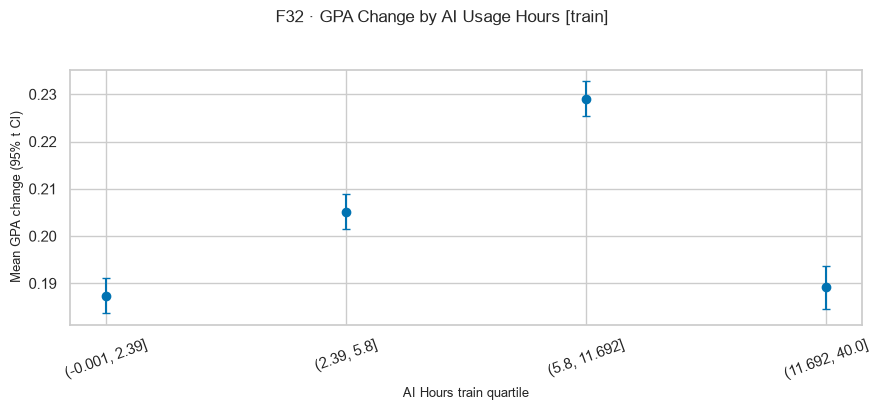

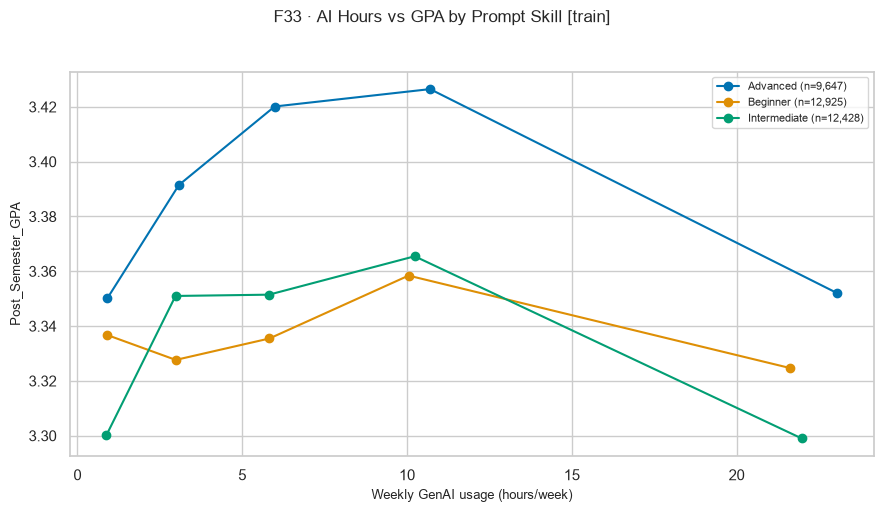

Within-group quintile means; small cells hidden. Bins computed only within train.

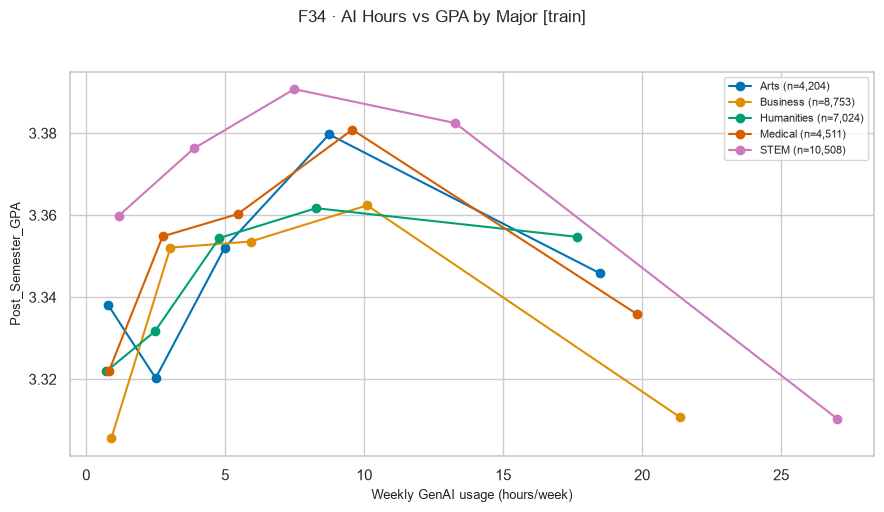

Within-group quintile means; small cells hidden. Bins computed only within train.

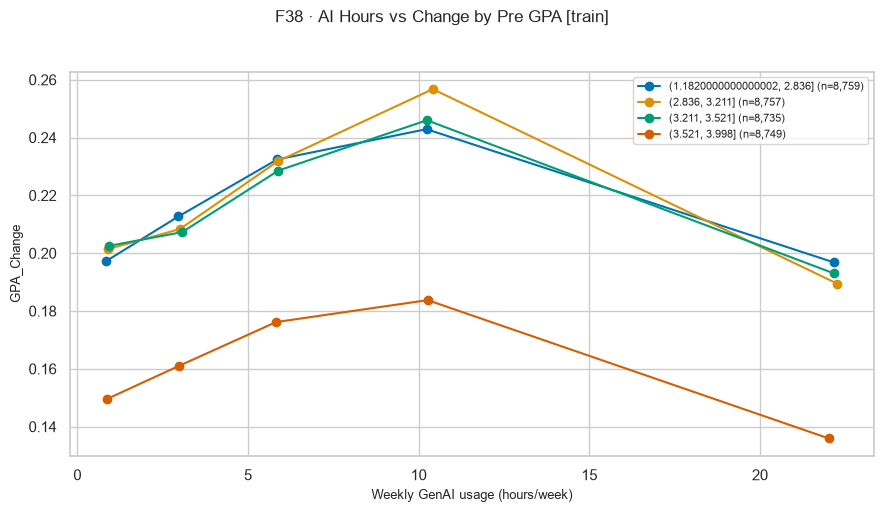

Within-group quintile means; small cells hidden. Bins computed only within train.

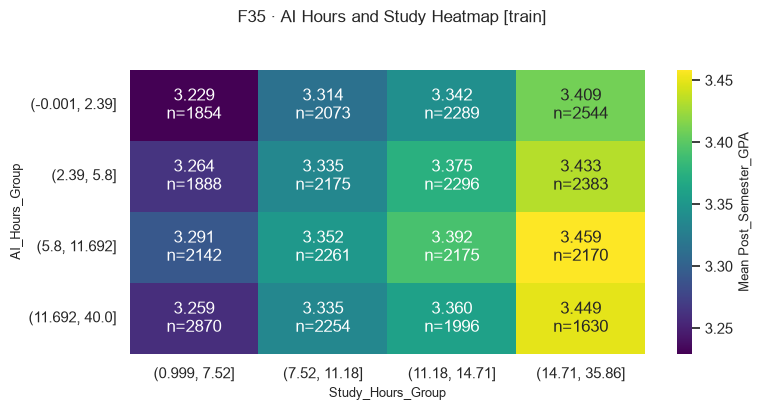

Cell annotations: mean and valid n. Cells n<30 hidden; all counts retained in T24.

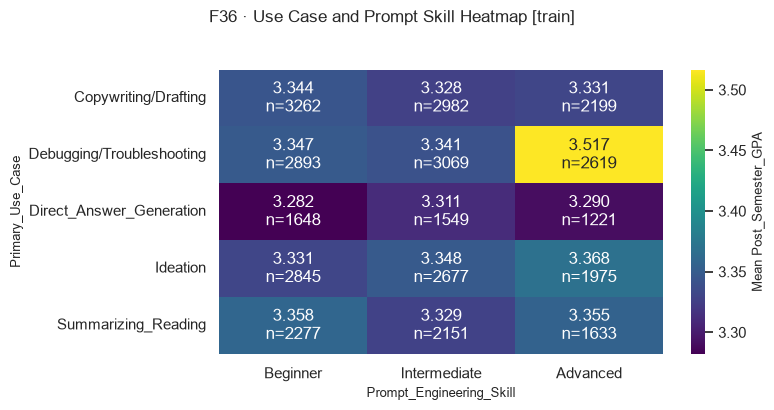

Cell annotations: mean and valid n. Cells n<30 hidden; all counts retained in T24.

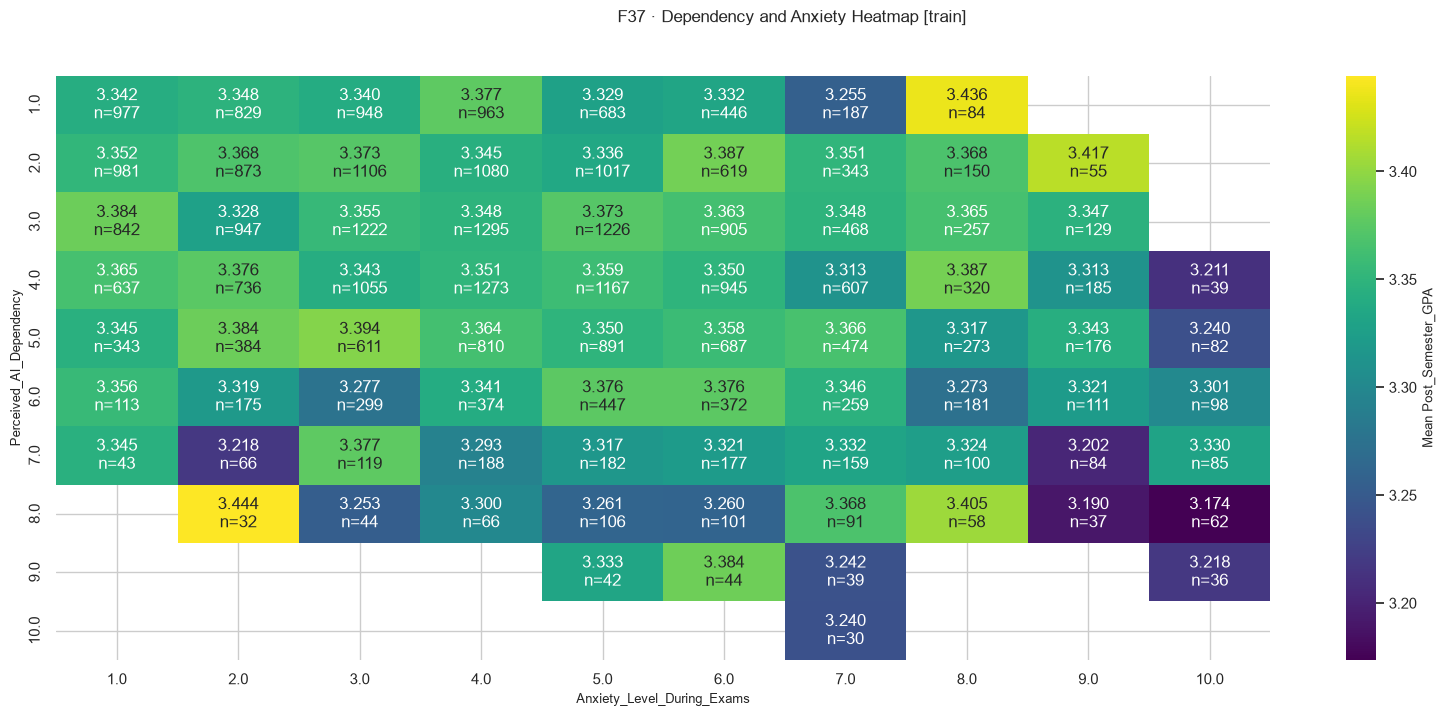

Cell annotations: mean and valid n. Cells n<30 hidden; all counts retained in T24.

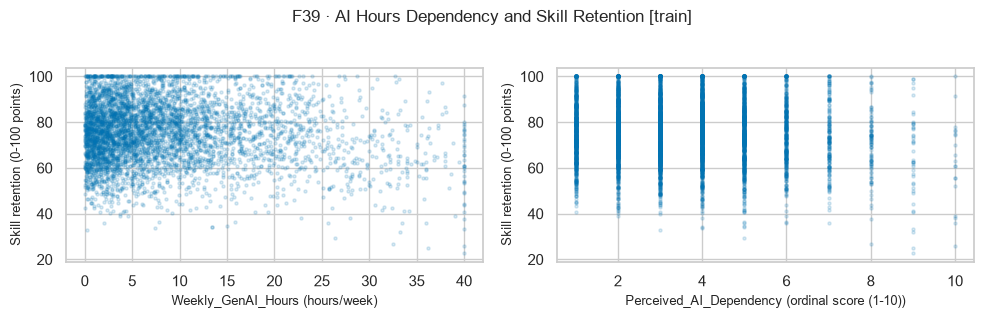

Auxiliary outcome, never included in predictors. Statistics on all valid train rows, plots sampled.

**T24 · Academic AI Group Summary** — scope: `train`; 130 rows. 

,analysis,left_level,right_level,outcome,n,mean,std,small_group
0,AI_Hours_Group x Study_Hours_Group,"(-0.001, 2.39]","(0.999, 7.52]",Post_Semester_GPA,1854,3.2292,0.5009,False
1,AI_Hours_Group x Study_Hours_Group,"(-0.001, 2.39]","(11.18, 14.71]",Post_Semester_GPA,2289,3.3422,0.5002,False
2,AI_Hours_Group x Study_Hours_Group,"(-0.001, 2.39]","(14.71, 35.86]",Post_Semester_GPA,2544,3.4093,0.4828,False
3,AI_Hours_Group x Study_Hours_Group,"(-0.001, 2.39]","(7.52, 11.18]",Post_Semester_GPA,2073,3.3144,0.4909,False
4,AI_Hours_Group x Study_Hours_Group,"(11.692, 40.0]","(0.999, 7.52]",Post_Semester_GPA,2870,3.2593,0.5111,False
5,AI_Hours_Group x Study_Hours_Group,"(11.692, 40.0]","(11.18, 14.71]",Post_Semester_GPA,1996,3.3600,0.5078,False
6,AI_Hours_Group x Study_Hours_Group,"(11.692, 40.0]","(14.71, 35.86]",Post_Semester_GPA,1630,3.4488,0.4759,False
7,AI_Hours_Group x Study_Hours_Group,"(11.692, 40.0]","(7.52, 11.18]",Post_Semester_GPA,2254,3.3352,0.5015,False
8,AI_Hours_Group x Study_Hours_Group,"(2.39, 5.8]","(0.999, 7.52]",Post_Semester_GPA,1888,3.2639,0.4950,False
9,AI_Hours_Group x Study_Hours_Group,"(2.39, 5.8]","(11.18, 14.71]",Post_Semester_GPA,2296,3.3746,0.4852,False


**T25 · Interaction Analysis Summary** — scope: `train`; 16 rows. Exact train quantile edges; ties use duplicate-edge removal. Trend-specific bin ranges recorded in T26.

,label,feature,edges,method,valid_n
0,Pre GPA quartiles,Pre_Semester_GPA,"[1.183, 2.836, 3.211, 3.521, 3.998]",train qcut; duplicate edges dropped,35000
1,F24: marginal AI Hours vs Post GPA,Weekly_GenAI_Hours,"[0.0, 0.88, 1.85, 2.9770000000000074, 4.26, 5....",train qcut q=10; duplicate edges dropped,35000
2,AI Hours quartiles,Weekly_GenAI_Hours,"[0.0, 2.39, 5.8, 11.692499999999999, 40.0]",train qcut; duplicate edges dropped,35000
3,Traditional study quartiles,Traditional_Study_Hours,"[1.0, 7.52, 11.18, 14.71, 35.86]",train qcut; duplicate edges dropped,35000
4,F33: Prompt_Engineering_Skill=Advanced; outcom...,Weekly_GenAI_Hours,"[0.0, 1.89, 4.31, 7.91, 14.14, 40.0]",train qcut q=5; duplicate edges dropped,9647
5,F33: Prompt_Engineering_Skill=Beginner; outcom...,Weekly_GenAI_Hours,"[0.0, 1.86, 4.24, 7.57, 13.18, 40.0]",train qcut q=5; duplicate edges dropped,12925
6,F33: Prompt_Engineering_Skill=Intermediate; ou...,Weekly_GenAI_Hours,"[0.0, 1.82, 4.24, 7.6, 13.496000000000004, 40.0]",train qcut q=5; duplicate edges dropped,12428
7,F34: Major_Category=Arts; outcome=Post_Semeste...,Weekly_GenAI_Hours,"[0.0, 1.59, 3.53, 6.67, 11.428, 36.0]",train qcut q=5; duplicate edges dropped,4204
8,F34: Major_Category=Business; outcome=Post_Sem...,Weekly_GenAI_Hours,"[0.0, 1.9140000000000008, 4.298000000000002, 7...",train qcut q=5; duplicate edges dropped,8753
9,F34: Major_Category=Humanities; outcome=Post_S...,Weekly_GenAI_Hours,"[0.0, 1.5060000000000013, 3.522000000000003, 6...",train qcut q=5; duplicate edges dropped,7024


**T26 · Subgroup Summary** — scope: `train`; 83 rows. Grouped trends plus separately labelled auxiliary/Dependency associations. n/coefficient missing where not applicable.

,analysis,group,outcome,hours_mean,outcome_mean,n,bin_left,bin_right,small_group,feature,method,valid_n,coefficient,reason
0,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Advanced,Post_Semester_GPA,0.9077,3.3501,1941.0,0.00,1.89,False,NaN,NaN,NaN,NaN,NaN
1,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Advanced,Post_Semester_GPA,3.0788,3.3915,1920.0,1.89,4.31,False,NaN,NaN,NaN,NaN,NaN
2,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Advanced,Post_Semester_GPA,5.9834,3.4201,1928.0,4.31,7.91,False,NaN,NaN,NaN,NaN,NaN
3,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Advanced,Post_Semester_GPA,10.7004,3.4265,1929.0,7.91,14.14,False,NaN,NaN,NaN,NaN,NaN
4,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Advanced,Post_Semester_GPA,23.0603,3.3520,1929.0,14.14,40.00,False,NaN,NaN,NaN,NaN,NaN
5,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Beginner,Post_Semester_GPA,0.8947,3.3368,2590.0,0.00,1.86,False,NaN,NaN,NaN,NaN,NaN
6,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Beginner,Post_Semester_GPA,2.9840,3.3277,2591.0,1.86,4.24,False,NaN,NaN,NaN,NaN,NaN
7,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Beginner,Post_Semester_GPA,5.8265,3.3355,2577.0,4.24,7.57,False,NaN,NaN,NaN,NaN,NaN
8,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Beginner,Post_Semester_GPA,10.0472,3.3584,2584.0,7.57,13.18,False,NaN,NaN,NaN,NaN,NaN
9,Weekly_GenAI_Hours x Prompt_Engineering_Skill,Beginner,Post_Semester_GPA,21.6342,3.3247,2583.0,13.18,40.00,False,NaN,NaN,NaN,NaN,NaN


**Evidence.** 130 cross-tab cells và 60 grouped-trend cells được xuất. Ngưỡng diễn giải nhóm nhỏ n<30. Mô hình interaction chỉ là ứng viên; kiểm chứng cùng lower-order terms và trên validation/CV. [T24–T26]

In [10]:
multivariate_rows=[]
interaction_summaries=[]
if H in train:
    train['AI_Hours_Group']=quantile_bins(train,H,'AI Hours quartiles')
    ai_groups=summary_groups(train,'AI_Hours_Group','GPA_Change')
    save_table('T23',ai_groups)
else:
    ai_groups=pd.DataFrame()
    skip('T23','AI Hours absent')
if 'Traditional_Study_Hours' in train:
    train['Study_Hours_Group']=quantile_bins(train,'Traditional_Study_Hours','Traditional study quartiles')

def grouped_trend(aid,group,outcome):
    if H not in train or group not in train:
        skip(aid,f'Required columns unavailable: {H}, {group}')
        return
    fig,ax=plt.subplots(figsize=(9,5))
    for level,part in train.groupby(group,observed=True,dropna=False):
        trend=binned_trend(part,H,outcome,q=5,context=f'{aid}: {group}={level}; outcome={outcome}')
        multivariate_rows.extend(dict(analysis=f'{H} x {group}',group=str(level),outcome=outcome,
            hours_mean=r.x_mean,outcome_mean=r.y_mean,n=int(r.n),bin_left=r.bin_left,bin_right=r.bin_right,
            small_group=bool(r.n<MIN_GROUP_SIZE)) for r in trend.itertuples())
        eligible=trend.n.ge(MIN_GROUP_SIZE)
        ax.plot(trend.loc[eligible,'x_mean'],trend.loc[eligible,'y_mean'],'o-',label=f'{level} (n={len(part):,})')
    ax.set(xlabel='Weekly GenAI usage (hours/week)',ylabel=outcome)
    ax.legend(fontsize=8,loc='best')
    save_figure(aid,fig,caption='Within-group quintile means; small cells hidden. Bins computed only within train.')

if len(ai_groups):
    fig,ax=plt.subplots(figsize=(9,4))
    ax.errorbar(ai_groups['group'],ai_groups['mean'],yerr=[ai_groups['mean']-ai_groups.ci95_low,ai_groups.ci95_high-ai_groups['mean']],fmt='o',capsize=3)
    ax.set(xlabel='AI Hours train quartile',ylabel='Mean GPA change (95% t CI)')
    ax.tick_params(axis='x',rotation=20)
    save_figure('F32',fig)
else:
    skip('F32','AI Hours groups unavailable')
grouped_trend('F33','Prompt_Engineering_Skill',TARGET_COLUMN)
grouped_trend('F34','Major_Category',TARGET_COLUMN)
grouped_trend('F38','Pre_GPA_Group','GPA_Change')

def cross_heatmap(aid,left,right,outcome=TARGET_COLUMN):
    if left not in train or right not in train:
        skip(aid,f'Optional columns unavailable: {left}, {right}')
        return
    part=train[[left,right,outcome]].dropna().copy()
    if part.empty:
        skip(aid,'No complete training rows for cross-tabulation')
        return
    left_order=ordered_levels(part[left],left)
    right_order=ordered_levels(part[right],right)
    part[left],part[right]=part[left].astype(str),part[right].astype(str)
    grouped=part.groupby([left,right],observed=True)[outcome].agg(['count','mean','std']).reset_index()
    for r in grouped.to_dict('records'):
        interaction_summaries.append(dict(analysis=f'{left} x {right}',left_level=r[left],right_level=r[right],
            outcome=outcome,n=r['count'],mean=r['mean'],std=r['std'],small_group=r['count']<MIN_GROUP_SIZE))
    means=grouped.pivot(index=left,columns=right,values='mean').reindex(index=left_order,columns=right_order)
    counts=grouped.pivot(index=left,columns=right,values='count').reindex(index=left_order,columns=right_order)
    labels=means.map(lambda v:f'{v:.3f}' if pd.notna(v) else '')+'\nn='+counts.map(lambda v:str(int(v)) if pd.notna(v) else '')
    fig,ax=plt.subplots(figsize=(max(8,1.6*len(means.columns)),max(4,.7*len(means))))
    if counts.ge(MIN_GROUP_SIZE).any().any():
        sns.heatmap(means,mask=counts.lt(MIN_GROUP_SIZE)|means.isna(),annot=labels,fmt='',cmap='viridis',ax=ax,
                    cbar_kws={'label':f'Mean {outcome}'})
    else:
        ax.text(.5,.5,'All cells below minimum group size',ha='center',transform=ax.transAxes)
    ax.set(xlabel=right,ylabel=left)
    save_figure(aid,fig,caption=f'Cell annotations: mean and valid n. Cells n<{MIN_GROUP_SIZE} hidden; all counts retained in T24.')

cross_heatmap('F35','AI_Hours_Group','Study_Hours_Group')
cross_heatmap('F36','Primary_Use_Case','Prompt_Engineering_Skill')
cross_heatmap('F37','Perceived_AI_Dependency','Anxiety_Level_During_Exams')

# Auxiliary analysis is kept separate from predictor-only correlations and all X matrices.
retention='Skill_Retention_Score'
aux_records=[]
if retention in train:
    cols=[c for c in [H,'Perceived_AI_Dependency'] if c in train]
    if cols:
        fig,axes=axes_grid(len(cols),columns=2)
        for ax,c in zip(axes,cols):
            pair=plot_sample(train[[c,retention]].dropna())
            ax.scatter(pair[c],pair[retention],s=5,alpha=.15)
            ax.set(xlabel=f'{c} ({units[c]})',ylabel='Skill retention (0-100 points)')
            for method in ['pearson','spearman'] if c==H else ['spearman']:
                aux_records.append(safe_correlation(train,c,retention,method))
        save_figure('F39',fig,caption='Auxiliary outcome, never included in predictors. Statistics on all valid train rows, plots sampled.')
    else:
        skip('F39','AI Hours and Dependency both unavailable')
else:
    skip('F39','Auxiliary retention outcome absent')
if H in train and 'Perceived_AI_Dependency' in train:
    for level,part in train.groupby('Perceived_AI_Dependency',observed=True):
        for outcome in [TARGET_COLUMN,'GPA_Change']:
            rec=safe_correlation(part,H,outcome,'spearman')
            rec.update(analysis='AI Hours x Dependency',group=str(level))
            aux_records.append(rec)
if interaction_summaries:
    save_table('T24',interaction_summaries)
else:
    skip('T24','No applicable complete interaction cells')
save_table('T25',pd.DataFrame(bin_log),caption='Exact train quantile edges; ties use duplicate-edge removal. Trend-specific bin ranges recorded in T26.')
subgroup=pd.concat([pd.DataFrame(multivariate_rows),pd.DataFrame(aux_records)],ignore_index=True)
if len(subgroup):
    save_table('T26',subgroup,caption='Grouped trends plus separately labelled auxiliary/Dependency associations. n/coefficient missing where not applicable.')
else:
    skip('T26','No applicable grouped trends or auxiliary pairs')
note(f'**Evidence.** {len(interaction_summaries)} cross-tab cells và {len(multivariate_rows)} grouped-trend cells được xuất. '
     f'Ngưỡng diễn giải nhóm nhỏ n<{MIN_GROUP_SIZE}. Mô hình interaction chỉ là ứng viên; kiểm chứng cùng lower-order terms và trên validation/CV. [T24–T26]')

## Section 9 — Regression-Oriented Analysis

### 9.1 Linearity and multicollinearity

**Method.** Preprocessing fit train: numeric median; categorical most-frequent + one-hot **drop first**.
Numeric ordinal ratings được one-hot mặc định, không ép equal spacing.
Loại all-missing hoặc encoded constants có log; reference categories và tên encoded term được giữ.
VIF tính từ correlation Gram matrix của design đã center, tương đương auxiliary regression có intercept;
constant/intercept không có VIF. Báo rank và condition number ở cả raw scale và standardized scale.
Ngưỡng VIF 5/10 và |r|≥0.8 chỉ là heuristic, không phải quy tắc xóa.

### 9.2 Exploratory comparison protocol

E0a train-mean; E0b persistence (missing Pre → train median); E1 Pre-only OLS;
E2 Academic OLS; E3 Academic + AI OLS. Tất cả dùng cùng train population và validation rows.
E1 được xem là baseline trước kỳ theo ý nghĩa Pre GPA. E2/E3 là **conditional / retrospective** do timing của các biến thêm chưa xác minh.
Delta E2/E3 đo giá trị bổ sung trong cùng retrospective scenario, chưa chứng minh forecast benefit.
Fit đúng một bộ cấu hình định trước; không tìm kiếm/tuning dựa trên validation.

In [11]:
predictor_candidates=[c for c in raw if c in semantic and c not in [ID_COLUMN,TARGET_COLUMN,*auxiliary]]
assert not set(predictor_candidates) & {ID_COLUMN,TARGET_COLUMN,'GPA_Change',*auxiliary}
pearson_model_predictors=[c for c in predictor_candidates if c in quantitative_predictors]
model_corr=train[pearson_model_predictors].corr(min_periods=3)
high_pairs=[]
for i,left in enumerate(model_corr.columns):
    for right in model_corr.columns[i+1:]:
        value=model_corr.loc[left,right]
        if pd.notna(value) and abs(value)>=HIGH_CORRELATION_THRESHOLD:
            high_pairs.append(dict(left=left,right=right,pearson=value,valid_n=int(train[[left,right]].dropna().shape[0]),threshold=HIGH_CORRELATION_THRESHOLD))
save_table('T27',pd.DataFrame(high_pairs,columns=['left','right','pearson','valid_n','threshold']),
           caption='Empty table means no quantitative predictor pair passes the configured threshold; ordinal pair checks in T20/T26.')
reuse('F40','F20')

def input_frame(frame,features):
    part=frame[features].copy()
    for c in features:
        if c in numeric_expected and semantic.get(c) not in ['ordinal','binary']:
            part[c]=pd.to_numeric(part[c],errors='raise')
        else:
            part[c]=part[c].astype(object).where(part[c].notna(),np.nan)
    return part

models={}
preprocessing_log=[]
metric_records=[]
coefficient_records=[]
y_train=train[TARGET_COLUMN].to_numpy(float)
y_validation=validation[TARGET_COLUMN].to_numpy(float)

def record_metrics(model_id,pred,scenario,features,note_text=''):
    mse=mean_squared_error(y_validation,pred)
    metric_records.append(dict(model=model_id,scenario=scenario,features='; '.join(features),
        valid_n=len(pred),MAE=mean_absolute_error(y_validation,pred),MSE=mse,RMSE=np.sqrt(mse),
        R2=r2_score(y_validation,pred),fit_scope='train',evaluation_scope='validation',
        adjusted_R2_train=np.nan,note=note_text))

def fit_ols(model_id,features,scenario):
    features=[c for c in features if c in train]
    usable=[c for c in features if train[c].notna().any()]
    for c in set(features)-set(usable):
        preprocessing_log.append(dict(model=model_id,feature=c,action='exclude all-missing predictor; no train median/mode'))
    if not usable:
        warnings_log.append(f'{model_id}: no usable predictor; skipped')
        return None
    numerical=[c for c in usable if c in numeric_expected and semantic.get(c) not in ['ordinal','binary']]
    categorical=[c for c in usable if c not in numerical]
    transformers=[]
    if numerical:
        transformers.append(('num',Pipeline([('impute',SimpleImputer(strategy='median'))]),numerical))
    if categorical:
        transformers.append(('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
            ('encode',OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False))]),categorical))
    transformer=ColumnTransformer(transformers,remainder='drop',verbose_feature_names_out=True)
    x=transformer.fit_transform(input_frame(train,usable)).astype(float)
    xv=transformer.transform(input_frame(validation,usable)).astype(float)
    names=transformer.get_feature_names_out().astype(str)
    keep=np.ptp(x,axis=0)>1e-12
    for name in names[~keep]:
        preprocessing_log.append(dict(model=model_id,feature=name,action='exclude encoded constant'))
    x,xv,names=x[:,keep],xv[:,keep],names[keep]
    if x.shape[1]==0 or len(x)<=x.shape[1]+5:
        raise ValueError(f'{model_id}: insufficient train rows / varying predictors for OLS: n={len(x)}, p={x.shape[1]+1}')
    design=np.column_stack([np.ones(len(x)),x])
    design_val=np.column_stack([np.ones(len(xv)),xv])
    rank=int(np.linalg.matrix_rank(design))
    fit=sm.OLS(y_train,design,hasconst=True).fit(cov_type='HC3' if RUN_OPTIONAL_TESTS else 'nonrobust')
    prediction=fit.predict(design_val)
    references={}
    if categorical:
        encoder=transformer.named_transformers_['cat'].named_steps['encode']
        for c,levels in zip(categorical,encoder.categories_):
            references[c]=str(levels[0])
            preprocessing_log.append(dict(model=model_id,feature=c,action=f'one-hot drop first; reference={levels[0]}; unknown->all-zero with warning'))
    for c in numerical:
        imputer=transformer.named_transformers_['num'].named_steps['impute']
        value=imputer.statistics_[numerical.index(c)]
        preprocessing_log.append(dict(model=model_id,feature=c,action=f'train median={value:.17g}; no scaling for raw-unit OLS'))
    record_metrics(model_id,prediction,scenario,usable)
    metric_records[-1]['adjusted_R2_train']=float(fit.rsquared_adj) if rank==design.shape[1] else np.nan
    ci=np.asarray(fit.conf_int())
    for j,term in enumerate(['intercept',*names]):
        origin=next((c for c in sorted(usable,key=len,reverse=True) if str(term).split('__')[-1]==c or str(term).split('__')[-1].startswith(c+'_')),'intercept')
        coefficient_records.append(dict(model=model_id,scenario=scenario,term=term,original_feature=origin,
            reference=references.get(origin,''),coefficient=fit.params[j],
            standard_error=fit.bse[j] if rank==design.shape[1] else np.nan,
            ci95_low=ci[j,0] if rank==design.shape[1] else np.nan,ci95_high=ci[j,1] if rank==design.shape[1] else np.nan,
            coefficient_unit='GPA points per '+units.get(origin,'indicator unit'),
            inference='classical OLS CI assumes independent homoscedastic errors' if not RUN_OPTIONAL_TESTS else 'HC3 robust CI; independence still required',
            identification='identified' if rank==design.shape[1] else 'rank deficient: pinv descriptive fit only; no coefficient inference'))
    result=dict(fit=fit,transformer=transformer,features=usable,names=names,x=x,design=design,design_val=design_val,
        val_prediction=prediction,rank=rank,scenario=scenario,references=references,keep=keep)
    models[model_id]=result
    return result

record_metrics('E0a',np.full(len(validation),y_train.mean()),'train-mean reference',[])
pre_median=train.Pre_Semester_GPA.median()
if pd.notna(pre_median):
    record_metrics('E0b',validation.Pre_Semester_GPA.fillna(pre_median).to_numpy(float),
        'pre-semester persistence',['Pre_Semester_GPA'],'Missing Pre imputed with train median, not validation statistics')
fit_ols('E1',['Pre_Semester_GPA'],'pre-semester baseline; deployment timing still requires institutional verification')
academic=[c for c in ['Pre_Semester_GPA','Major_Category','Year_of_Study','Traditional_Study_Hours'] if c in train]
fit_ols('E2',academic,'conditional / retrospective academic')
ai_additions=[c for c in ['Weekly_GenAI_Hours','Primary_Use_Case','Prompt_Engineering_Skill','Tool_Diversity',
    'Paid_Subscription','Perceived_AI_Dependency','Institutional_Policy','Anxiety_Level_During_Exams'] if c in train]
fit_ols('E3',list(dict.fromkeys(academic+ai_additions)),'conditional / retrospective academic + AI; exam anxiety high temporal risk')
results=pd.DataFrame(metric_records)
for mid,ref in [('E1','E0a'),('E2','E1'),('E3','E2')]:
    if mid in set(results.model) and ref in set(results.model):
        a=results.model.eq(mid)
        refrow=results.set_index('model').loc[ref]
        results.loc[a,'delta_reference']=ref
        for metric in ['MAE','RMSE','R2']:
            results.loc[a,'delta_'+metric]=results.loc[a,metric]-refrow[metric]
save_table('T29',results,'validation','Adjusted R² is TRAIN fitted-sample only; validation metrics are exploratory, never final test performance.')
coefficient_table=save_table('T30',coefficient_records)
note('**Modeling implication.** E2→E3 là so sánh incremental trong retrospective scenario trên cùng rows. '
     'E1→E2 thay đổi temporal assumptions nên delta không chứng minh cải thiện forecast. '
     'Raw coefficients khác đơn vị không phải feature importance. Reference groups, imputation và constant drops được lưu trong preprocessing_log.csv.')

**T27 · Highly Correlated Predictor Pairs** — scope: `train`; 0 rows. Empty table means no quantitative predictor pair passes the configured threshold; ordinal pair checks in T20/T26.

,left,right,pearson,valid_n,threshold


**T29 · Exploratory Regression Results** — scope: `validation`; 5 rows. Adjusted R² is TRAIN fitted-sample only; validation metrics are exploratory, never final test performance.

,model,scenario,features,valid_n,MAE,MSE,RMSE,...,evaluation_scope,adjusted_R2_train,note,delta_reference,delta_MAE,delta_RMSE,delta_R2
0,E0a,train-mean reference,,7500,0.4052,0.2452,0.4952,...,validation,NaN,,NaN,NaN,NaN,NaN
1,E0b,pre-semester persistence,Pre_Semester_GPA,7500,0.2304,0.0760,0.2757,...,validation,NaN,"Missing Pre imputed with train median, not val...",NaN,NaN,NaN,NaN
2,E1,pre-semester baseline; deployment timing still...,Pre_Semester_GPA,7500,0.1413,0.0332,0.1823,...,validation,0.8582,,E0a,-0.2639,-0.3128,0.8645
3,E2,conditional / retrospective academic,Pre_Semester_GPA; Major_Category; Year_of_Stud...,7500,0.1258,0.0264,0.1626,...,validation,0.8873,,E1,-0.0155,-0.0198,0.0278
4,E3,conditional / retrospective academic + AI; exa...,Pre_Semester_GPA; Major_Category; Year_of_Stud...,7500,0.1230,0.0247,0.1571,...,validation,0.8953,,E2,-0.0028,-0.0054,0.0071


**T30 · Coefficients** — scope: `train`; 53 rows. 

,model,scenario,term,original_feature,reference,coefficient,standard_error,ci95_low,ci95_high,coefficient_unit,inference,identification
0,E1,pre-semester baseline; deployment timing still...,intercept,intercept,,0.3286,0.0066,0.3156,0.3416,GPA points per indicator unit,classical OLS CI assumes independent homosceda...,identified
1,E1,pre-semester baseline; deployment timing still...,num__Pre_Semester_GPA,Pre_Semester_GPA,,0.9600,0.0021,0.9559,0.9641,GPA points per GPA points,classical OLS CI assumes independent homosceda...,identified
2,E2,conditional / retrospective academic,intercept,intercept,,0.0900,0.0069,0.0764,0.1036,GPA points per indicator unit,classical OLS CI assumes independent homosceda...,identified
3,E2,conditional / retrospective academic,num__Pre_Semester_GPA,Pre_Semester_GPA,,0.9618,0.0019,0.9582,0.9654,GPA points per GPA points,classical OLS CI assumes independent homosceda...,identified
4,E2,conditional / retrospective academic,num__Traditional_Study_Hours,Traditional_Study_Hours,,0.0138,0.0002,0.0134,0.0141,GPA points per hours/week,classical OLS CI assumes independent homosceda...,identified
5,E2,conditional / retrospective academic,cat__Major_Category_Business,Major_Category,Arts,-0.0010,0.0031,-0.0071,0.0052,GPA points per category,classical OLS CI assumes independent homosceda...,identified
6,E2,conditional / retrospective academic,cat__Major_Category_Humanities,Major_Category,Arts,0.0024,0.0033,-0.0039,0.0088,GPA points per category,classical OLS CI assumes independent homosceda...,identified
7,E2,conditional / retrospective academic,cat__Major_Category_Medical,Major_Category,Arts,0.0028,0.0036,-0.0042,0.0098,GPA points per category,classical OLS CI assumes independent homosceda...,identified
8,E2,conditional / retrospective academic,cat__Major_Category_STEM,Major_Category,Arts,0.0221,0.0030,0.0161,0.0280,GPA points per category,classical OLS CI assumes independent homosceda...,identified
9,E2,conditional / retrospective academic,cat__Year_of_Study_Graduate,Year_of_Study,Freshman,0.1201,0.0030,0.1143,0.1260,GPA points per category,classical OLS CI assumes independent homosceda...,identified


**Modeling implication.** E2→E3 là so sánh incremental trong retrospective scenario trên cùng rows. E1→E2 thay đổi temporal assumptions nên delta không chứng minh cải thiện forecast. Raw coefficients khác đơn vị không phải feature importance. Reference groups, imputation và constant drops được lưu trong preprocessing_log.csv.

**T28 · VIF Analysis** — scope: `train`; 39 rows. 

,model,scenario,encoded_term,original_feature,VIF,heuristic,rank,columns_including_intercept,n,condition_number_raw,condition_number_standardized,singular,method
0,E3,conditional / retrospective academic + AI; exa...,num__Pre_Semester_GPA,Pre_Semester_GPA,1.0011,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
1,E3,conditional / retrospective academic + AI; exa...,num__Traditional_Study_Hours,Traditional_Study_Hours,1.0243,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
2,E3,conditional / retrospective academic + AI; exa...,num__Weekly_GenAI_Hours,Weekly_GenAI_Hours,2.1998,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
3,E3,conditional / retrospective academic + AI; exa...,num__Tool_Diversity,Tool_Diversity,1.5711,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
4,E3,conditional / retrospective academic + AI; exa...,cat__Major_Category_Business,Major_Category,2.5277,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
5,E3,conditional / retrospective academic + AI; exa...,cat__Major_Category_Humanities,Major_Category,2.1445,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
6,E3,conditional / retrospective academic + AI; exa...,cat__Major_Category_Medical,Major_Category,1.9494,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
7,E3,conditional / retrospective academic + AI; exa...,cat__Major_Category_STEM,Major_Category,2.7678,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
8,E3,conditional / retrospective academic + AI; exa...,cat__Year_of_Study_Graduate,Year_of_Study,1.4285,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...
9,E3,conditional / retrospective academic + AI; exa...,cat__Year_of_Study_Junior,Year_of_Study,1.5628,low,40,40,35000,289.4381,4.3196,False,correlation Gram auxiliary regression with int...


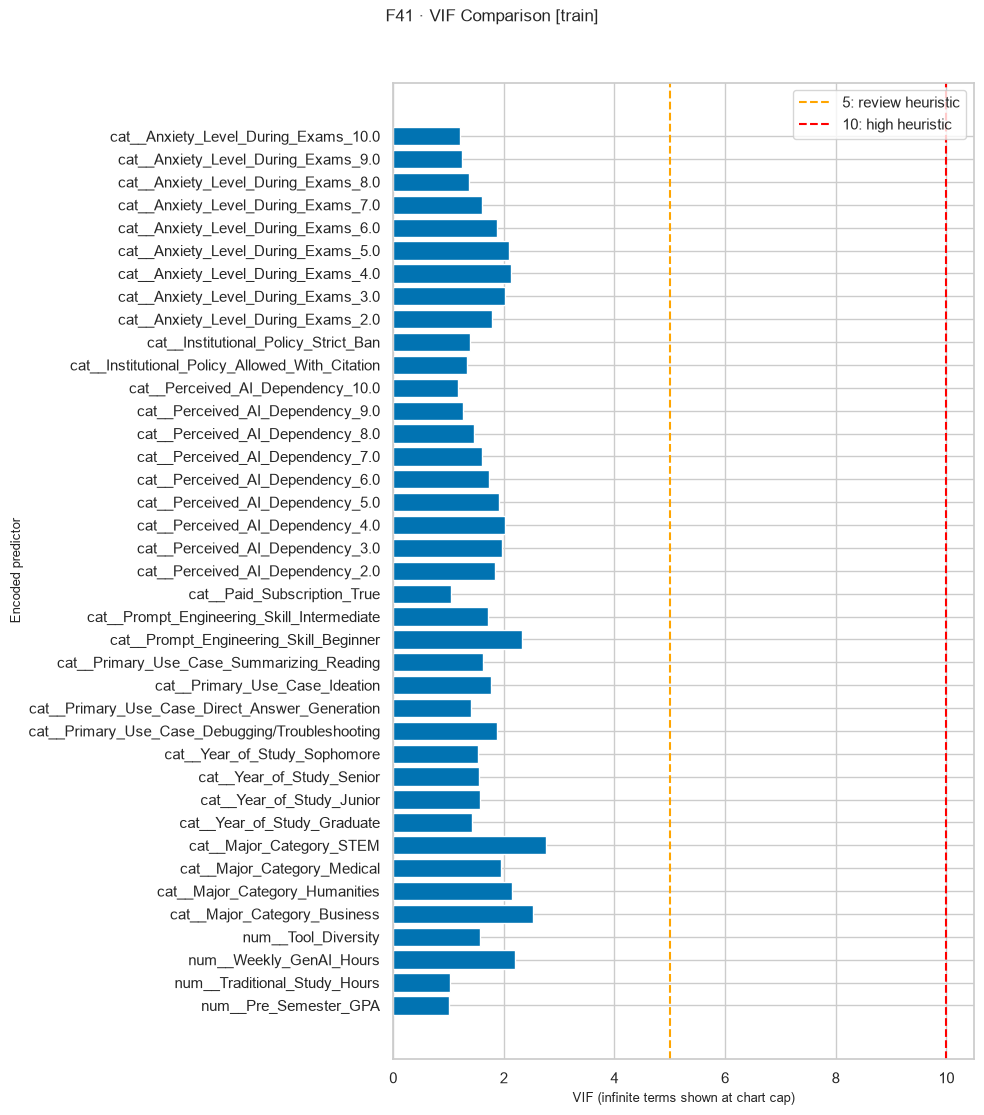

E3; rank 40/40. VIF is term-specific; no invented feature importance score.

**T31 · Regression Assumption Diagnostics** — scope: `train`; 10 rows. 

,check,value,method,limitation
0,mean specification,-3.5434e-15,train residual mean; inspect residual vs fitte...,zero mean with intercept does not prove linearity
1,residual variance,2.5816e-02,SSE / residual df,inspect scale-location; heteroscedasticity pos...
2,residual normality,-2.1842e-01,residual skewness + histogram + Q-Q,"normality affects inference, not a predictor n..."
3,independence,NaN,sampling/design audit; ID grouping before split,unknown sampling design and synthetic generato...
4,rank,4.0000e+01,40 design columns including intercept,pinv coefficients not identified if rank defic...
5,predictions above documented GPA endpoint,1.8930e+03,unclipped train fitted predictions,no silent clipping; floor unknown
6,large internally standardized residual,1.8800e+02,abs(e / sqrt(MSE*(1-h))) > 3,heuristic; retain observations
7,high leverage,1.3870e+03,h > 2p/n; threshold=0.0022857143; n=35000; p=40,"heuristic, not an exclusion rule"
8,large Cook distance,1.6410e+03,Cook D > 4/n; threshold=0.00011428571; rank us...,"heuristic; inspect, do not delete automatically"
9,optional formal tests,NaN,skipped: RUN_OPTIONAL_TESTS=False or singular ...,core visual/effect-size diagnostics retained


**T32 · Influential Observations Summary** — scope: `train`; 30 rows. Top 30 train rows by Cook D, identified only by stable keys. Flag totals in T31; no rows deleted.

,row_key,internally_standardized_residual,leverage,cooks_distance,abs_residual_gt3,leverage_gt_2p_n,cooks_gt_4_n,n,p
19941,c3443ae276b50eea9350d067cce4a875040da03f636688...,-5.5200,0.0081,0.0062,True,True,True,35000,40
29606,873476f5e3b5337aa0f863459f97ca485141953e277633...,-5.1700,0.0086,0.0058,True,True,True,35000,40
27378,5b8e6729fd7f78f955d96de17aa2a8b82058082ac596d6...,-4.9996,0.0092,0.0058,True,True,True,35000,40
30813,5ba75f5c363d68e8b03e6c6a764077e317696106460288...,-4.8126,0.0093,0.0054,True,True,True,35000,40
19513,0208fce88abd83847580bd51ed87d81f1bb9b2828479c5...,-5.0618,0.0081,0.0052,True,True,True,35000,40
12078,c10675e64eb1a7fc971b4f154da2feaf5db0ad9ac3d5f8...,-4.8568,0.0081,0.0048,True,True,True,35000,40
23927,ddd0ed7322ba3a9f9af4b854d77f7a71f8125254a1f2db...,-4.3538,0.0079,0.0038,True,True,True,35000,40
447,7c1ba8993dee4a1c23d416db7278dcfb5d28ad25e40c75...,-3.8934,0.0081,0.0031,True,True,True,35000,40
21110,c4b58175e8983d0f349db743f94a00817071128ca01117...,3.5486,0.0095,0.0030,True,True,True,35000,40
5489,5ad7b73b31f5e2c98716848df058211bf24b412c1bbfe5...,-4.6991,0.0054,0.0030,True,True,True,35000,40


Diagnostic model: E3; n=35,000; p=40; rank=40; no N x N hat matrix constructed.


In [12]:
diagnostic_model=models.get('E3',models.get('E2',models.get('E1')))
if diagnostic_model is None:
    raise ValueError('No exploratory OLS model could be fitted; inspect target and Pre GPA.')
diagnostic_id=next(k for k,v in models.items() if v is diagnostic_model)
X=diagnostic_model['design']
x=diagnostic_model['x']
fit=diagnostic_model['fit']
n,p=X.shape
centered=x-x.mean(axis=0)
scaled=centered/centered.std(axis=0,ddof=1)
gram=scaled.T@scaled/(n-1)
condition_raw=float(np.linalg.cond(X))
condition_standardized=float(np.linalg.cond(np.column_stack([np.ones(n),scaled])))
vif_records=[]
for j,name in enumerate(diagnostic_model['names']):
    other=np.arange(x.shape[1])!=j
    if other.any():
        cross=gram[other,j]
        beta=np.linalg.lstsq(gram[np.ix_(other,other)],cross,rcond=None)[0]
        r_squared=float(cross@beta)
    else:
        r_squared=0.0
    vif=np.inf if 1-r_squared<=1e-10 else 1/(1-r_squared)
    origin=next((c for c in sorted(diagnostic_model['features'],key=len,reverse=True) if str(name).split('__')[-1]==c or str(name).split('__')[-1].startswith(c+'_')),'unknown')
    vif_records.append(dict(model=diagnostic_id,scenario=diagnostic_model['scenario'],encoded_term=name,original_feature=origin,VIF=vif,
        heuristic='high' if vif>10 else 'review' if vif>=5 else 'low',rank=diagnostic_model['rank'],columns_including_intercept=p,
        n=n,condition_number_raw=condition_raw,condition_number_standardized=condition_standardized,
        singular=diagnostic_model['rank']<p,method='correlation Gram auxiliary regression with intercept'))
vif_table=save_table('T28',vif_records)
fig,ax=plt.subplots(figsize=(10,max(5,.28*len(vif_table))))
finite=vif_table.VIF.replace(np.inf,np.nan)
cap=max(11,float(finite.max()) if finite.notna().any() else 11)
ax.barh(vif_table.encoded_term,vif_table.VIF.replace(np.inf,cap))
ax.axvline(5,color='orange',ls='--',label='5: review heuristic')
ax.axvline(10,color='red',ls='--',label='10: high heuristic')
ax.set(xlabel='VIF (infinite terms shown at chart cap)',ylabel='Encoded predictor')
ax.legend()
save_figure('F41',fig,caption=f'{diagnostic_id}; rank {diagnostic_model["rank"]}/{p}. VIF is term-specific; no invented feature importance score.')

fitted=np.asarray(fit.fittedvalues)
residual=y_train-fitted
leverage=np.einsum('ij,jk,ik->i',X,np.asarray(fit.normalized_cov_params),X)
mse_train=float(np.sum(residual**2)/(n-diagnostic_model['rank']))
denom=np.sqrt(mse_train*np.maximum(1-leverage,np.finfo(float).eps))
standardized=residual/denom
cooks=(residual**2/(diagnostic_model['rank']*mse_train))*leverage/np.maximum(1-leverage,np.finfo(float).eps)**2
diagnostic_records=[
 dict(check='mean specification',value=float(residual.mean()),method='train residual mean; inspect residual vs fitted and key predictors',limitation='zero mean with intercept does not prove linearity'),
 dict(check='residual variance',value=mse_train,method='SSE / residual df',limitation='inspect scale-location; heteroscedasticity possible'),
 dict(check='residual normality',value=float(pd.Series(residual).skew()),method='residual skewness + histogram + Q-Q',limitation='normality affects inference, not a predictor normality requirement'),
 dict(check='independence',value=np.nan,method='sampling/design audit; ID grouping before split',limitation='unknown sampling design and synthetic generator; residual plots cannot verify independence'),
 dict(check='rank',value=diagnostic_model['rank'],method=f'{p} design columns including intercept',limitation='pinv coefficients not identified if rank deficient'),
 dict(check='predictions above documented GPA endpoint',value=int((fitted>GPA_UPPER_BOUNDARY).sum()) if GPA_UPPER_BOUNDARY is not None else np.nan,
      method='unclipped train fitted predictions',limitation='no silent clipping; floor unknown'),
 dict(check='large internally standardized residual',value=int((np.abs(standardized)>3).sum()),method='abs(e / sqrt(MSE*(1-h))) > 3',limitation='heuristic; retain observations'),
 dict(check='high leverage',value=int((leverage>2*p/n).sum()),method=f'h > 2p/n; threshold={2*p/n:.8g}; n={n}; p={p}',limitation='heuristic, not an exclusion rule'),
 dict(check='large Cook distance',value=int((cooks>4/n).sum()),method=f'Cook D > 4/n; threshold={4/n:.8g}; rank used in Cook denominator',limitation='heuristic; inspect, do not delete automatically')]
if RUN_OPTIONAL_TESTS and diagnostic_model['rank']==p:
    lm,lmp,fvalue,fp=het_breuschpagan(residual,X)
    jb=stats.jarque_bera(residual)
    diagnostic_records.extend([
        dict(check='Breusch-Pagan',value=float(lmp),method=f'LM={lm:.8g}; p-value shown',limitation='sensitive at large n; no causal/sampling inference'),
        dict(check='Jarque-Bera',value=float(jb.pvalue),method=f'statistic={jb.statistic:.8g}; p-value shown',limitation='large-n sensitivity; inspect practical departure')])
else:
    diagnostic_records.append(dict(check='optional formal tests',value=np.nan,method='skipped: RUN_OPTIONAL_TESTS=False or singular design',limitation='core visual/effect-size diagnostics retained'))
diagnostics=save_table('T31',diagnostic_records)
influence=pd.DataFrame({'row_key':row_keys.loc[train.index].to_numpy(),'internally_standardized_residual':standardized,
    'leverage':leverage,'cooks_distance':cooks,'abs_residual_gt3':np.abs(standardized)>3,
    'leverage_gt_2p_n':leverage>2*p/n,'cooks_gt_4_n':cooks>4/n,'n':n,'p':p})
save_table('T32',influence.nlargest(min(30,n),'cooks_distance'),caption='Top 30 train rows by Cook D, identified only by stable keys. Flag totals in T31; no rows deleted.')
print(f'Diagnostic model: {diagnostic_id}; n={n:,}; p={p}; rank={diagnostic_model["rank"]}; no N x N hat matrix constructed.')

### 9.3 Residual and influence diagnostics (train)

Residual = actual − fitted. Internally standardized residual dùng MSE và leverage; Cook's D tính bằng công thức vectorized,
không tạo hat matrix N×N. Các threshold chỉ để điều tra, không tự động loại observations.
Đồ thị residual theo predictor là kiểm tra conditional mean sau mô hình; không suy independence từ đồ thị.
Nếu heteroscedasticity/ceiling rõ, xem robust SE hoặc model specification khác trong training sau EDA.

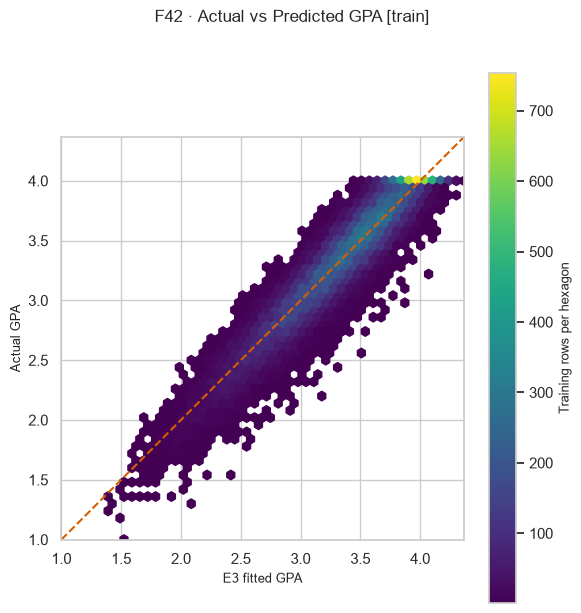

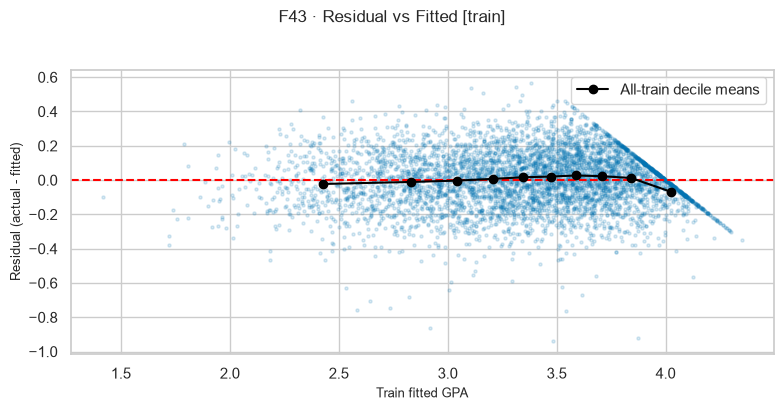

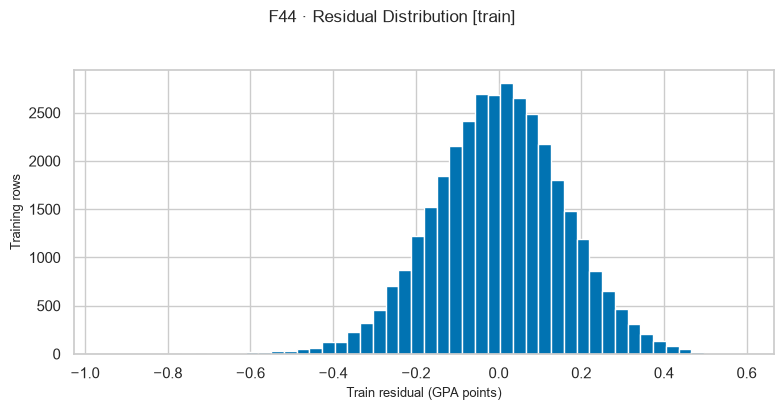

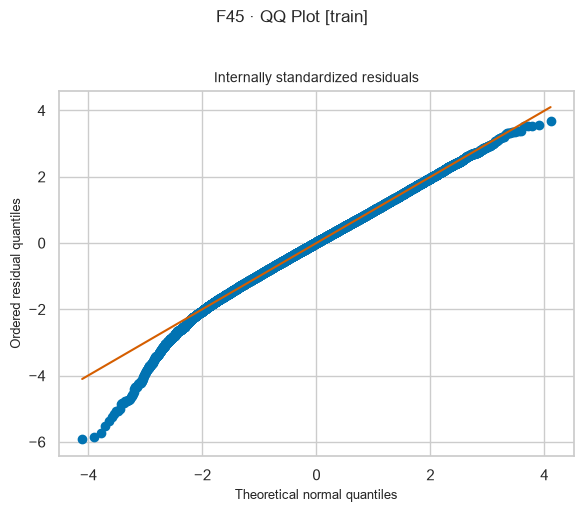

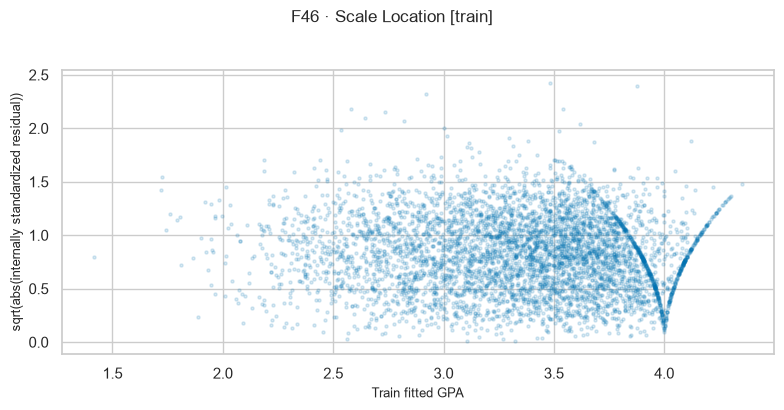

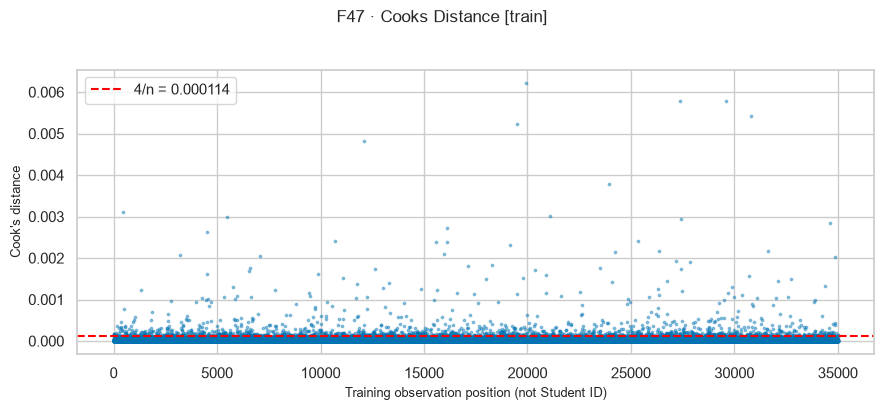

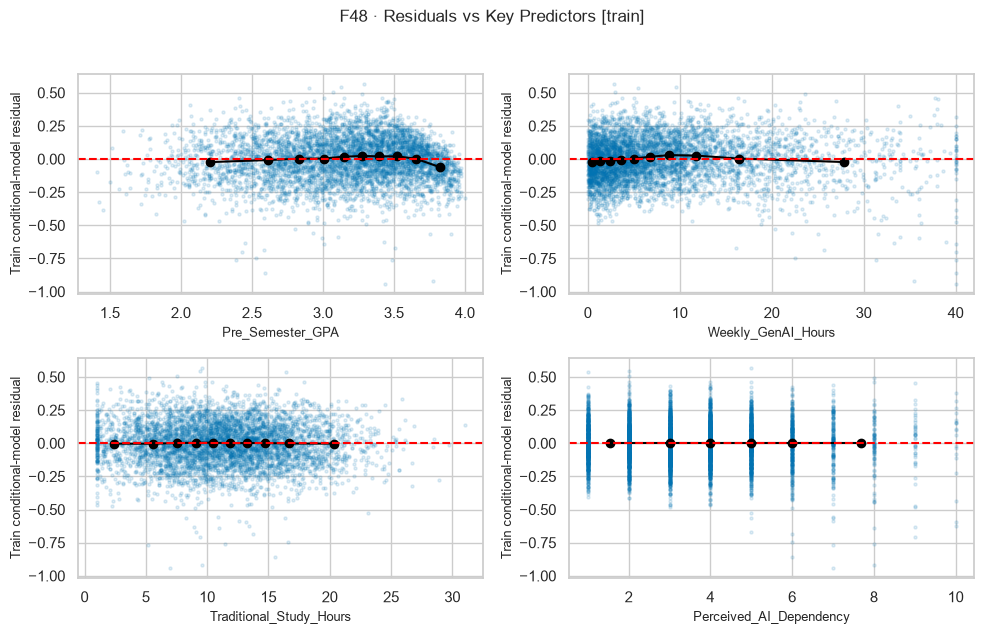

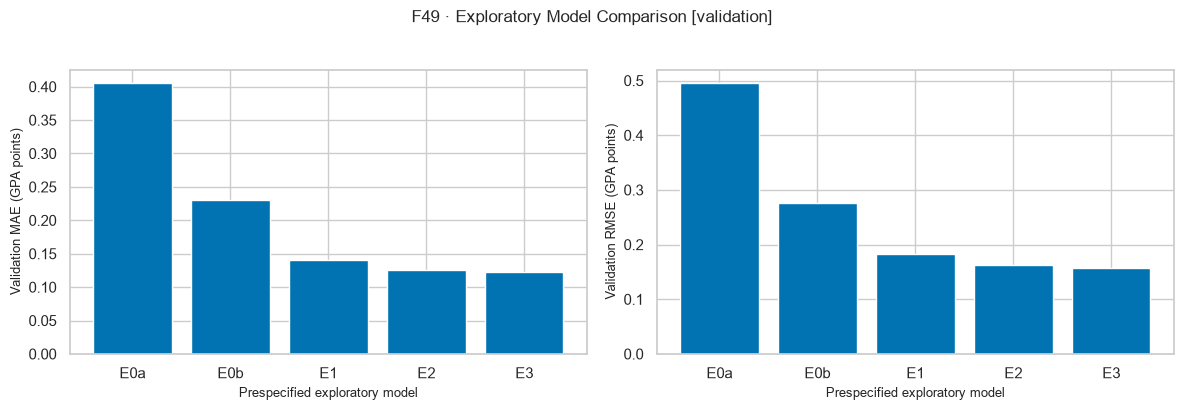

Same validation rows; conditional models do not establish deployment forecast performance.

**Diagnostics.** E3: rank=40/40, max finite VIF=2.768, |internally standardized residual|>3: 188; Cook D>4/n: 1,641. [T28/T31/T32] Inspect F43/F46 cho mean specification/variance; các flag không chứng minh dữ liệu sai.

In [13]:
fig,ax=plt.subplots(figsize=(6,6))
h=ax.hexbin(fitted,y_train,gridsize=45,mincnt=1,cmap='viridis')
limits=[min(fitted.min(),y_train.min()),max(fitted.max(),y_train.max())]
ax.plot(limits,limits,'r--')
ax.set(xlabel=f'{diagnostic_id} fitted GPA',ylabel='Actual GPA',xlim=limits,ylim=limits,aspect='equal')
fig.colorbar(h,ax=ax,label='Training rows per hexagon')
save_figure('F42',fig)
diagnostic_frame=pd.DataFrame({'fitted':fitted,'residual':residual,'standardized':standardized,'leverage':leverage,'cooks':cooks},index=train.index)
shown=plot_sample(diagnostic_frame)
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(shown.fitted,shown.residual,s=5,alpha=.15)
ax.axhline(0,color='red',ls='--')
trend=binned_trend(diagnostic_frame,'fitted','residual')
ax.plot(trend.x_mean,trend.y_mean,'o-',color='black',label='All-train decile means')
ax.set(xlabel='Train fitted GPA',ylabel='Residual (actual - fitted)')
ax.legend()
save_figure('F43',fig)
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(residual,bins=50)
ax.set(xlabel='Train residual (GPA points)',ylabel='Training rows')
save_figure('F44',fig)
fig,ax=plt.subplots(figsize=(6,5))
stats.probplot(standardized,dist='norm',plot=ax)
ax.set(title='Internally standardized residuals',xlabel='Theoretical normal quantiles',ylabel='Ordered residual quantiles')
save_figure('F45',fig)
fig,ax=plt.subplots(figsize=(8,4))
ax.scatter(shown.fitted,np.sqrt(np.abs(shown.standardized)),s=5,alpha=.15)
ax.set(xlabel='Train fitted GPA',ylabel='sqrt(abs(internally standardized residual))')
save_figure('F46',fig)
fig,ax=plt.subplots(figsize=(9,4))
ax.scatter(np.arange(n),cooks,s=3,alpha=.4)
ax.axhline(4/n,color='red',ls='--',label=f'4/n = {4/n:.3g}')
ax.set(xlabel='Training observation position (not Student ID)',ylabel="Cook's distance")
ax.legend()
save_figure('F47',fig)
residual_keys=[c for c in ['Pre_Semester_GPA',H,'Traditional_Study_Hours','Perceived_AI_Dependency'] if c in train]
fig,axes=axes_grid(len(residual_keys),columns=2)
for ax,c in zip(axes,residual_keys):
    part=pd.DataFrame({c:train[c],'residual':residual}).dropna()
    shown_part=plot_sample(part)
    ax.scatter(shown_part[c],shown_part.residual,s=5,alpha=.12)
    trend=binned_trend(part,c,'residual')
    ax.plot(trend.x_mean,trend.y_mean,'o-',color='black')
    ax.axhline(0,color='red',ls='--')
    ax.set(xlabel=c,ylabel='Train conditional-model residual')
save_figure('F48',fig)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,metric in zip(axes,['MAE','RMSE']):
    ax.bar(results.model,results[metric])
    ax.set(xlabel='Prespecified exploratory model',ylabel=f'Validation {metric} (GPA points)')
save_figure('F49',fig,'validation',caption='Same validation rows; conditional models do not establish deployment forecast performance.')
note(f'**Diagnostics.** {diagnostic_id}: rank={diagnostic_model["rank"]}/{p}, '
     f'max finite VIF={vif_table.VIF.replace(np.inf,np.nan).max():.3f}, '
     f'|internally standardized residual|>3: {(np.abs(standardized)>3).sum():,}; '
     f'Cook D>4/n: {(cooks>4/n).sum():,}. [T28/T31/T32] '
     'Inspect F43/F46 cho mean specification/variance; các flag không chứng minh dữ liệu sai.')

## Section 10 — Feature Engineering Exploration

**Method.** Transformations chỉ fit train; giữ hierarchy (H + H², main effects + interactions).
Centering dùng `mean_train(H)`; log1p cần H≥0; không ghép raw H và centered H cùng intercept.
Hours cùng đơn vị tuần nhưng chưa xác minh AI usage chỉ dành cho học và không overlap; **skip Total Study Hours/AI Study Ratio** mặc định.
Ordinal Dependency/Anxiety chưa được chứng minh equal spacing nên numeric-product interactions chỉ là proposal; prompt dùng reference-coded dummy interaction.
Một quadratic extension được định trước để so sánh thăm dò trên validation, không tìm kiếm degree/hyperparameters.

**T33 · Derived Feature Definitions** — scope: `train`; 10 rows. 

,feature,formula,status,constraint,fit_scope
0,GPA_Change,Post_Semester_GPA - Pre_Semester_GPA,analytical outcome only,never predictor,no fitted parameters
1,Total_Study_Hours,H + Traditional_Study_Hours,skipped,units + study-only coverage + no double count ...,train
2,AI_Study_Ratio,H / Total_Study_Hours,skipped,valid total >0; zero denominator -> missing,train
3,AI_Hours_Squared,H**2,candidate,retain H; redundancy audit,train
4,Log_AI_Hours,log1p(H),candidate,finite nonnegative H,train
5,Centered_AI_Hours,H - mean_train(H),candidate,never use with raw H and intercept,train mean
6,Centered_AI_Hours_Squared,(H - mean_train(H))**2,candidate,retain H or centered H; no duplicate linear term,train mean
7,AI_Dependency_Interaction,H * Dependency,proposal only; skipped numeric product,ordinal interval-distance assumption and timin...,train
8,AI_Prompt_Interaction,centered H * reference-coded Prompt dummy,candidate,train reference; retain prompt dummies and H,train reference and mean
9,Study_Anxiety_Interaction,Study * Anxiety,proposal only; skipped numeric product,high temporal risk; interval-distance assumpti...,train


**T34 · Derived Feature Statistics** — scope: `train`; 6 rows. 

,feature,valid_n,mean,median,std,minimum,maximum,missing_pct,skewness,pearson_post,spearman_post,pearson_change,decision
0,AI_Hours_Squared,35000,1.3977e+02,33.6400,267.6172,0.0000e+00,1600.0000,0.0,3.2807,-0.0321,0.0079,-0.0795,candidate only; temporal assumptions and hiera...
1,Log_AI_Hours,35000,1.8776e+00,1.9169,0.8865,0.0000e+00,3.7136,0.0,-0.0888,0.0028,0.0079,0.0029,candidate only; temporal assumptions and hiera...
2,Centered_AI_Hours,35000,4.7424e-16,-2.6366,8.2825,-8.4366e+00,31.5634,0.0,1.6062,-0.0191,0.0079,-0.0481,candidate only; temporal assumptions and hiera...
3,Centered_AI_Hours_Squared,35000,6.8598e+01,29.2317,145.9165,1.1355e-05,996.2463,0.0,4.3665,-0.0405,-0.0429,-0.0998,candidate only; temporal assumptions and hiera...
4,H_x_Prompt_Beginner,35000,-6.1049e-02,0.0000,4.9296,-8.4366e+00,31.5634,0.0,2.6659,-0.0091,0.0096,-0.0358,candidate only; temporal assumptions and hiera...
5,H_x_Prompt_Intermediate,35000,-2.3101e-02,0.0000,4.8873,-8.4366e+00,31.5634,0.0,2.6359,-0.0140,0.0043,-0.0325,candidate only; temporal assumptions and hiera...


**T35 · Original vs Transformed Comparison** — scope: `validation`; 7 rows. Skew/correlation/pair VIF are TRAIN; only explicitly populated performance fields use VALIDATION. No test data.

,candidate,valid_n,skewness,pearson_post,spearman_post,pair_vif_with_linear_H,validation_MAE,validation_RMSE,validation_R2,quadratic_coefficient,reason
0,Original_H,35000,1.6062,-0.0191,0.0079,NaN,0.1230,0.1571,0.8993,NaN,"E3 conditional baseline, fixed feature set; va..."
1,AI_Hours_Squared,35000,3.2807,-0.0321,0.0079,7.8259,NaN,NaN,NaN,NaN,distribution/correlation only; not an automati...
2,Log_AI_Hours,35000,-0.0888,0.0028,0.0079,NaN,NaN,NaN,NaN,NaN,distribution/correlation only; not an automati...
3,Centered_AI_Hours,35000,1.6062,-0.0191,0.0079,NaN,NaN,NaN,NaN,NaN,distribution/correlation only; not an automati...
4,Centered_AI_Hours_Squared,35000,4.3665,-0.0405,-0.0429,2.3266,0.1226,0.1563,0.9003,-0.0002,"Fixed E3 + centered H^2; retain H, no extra li..."
5,H_x_Prompt_Beginner,35000,2.6659,-0.0091,0.0096,NaN,NaN,NaN,NaN,NaN,distribution/correlation only; not an automati...
6,H_x_Prompt_Intermediate,35000,2.6359,-0.0140,0.0043,NaN,NaN,NaN,NaN,NaN,distribution/correlation only; not an automati...


... (2 outputs left out)

**T37 · Scaling Recommendations** — scope: `train`; 16 rows. 

,feature,OLS,polynomial_ridge,fit_scope
0,Student_ID,not a predictor,not applicable,train only; never validation or test
1,Major_Category,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test
2,Year_of_Study,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test
3,Pre_Semester_GPA,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test
4,Weekly_GenAI_Hours,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test
5,Primary_Use_Case,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test
6,Prompt_Engineering_Skill,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test
7,Tool_Diversity,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test
8,Paid_Subscription,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test
9,Traditional_Study_Hours,no scaling required; raw-unit coefficients,standardize encoded numeric matrix inside trai...,train only; never validation or test


**T38 · Feature Selection Recommendations** — scope: `train`; 16 rows. 

,feature,decision,rationale,pearson_post,evidence,screening_policy
0,Student_ID,Exclude,role-based leakage guard,NaN,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
1,Major_Category,Conditional,timing unverified; retrospective analysis only,NaN,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
2,Year_of_Study,Conditional,timing unverified; retrospective analysis only,NaN,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
3,Pre_Semester_GPA,Keep,pre-semester availability,0.9264,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
4,Weekly_GenAI_Hours,Conditional,timing unverified; retrospective analysis only,-0.0191,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
5,Primary_Use_Case,Conditional,timing unverified; retrospective analysis only,NaN,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
6,Prompt_Engineering_Skill,Conditional,timing unverified; retrospective analysis only,NaN,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
7,Tool_Diversity,Conditional,timing unverified; retrospective analysis only,0.0260,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
8,Paid_Subscription,Conditional,timing unverified; retrospective analysis only,NaN,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...
9,Traditional_Study_Hours,Conditional,timing unverified; retrospective analysis only,0.1338,T19; T20; T28; T33; T35; T40,no elimination solely by marginal correlation ...


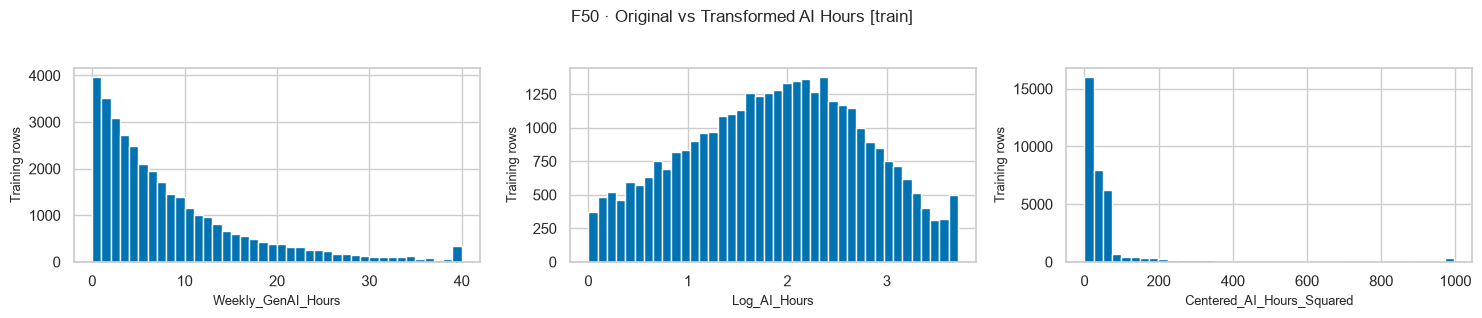

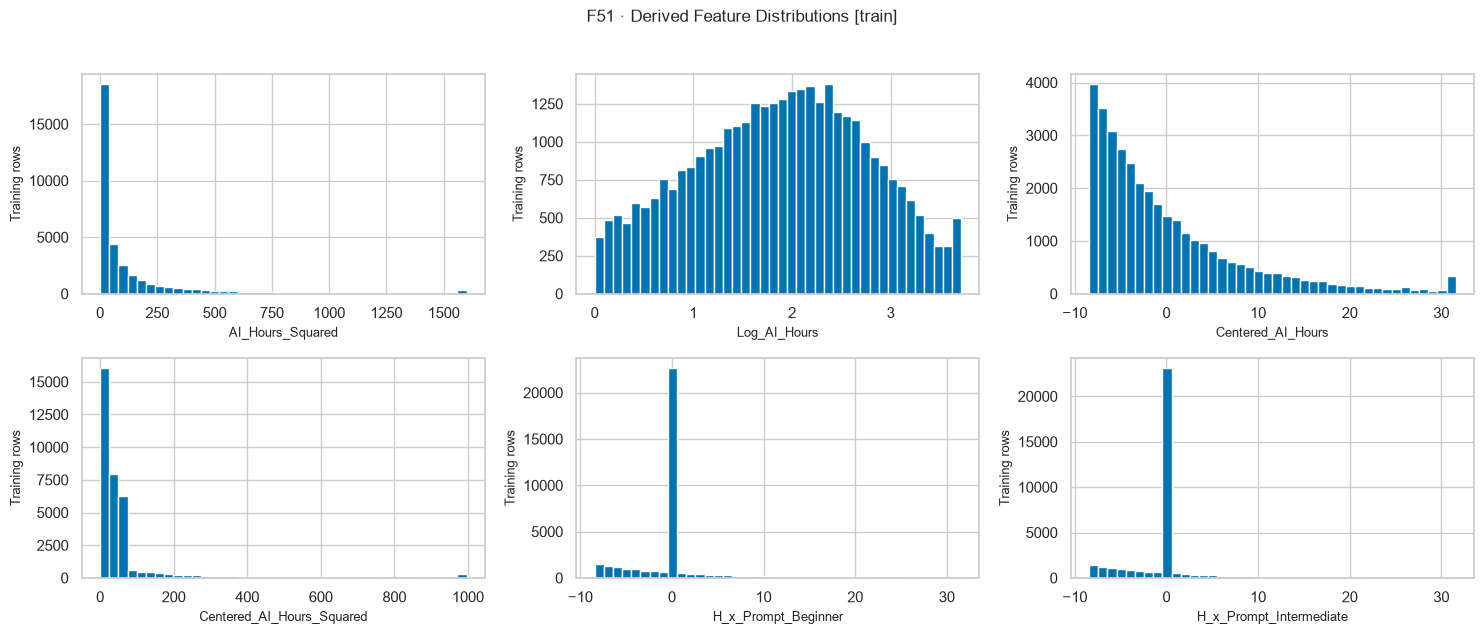

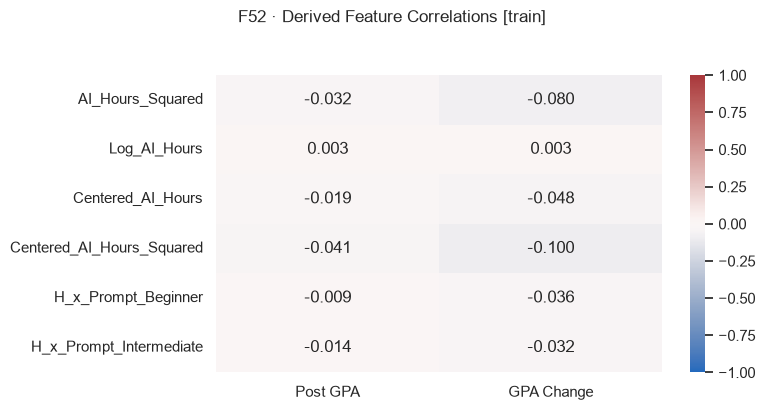

Marginal training correlations, not evidence of incremental forecast benefit.

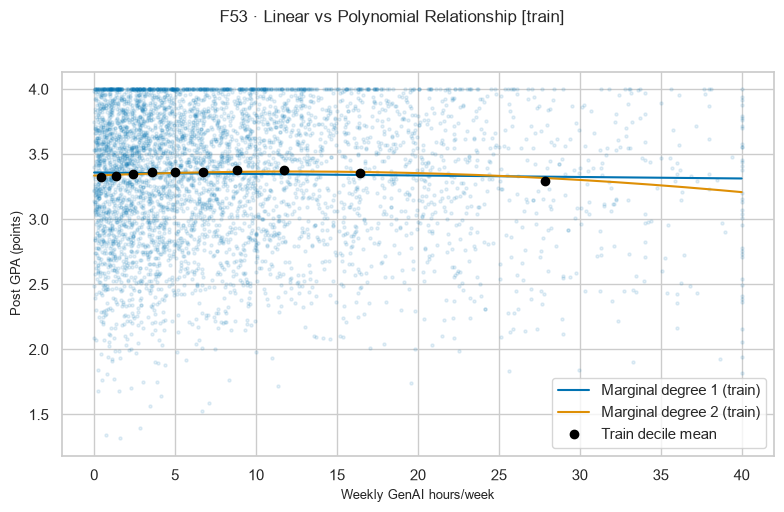

This figure is marginal. T35 quadratic validation comparison adjusts using fixed E3 features.

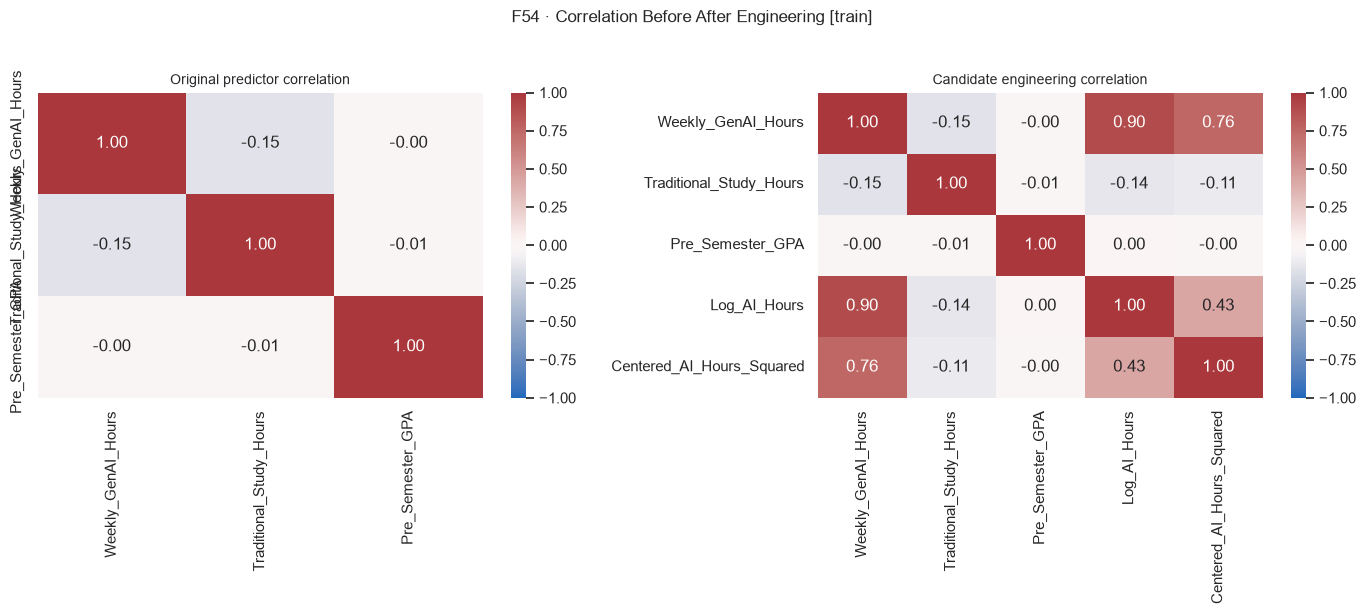

Audit candidates together; production design must avoid raw H + centered H or total + components.

**Recommendation.** T35 phân biệt giảm skewness với cải thiện validation. Centering có thể giảm tương quan H–H², nhưng không thay thế kiểm tra VIF toàn design. Total/ratio và numeric ordinal products chưa được tự ý thêm. Polynomial/interaction giữ main effects; Ridge cần scale và xác minh được môn học chấp nhận.

In [14]:
derived=pd.DataFrame(index=train.index)
definitions=[
 dict(feature='GPA_Change',formula='Post_Semester_GPA - Pre_Semester_GPA',status='analytical outcome only',constraint='never predictor',fit_scope='no fitted parameters'),
 dict(feature='Total_Study_Hours',formula='H + Traditional_Study_Hours',status='skipped' if not CONFIRMED_HOURS_ADDITIVE else 'conditional',constraint='units + study-only coverage + no double count must be verified',fit_scope='train'),
 dict(feature='AI_Study_Ratio',formula='H / Total_Study_Hours',status='skipped' if not CONFIRMED_HOURS_ADDITIVE else 'conditional',constraint='valid total >0; zero denominator -> missing',fit_scope='train'),
 dict(feature='AI_Hours_Squared',formula='H**2',status='candidate',constraint='retain H; redundancy audit',fit_scope='train'),
 dict(feature='Log_AI_Hours',formula='log1p(H)',status='candidate',constraint='finite nonnegative H',fit_scope='train'),
 dict(feature='Centered_AI_Hours',formula='H - mean_train(H)',status='candidate',constraint='never use with raw H and intercept',fit_scope='train mean'),
 dict(feature='Centered_AI_Hours_Squared',formula='(H - mean_train(H))**2',status='candidate',constraint='retain H or centered H; no duplicate linear term',fit_scope='train mean'),
 dict(feature='AI_Dependency_Interaction',formula='H * Dependency',status='proposal only; skipped numeric product',constraint='ordinal interval-distance assumption and timing unverified',fit_scope='train'),
 dict(feature='AI_Prompt_Interaction',formula='centered H * reference-coded Prompt dummy',status='candidate',constraint='train reference; retain prompt dummies and H',fit_scope='train reference and mean'),
 dict(feature='Study_Anxiety_Interaction',formula='Study * Anxiety',status='proposal only; skipped numeric product',constraint='high temporal risk; interval-distance assumption unverified',fit_scope='train')]
if H in train:
    h=train[H]
    h_mean=h.mean()
    derived['AI_Hours_Squared']=h**2
    derived['Log_AI_Hours']=np.log1p(h.where(h>=0))
    derived['Centered_AI_Hours']=h-h_mean
    derived['Centered_AI_Hours_Squared']=(h-h_mean)**2
    if 'Prompt_Engineering_Skill' in train:
        levels=sorted(train.Prompt_Engineering_Skill.dropna().astype(str).unique())
        prompt_ref=levels[0] if levels else None
        for level in levels[1:]:
            derived['H_x_Prompt_'+level]=(h-h_mean)*(train.Prompt_Engineering_Skill.astype('string').eq(level).astype(float))
        preprocessing_log.append(dict(model='engineering',feature='AI_Prompt_Interaction',action=f'centered train H x prompt dummy; reference={prompt_ref}; retain main effects'))
    if CONFIRMED_HOURS_ADDITIVE and 'Traditional_Study_Hours' in train:
        derived['Total_Study_Hours']=h+train.Traditional_Study_Hours
        derived['AI_Study_Ratio']=h/derived.Total_Study_Hours.where(derived.Total_Study_Hours>0)
else:
    for row in definitions:
        if row['feature']!='GPA_Change':
            row['status']='skipped: AI Hours absent'
save_table('T33',definitions)
derived_stats=[]
for c in derived:
    s=derived[c].dropna()
    derived_stats.append(dict(feature=c,valid_n=len(s),mean=s.mean(),median=s.median(),std=s.std(ddof=1),
        minimum=s.min(),maximum=s.max(),missing_pct=100*derived[c].isna().mean(),skewness=s.skew(),
        pearson_post=derived[c].corr(train[TARGET_COLUMN]),spearman_post=derived[c].corr(train[TARGET_COLUMN],method='spearman'),
        pearson_change=derived[c].corr(train.GPA_Change),decision='candidate only; temporal assumptions and hierarchy required'))
if len(derived_stats):
    save_table('T34',derived_stats)
else:
    skip('T34','No valid engineered features; AI Hours absent')

transformation_comparison=[]
if H in train:
    for name,series in [('Original_H',train[H]),*[(c,derived[c]) for c in derived]]:
        valid=series.dropna()
        transformation_comparison.append(dict(candidate=name,valid_n=len(valid),skewness=valid.skew(),
            pearson_post=series.corr(train[TARGET_COLUMN]),spearman_post=series.corr(train[TARGET_COLUMN],method='spearman'),
            pair_vif_with_linear_H=np.nan,validation_MAE=np.nan,validation_RMSE=np.nan,validation_R2=np.nan,
            quadratic_coefficient=np.nan,reason='distribution/correlation only; not an automatic feature selection rule'))
    for c,linear in [('AI_Hours_Squared',train[H]),('Centered_AI_Hours_Squared',derived.Centered_AI_Hours)]:
        corr=derived[c].corr(linear)
        for row in transformation_comparison:
            if row['candidate']==c:
                row['pair_vif_with_linear_H']=np.inf if pd.notna(corr) and 1-corr**2<=1e-10 else 1/(1-corr**2) if pd.notna(corr) else np.nan

    # Fixed conditional quadratic extension of E3 (same train/validation population), no tuning.
    if 'E3' in models and train[H].notna().any():
        base=models['E3']
        train_h=train[H].fillna(train[H].median()).to_numpy(float)
        val_h=validation[H].fillna(train[H].median()).to_numpy(float)
        h_center=float(train_h.mean())
        xd=np.column_stack([base['design'],(train_h-h_center)**2])
        xdv=np.column_stack([base['design_val'],(val_h-h_center)**2])
        engineering_rank=int(np.linalg.matrix_rank(xd))
        if engineering_rank==xd.shape[1]:
            quadratic_fit=sm.OLS(y_train,xd).fit()
            quadratic_prediction=quadratic_fit.predict(xdv)
            base_result=results.set_index('model').loc['E3']
            for row in transformation_comparison:
                if row['candidate']=='Original_H':
                    row.update(validation_MAE=base_result.MAE,validation_RMSE=base_result.RMSE,validation_R2=base_result.R2,
                        reason='E3 conditional baseline, fixed feature set; validation exploratory')
                elif row['candidate']=='Centered_AI_Hours_Squared':
                    row.update(validation_MAE=mean_absolute_error(y_validation,quadratic_prediction),
                        validation_RMSE=np.sqrt(mean_squared_error(y_validation,quadratic_prediction)),
                        validation_R2=r2_score(y_validation,quadratic_prediction),quadratic_coefficient=float(quadratic_fit.params[-1]),
                        reason='Fixed E3 + centered H^2; retain H, no extra linear duplicate; conditional/retrospective; not tuned')
        else:
            warnings_log.append('Quadratic extension skipped: rank deficient; polynomial coefficient not identifiable')
if transformation_comparison:
    save_table('T35',transformation_comparison,'validation',
        'Skew/correlation/pair VIF are TRAIN; only explicitly populated performance fields use VALIDATION. No test data.')
else:
    skip('T35','No applicable AI Hours transformation')

encoding_rows=[]
scaling_rows=[]
selection_rows=[]
for c in raw:
    sem=semantic.get(c,'unknown')
    forbidden=c in [ID_COLUMN,TARGET_COLUMN,*auxiliary] or c in extra_columns
    encoding='exclude from X' if forbidden else 'median imputation' if sem in ['continuous','discrete'] else 'mode imputation + one-hot drop-first; unknown categories handled'
    encoding_rows.append(dict(feature=c,semantic_type=sem,encoding=encoding,fit_scope='train only',
        ordinal_policy='one-hot by default; ranks used only for Spearman' if sem=='ordinal' else '',
        reason='ID/target/auxiliary/unknown forbidden in predictors' if forbidden else 'preserve units; avoid invented ordinal distances'))
    scaling_rows.append(dict(feature=c,OLS='no scaling required; raw-unit coefficients' if not forbidden else 'not a predictor',
        polynomial_ridge='standardize encoded numeric matrix inside training pipeline' if not forbidden else 'not applicable',
        fit_scope='train only; never validation or test'))
    association=pearson_table[pearson_table.feature.eq(c)&pearson_table.outcome.eq(TARGET_COLUMN)]
    selection_rows.append(dict(feature=c,decision='Exclude' if forbidden else 'Keep' if c in VERIFIED_AVAILABLE else 'Conditional',
        rationale='role-based leakage guard' if forbidden else 'pre-semester availability' if c in VERIFIED_AVAILABLE else 'timing unverified; retrospective analysis only',
        pearson_post=association.coefficient.iloc[0] if len(association) else np.nan,
        evidence='T19; T20; T28; T33; T35; T40',screening_policy='no elimination solely by marginal correlation or skewness'))
save_table('T36',encoding_rows)
save_table('T37',scaling_rows)
save_table('T38',selection_rows)
if H in train and derived.shape[1]:
    fig,axes=axes_grid(3)
    for ax,c in zip(axes,[H,'Log_AI_Hours','Centered_AI_Hours_Squared']):
        s=train[c] if c in train else derived[c]
        ax.hist(s.dropna(),bins=40)
        ax.set(xlabel=c,ylabel='Training rows')
    save_figure('F50',fig)
    fig,axes=axes_grid(len(derived.columns))
    for ax,c in zip(axes,derived):
        ax.hist(derived[c].dropna(),bins=40)
        ax.set(xlabel=c,ylabel='Training rows')
    save_figure('F51',fig)
    transform_corr=pd.DataFrame({'Post GPA':derived.corrwith(train[TARGET_COLUMN]),
        'GPA Change':derived.corrwith(train.GPA_Change)})
    fig,ax=plt.subplots(figsize=(8,max(4,.5*len(transform_corr))))
    sns.heatmap(transform_corr,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.3f',ax=ax)
    save_figure('F52',fig,caption='Marginal training correlations, not evidence of incremental forecast benefit.')
    pair=train[[H,TARGET_COLUMN]].dropna()
    if pair[H].nunique()>=3:
        fig,ax=plt.subplots(figsize=(8,5))
        shown_pair=plot_sample(pair)
        ax.scatter(shown_pair[H],shown_pair[TARGET_COLUMN],s=5,alpha=.1)
        grid=np.linspace(pair[H].min(),pair[H].max(),150)
        for degree in [1,2]:
            coefs=np.polyfit(pair[H],pair[TARGET_COLUMN],degree)
            ax.plot(grid,np.polyval(coefs,grid),label=f'Marginal degree {degree} (train)')
        trend=binned_trend(train,H,TARGET_COLUMN)
        ax.plot(trend.x_mean,trend.y_mean,'o',color='black',label='Train decile mean')
        ax.legend()
        ax.set(xlabel='Weekly GenAI hours/week',ylabel='Post GPA (points)')
        save_figure('F53',fig,caption='This figure is marginal. T35 quadratic validation comparison adjusts using fixed E3 features.')
    else:
        skip('F53','AI Hours has fewer than 3 distinct values for quadratic comparison')
    before=train[[c for c in [H,'Traditional_Study_Hours','Pre_Semester_GPA'] if c in train]].corr()
    after=pd.concat([train[[c for c in [H,'Traditional_Study_Hours','Pre_Semester_GPA'] if c in train]],derived[['Log_AI_Hours','Centered_AI_Hours_Squared']]],axis=1).corr()
    fig,axes=plt.subplots(1,2,figsize=(14,6))
    for ax,matrix,label in [(axes[0],before,'Original predictor correlation'),(axes[1],after,'Candidate engineering correlation')]:
        sns.heatmap(matrix,vmin=-1,vmax=1,center=0,cmap='vlag',annot=True,fmt='.2f',ax=ax)
        ax.set_title(label)
    save_figure('F54',fig,caption='Audit candidates together; production design must avoid raw H + centered H or total + components.')
else:
    for aid in ['F50','F51','F52','F53','F54']:
        skip(aid,'AI Hours unavailable; no derived feature analysis')
note('**Recommendation.** T35 phân biệt giảm skewness với cải thiện validation. Centering có thể giảm tương quan H–H², '
     'nhưng không thay thế kiểm tra VIF toàn design. Total/ratio và numeric ordinal products chưa được tự ý thêm. '
     'Polynomial/interaction giữ main effects; Ridge cần scale và xác minh được môn học chấp nhận.')

## Section 11 — Data Leakage & Bias Analysis

**Method.** Feature availability là guard thực thi từ trước split/model fit. Chỉ Pre GPA có temporal evidence rõ từ mô tả;
AI/study/policy/demographic còn lại chưa có timestamp nên conditional, anxiety có temporal risk cao.
Test audit dùng assignment/group keys và full-file structural hashes, không profile target test.
Synthetic status/license được xác nhận từ metadata chính thức; không suy thêm sampling design hoặc cơ chế sinh dữ liệu.

**T39 · Leakage Risk Assessment** — scope: `split_metadata`; 17 rows. 

,feature,issue,risk,action,evidence
0,Student_ID,role/target leakage,high,Exclude from X,source metadata; T02; T33; code model allowlist
1,Major_Category,temporal availability,conditional,Conditional only; verify timestamp before fore...,source metadata; T02; T33; code model allowlist
2,Year_of_Study,temporal availability,conditional,Conditional only; verify timestamp before fore...,source metadata; T02; T33; code model allowlist
3,Pre_Semester_GPA,temporal availability,low,Allow baseline,source metadata; T02; T33; code model allowlist
4,Weekly_GenAI_Hours,temporal availability,conditional,Conditional only; verify timestamp before fore...,source metadata; T02; T33; code model allowlist
5,Primary_Use_Case,temporal availability,conditional,Conditional only; verify timestamp before fore...,source metadata; T02; T33; code model allowlist
6,Prompt_Engineering_Skill,temporal availability,conditional,Conditional only; verify timestamp before fore...,source metadata; T02; T33; code model allowlist
7,Tool_Diversity,temporal availability,conditional,Conditional only; verify timestamp before fore...,source metadata; T02; T33; code model allowlist
8,Paid_Subscription,temporal availability,conditional,Conditional only; verify timestamp before fore...,source metadata; T02; T33; code model allowlist
9,Traditional_Study_Hours,temporal availability,conditional,Conditional only; verify timestamp before fore...,source metadata; T02; T33; code model allowlist


**T40 · Feature Availability Matrix** — scope: `split_metadata`; 16 rows. 

,feature,availability,prediction_cutoff,source_evidence,allowed_scenario,forecast_eligible,leakage_risk
0,Student_ID,unavailable,Before end-of-semester GPA is known,post-semester outcome / identifier / unknown role,not a predictor,False,high
1,Major_Category,unknown,Before end-of-semester GPA is known,measurement timing not specified by publisher,conditional / retrospective only,False,conditional
2,Year_of_Study,unknown,Before end-of-semester GPA is known,measurement timing not specified by publisher,conditional / retrospective only,False,conditional
3,Pre_Semester_GPA,available,Before end-of-semester GPA is known,GPA at start of semester,pre-semester baseline,True,low
4,Weekly_GenAI_Hours,unknown,Before end-of-semester GPA is known,measurement timing not specified by publisher,conditional / retrospective only,False,conditional
5,Primary_Use_Case,unknown,Before end-of-semester GPA is known,measurement timing not specified by publisher,conditional / retrospective only,False,conditional
6,Prompt_Engineering_Skill,unknown,Before end-of-semester GPA is known,measurement timing not specified by publisher,conditional / retrospective only,False,conditional
7,Tool_Diversity,unknown,Before end-of-semester GPA is known,measurement timing not specified by publisher,conditional / retrospective only,False,conditional
8,Paid_Subscription,unknown,Before end-of-semester GPA is known,measurement timing not specified by publisher,conditional / retrospective only,False,conditional
9,Traditional_Study_Hours,unknown,Before end-of-semester GPA is known,measurement timing not specified by publisher,conditional / retrospective only,False,conditional


**T41 · Split Integrity Report** — scope: `split_metadata`; 19 rows. 

,check,left,right,value,passed,scope
0,split row count,train,,35000,True,split_metadata
1,row-key overlap,train,validation,0,True,split_metadata
2,connected-group overlap,train,validation,0,True,split_metadata
3,content-hash overlap,train,validation,0,True,split_metadata
4,Student ID overlap,train,validation,0,True,split_metadata
5,row-key overlap,train,test,0,True,split_metadata
6,connected-group overlap,train,test,0,True,split_metadata
7,content-hash overlap,train,test,0,True,split_metadata
8,Student ID overlap,train,test,0,True,split_metadata
9,split row count,validation,,7500,True,split_metadata


**T42 · Dataset Bias and Limitations** — scope: `split_metadata`; 9 rows. 

,issue,status,evidence,consequence,action
0,synthetic provenance,synthetic,official user_specified_sources in saved metadata,Learns simulated patterns; external validity t...,No causal or population claims
1,license and version,CC0-1.0; publisher version=1,https://www.kaggle.com/datasets/laveshjadon/ai...,Local bytes not authenticated to publisher che...,Record local SHA-256; retain source metadata s...
2,sampling / independence,unknown,publisher does not describe sampling or genera...,SE/CI are descriptive; representative inferenc...,Audit real cohort before external use
3,feature timing,mostly unknown,T40; source definitions,E2/E3 not verified forecasts,Obtain measurement dates / freeze cutoff
4,hours coverage,study additivity unverified,AI usage hours not explicitly restricted to study,Total/ratio may misstate study time,Skip unless documented
5,GPA boundaries / precision,upper documented; lower and precision unverified,T18; source approximate ranges,Floor effect unknown; equality tolerance only ...,No inferred floor; no silent prediction clipping
6,group imbalance,0 rare category rows in frequency table,T12; T21; T24,Small subgroups have unstable summaries,Flag n<30; report counts
7,holdout policy,test untouched for analysis,T41; split assignments,"Validation is exploratory, not final estimate",Final test only after model specification frozen
8,course source PDFs,unavailable in workspace,brief.md references two PDF files,Exact original rubric not verified,Confirm final model count versus team size and...


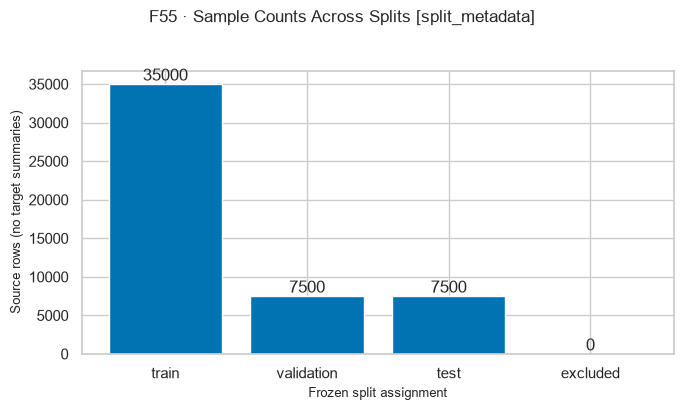

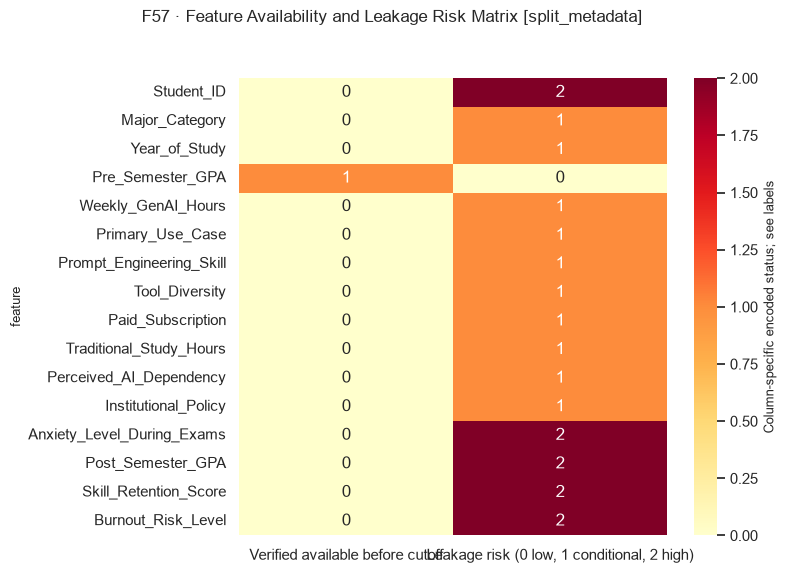

Administrative status matrix, not a fitted feature importance or statistical score. Source evidence in T40.

**Implication.** Split/role guards đều được kiểm tra bằng assertion ở T41. Synthetic data và timing unknown là giới hạn hiện hữu; dù validation score tốt vẫn chưa chứng minh AI gây GPA thay đổi hay mô hình dùng được trên cohort thật.

In [15]:
availability_rows=[]
leakage_rows=[]
for c in raw:
    forbidden=c in [ID_COLUMN,TARGET_COLUMN,*auxiliary] or c in extra_columns
    availability='unavailable' if forbidden else 'available' if c in VERIFIED_AVAILABLE else 'unknown'
    risk='high' if forbidden or c=='Anxiety_Level_During_Exams' else 'low' if c in VERIFIED_AVAILABLE else 'conditional'
    availability_rows.append(dict(feature=c,availability=availability,prediction_cutoff=PREDICTION_CUTOFF,
        source_evidence='GPA at start of semester' if c in VERIFIED_AVAILABLE else 'post-semester outcome / identifier / unknown role' if forbidden else 'measurement timing not specified by publisher',
        allowed_scenario='not a predictor' if forbidden else 'pre-semester baseline' if c in VERIFIED_AVAILABLE else 'conditional / retrospective only',
        forecast_eligible=bool(c in VERIFIED_AVAILABLE and not forbidden),leakage_risk=risk))
    leakage_rows.append(dict(feature=c,issue='role/target leakage' if forbidden else 'temporal availability',risk=risk,
        action='Exclude from X' if forbidden else 'Allow baseline' if c in VERIFIED_AVAILABLE else 'Conditional only; verify timestamp before forecasting',
        evidence='source metadata; T02; T33; code model allowlist'))
leakage_rows.append(dict(feature='GPA_Change',issue='target-derived leakage',risk='high',action='Analytical target only; never X',evidence='Post minus Pre formula'))
save_table('T39',leakage_rows,'split_metadata')
availability_table=save_table('T40',availability_rows,'split_metadata')
split_checks=[]
split_labels=['train','validation','test']
for i,left in enumerate(split_labels):
    li=assignments[assignments.split.eq(left)]
    split_checks.append(dict(check='split row count',left=left,right='',value=len(li),passed=len(li)>0,scope='split_metadata'))
    for right in split_labels[i+1:]:
        ri=assignments[assignments.split.eq(right)]
        row_overlap=len(set(li.row_key)&set(ri.row_key))
        group_overlap=len(set(li.group_key)&set(ri.group_key))
        content_overlap=len(set(content_hash.loc[li.source_row_position])&set(content_hash.loc[ri.source_row_position]))
        for name,value in [('row-key overlap',row_overlap),('connected-group overlap',group_overlap),('content-hash overlap',content_overlap)]:
            split_checks.append(dict(check=name,left=left,right=right,value=value,passed=value==0,scope='split_metadata'))
        if ID_COLUMN in clean:
            overlap=len(set(clean.loc[li.source_row_position,ID_COLUMN].dropna()) & set(clean.loc[ri.source_row_position,ID_COLUMN].dropna()))
            split_checks.append(dict(check='Student ID overlap',left=left,right=right,value=overlap,passed=overlap==0,scope='split_metadata'))
split_checks.extend([
    dict(check='all source rows assigned once',left='all',right='',value=len(assignments),passed=len(assignments)==len(raw) and assignments.row_key.is_unique,scope='split_metadata'),
    dict(check='raw CSV unchanged',left='raw',right='',value=raw_fingerprint,passed=digest_file(csv_path)==raw_fingerprint,scope='full_structural_audit'),
    dict(check='forbidden predictors absent',left='models',right='',value=len(models),passed=all(not set(m['features'])&{ID_COLUMN,TARGET_COLUMN,'GPA_Change',*auxiliary} for m in models.values()),scope='split_metadata'),
    dict(check='no test target/model frame materialized',left='test',right='',value='assignment/count/integrity only',passed='test' not in globals() and 'y_test' not in globals() and 'X_test' not in globals(),scope='split_metadata')])
integrity=save_table('T41',split_checks,'split_metadata')
assert integrity.passed.all(), 'Split/role/raw-file integrity failed; do not use outputs.'
limitations=[
 dict(issue='synthetic provenance',status=source_meta.get('provenance','unverified'),evidence='official user_specified_sources in saved metadata',
      consequence='Learns simulated patterns; external validity to real students unverified',action='No causal or population claims'),
 dict(issue='license and version',status=f"{source_meta.get('license','unverified')}; publisher version={source_meta.get('dataset_version','unverified')}",evidence=SOURCE_URL,
      consequence='Local bytes not authenticated to publisher checksum',action='Record local SHA-256; retain source metadata snapshot'),
 dict(issue='sampling / independence',status='unknown',evidence='publisher does not describe sampling or generation mechanism',
      consequence='SE/CI are descriptive; representative inference unsupported',action='Audit real cohort before external use'),
 dict(issue='feature timing',status='mostly unknown',evidence='T40; source definitions',consequence='E2/E3 not verified forecasts',action='Obtain measurement dates / freeze cutoff'),
 dict(issue='hours coverage',status='study additivity unverified',evidence='AI usage hours not explicitly restricted to study',consequence='Total/ratio may misstate study time',action='Skip unless documented'),
 dict(issue='GPA boundaries / precision',status='upper documented; lower and precision unverified',evidence='T18; source approximate ranges',consequence='Floor effect unknown; equality tolerance only numerical',action='No inferred floor; no silent prediction clipping'),
 dict(issue='group imbalance',status=f'{int(frequencies.small_group.sum()) if len(frequencies) else 0} rare category rows in frequency table',evidence='T12; T21; T24',
      consequence='Small subgroups have unstable summaries',action=f'Flag n<{MIN_GROUP_SIZE}; report counts'),
 dict(issue='holdout policy',status='test untouched for analysis',evidence='T41; split assignments',consequence='Validation is exploratory, not final estimate',action='Final test only after model specification frozen'),
 dict(issue='course source PDFs',status='unavailable in workspace',evidence='brief.md references two PDF files',consequence='Exact original rubric not verified',action='Confirm final model count versus team size and Ridge allowance')]
save_table('T42',limitations,'split_metadata')
fig,ax=plt.subplots(figsize=(7,4))
counts=assignments.split.value_counts().reindex(['train','validation','test','excluded'],fill_value=0)
ax.bar(counts.index,counts.values)
for i,value in enumerate(counts):
    ax.text(i,value,str(value),ha='center',va='bottom')
ax.set(xlabel='Frozen split assignment',ylabel='Source rows (no target summaries)')
save_figure('F55',fig,'split_metadata')
if PLOT_VALIDATION_TARGET:
    fig,ax=plt.subplots(figsize=(8,4))
    bins=np.histogram_bin_edges(train[TARGET_COLUMN],bins=40)
    ax.hist(train[TARGET_COLUMN],bins=bins,density=True,alpha=.5,label='train')
    ax.hist(validation[TARGET_COLUMN],bins=bins,density=True,alpha=.5,label='validation')
    ax.set(xlabel='Post GPA (points)',ylabel='Density')
    ax.legend()
    save_figure('F56',fig,'validation','Optional audit only; histogram bin edges fitted to train. No test targets.')
else:
    skip('F56','Optional train-validation target profiling disabled by configuration; test remains untouched','validation')
fig,ax=plt.subplots(figsize=(8,max(5,.35*len(availability_table))))
risk_code=availability_table.leakage_risk.map({'low':0,'conditional':1,'high':2})
matrix=pd.DataFrame({'Verified available before cutoff':availability_table.forecast_eligible.astype(int),
                    'Leakage risk (0 low, 1 conditional, 2 high)':risk_code},index=availability_table.index)
matrix.index=availability_table.feature
sns.heatmap(matrix,annot=True,fmt='d',cmap='YlOrRd',vmin=0,vmax=2,cbar_kws={'label':'Column-specific encoded status; see labels'},ax=ax)
save_figure('F57',fig,'split_metadata',caption='Administrative status matrix, not a fitted feature importance or statistical score. Source evidence in T40.')
note('**Implication.** Split/role guards đều được kiểm tra bằng assertion ở T41. '
     'Synthetic data và timing unknown là giới hạn hiện hữu; dù validation score tốt vẫn chưa chứng minh AI gây GPA thay đổi hay mô hình dùng được trên cohort thật.')

## Section 12 — EDA Findings & Recommendations

**Method.** Mỗi finding có ID, RQ, evidence IDs, actual values, scope, interpretation, action và limitation.
Không thay missing evidence bằng số tự tạo. Feature decisions kết hợp semantic role, availability, train missingness,
correlations và **term-level VIF**, không gán feature importance tổng hợp tùy ý.
Khuyến nghị M01–M05 là thiết kế cho bước training tiếp theo; số model cuối cùng ít nhất bằng số thành viên thật.
Ridge cần xác nhận phạm vi phương pháp được giảng viên chấp nhận; notebook không tuning model cuối hay đánh giá test.

In [16]:
findings=[]
def finding(rq,observation,scope,evidence,interpretation,action,limitation,status='resolved'):
    findings.append(dict(finding_id=f'FND-{len(findings)+1:03}',research_question=rq,status=status,
        observation=observation,data_scope=scope,evidence_ids=evidence,
        interpretation=interpretation,recommended_action=action,limitation=limitation))
def corr_sentence(feature,outcome=TARGET_COLUMN,method='spearman'):
    table=spearman_table if method=='spearman' else pearson_table
    part=table[table.feature.eq(feature)&table.outcome.eq(outcome)]
    if part.empty:
        return f'{feature} vs {outcome}: unresolved (missing applicable feature)'
    r=part.iloc[0]
    return f'{feature} vs {outcome}: {method}={r.coefficient:.6g}, valid n={int(r.valid_n)}'+(f'; {r.reason}' if r.reason else '')

finding('RQ01',f'Raw rows={len(raw)}, columns={len(raw.columns)}; raw blank/missing cells={int(missing_table.missing_count.sum())}; '
    f'exact duplicates removed={int(exact_mask.sum())}; eligible={len(eligible_idx)}; logged invalid checks affected rows (summed, may overlap)={int(pd.DataFrame(invalid_log).affected_rows.sum())}',
    'full_structural_audit','T01 T05 T06 T07 T09 T41','Audit/cleaning có quy tắc, không impute target.',
    'Giữ raw read-only và frozen splits; fit preprocessing train only.','Completeness không bảo đảm dữ liệu synthetic đại diện thực tế.')
e1=results.set_index('model').loc['E1'] if 'E1' in set(results.model) else None
finding('RQ02',f'E1 validation n={int(e1.valid_n)}, MAE={e1.MAE:.6g}, RMSE={e1.RMSE:.6g}, R2={e1.R2:.6g}; '
    f'E0a RMSE={results.set_index("model").loc["E0a","RMSE"]:.6g}' if e1 is not None else 'E1 unavailable: no variable Pre GPA',
    'validation','T15 T29 F16 F49','Pre GPA là baseline trước kỳ; mức dự đoán được lượng hóa trên holdout validation.',
    'Giữ M01 và mean/persistence reference trong training.','Validation exploratory; chưa phải final test.',status='resolved' if e1 is not None else 'unresolved')
finding('RQ03',corr_sentence(H)+'; '+corr_sentence(H,'GPA_Change'),'train','T19 T20 F24 F32',
    'Liên hệ marginal khác với giá trị dự đoán có điều kiện.','Kiểm chứng H và quadratic candidate cùng academic controls.',
    'Timing unknown; GPA Change bị coupling với Pre GPA.',status='resolved' if H in train else 'unresolved')
finding('RQ04',corr_sentence('Traditional_Study_Hours')+'; '+corr_sentence('Traditional_Study_Hours','GPA_Change'),
    'train','T19 T20 F35','Weekly study là candidate trong retrospective academic model.',
    'So M02 với M01, xác minh measurement window trước forecast.','Không mặc định GenAI usage cộng được với study.',
    status='resolved' if 'Traditional_Study_Hours' in train else 'unresolved')
group_evidence='; '.join(f'{r["feature"]}: groups={r["groups"]}, range of group mean={r["mean_range"]:.6g}, small groups={r["small_groups"]}'
    for r in group_differences if r['outcome']==TARGET_COLUMN and r['feature'] in ['Prompt_Engineering_Skill','Primary_Use_Case','Major_Category'])
finding('RQ05',group_evidence or 'No applicable subgroup evidence','train','T21 T22 F25 F27 F28',
    'Group differences được báo cùng size và uncertainty.','One-hot; flag rare groups; giữ main effects khi kiểm tra interaction.',
    'Unadjusted differences; multiple comparisons chưa được dùng làm inferential claims.',status='resolved' if group_evidence else 'unresolved')
dep_ret=[r for r in aux_records if r.get('feature')=='Perceived_AI_Dependency' and r.get('outcome')==retention]
finding('RQ06',corr_sentence('Perceived_AI_Dependency')+'; '+corr_sentence('Perceived_AI_Dependency','GPA_Change')+
    ('; retention Spearman='+f'{dep_ret[0]["coefficient"]:.6g}'+f', n={dep_ret[0]["valid_n"]}' if dep_ret else '; retention unresolved'),
    'train','T20 T26 F37 F39','Dependency là ordinal, timing chưa rõ; retention là auxiliary outcome.',
    'Dùng rank để mô tả; one-hot cho conditional model; retention tuyệt đối không vào X.','Không coi score ordinal là interval scale tự động.',
    status='resolved' if 'Perceived_AI_Dependency' in train else 'unresolved')
quad=[r for r in transformation_comparison if r['candidate']=='Centered_AI_Hours_Squared']
base_r=results.set_index('model').loc['E3'] if 'E3' in set(results.model) else None
quad_valid=bool(quad and np.isfinite(quad[0]['validation_RMSE']))
quad_observation=(f'Fixed quadratic validation RMSE={quad[0]["validation_RMSE"]:.6g}; E3 RMSE={base_r.RMSE:.6g}; '
    f'delta={quad[0]["validation_RMSE"]-base_r.RMSE:.6g}; coefficient={quad[0]["quadratic_coefficient"]:.6g}' if quad_valid and base_r is not None else 'Quadratic comparison unresolved; inspect T33/T35')
finding('RQ07',quad_observation+f'; cross-tab cells={len(interaction_summaries)}; grouped-trend cells={len(multivariate_rows)}',
    'train + limited validation','T24 T25 T26 T33 T35 F24 F53','Observed curvature là hypothesis cho specification; interaction grids là descriptive.',
    'M04 giữ H khi thêm centered H²; kiểm chứng interaction có lower-order terms.',
    'Một validation comparison định trước, chưa tuning degree hoặc xác nhận causal moderation.',status='resolved' if quad_valid else 'unresolved')
if 'E3' in set(results.model) and 'E2' in set(results.model):
    e2,e3=results.set_index('model').loc[['E2','E3']].to_dict('index').values()
    ai_delta=f'E3 minus E2: delta MAE={e3["MAE"]-e2["MAE"]:.6g}, delta RMSE={e3["RMSE"]-e2["RMSE"]:.6g}, delta R2={e3["R2"]-e2["R2"]:.6g}; validation n={int(e3["valid_n"])}'
else:
    ai_delta='E2/E3 comparison unavailable'
finding('RQ08',ai_delta,'validation','T29 F49','Negative delta error / positive delta R² means incremental association-based predictive benefit within this scenario.',
    'Giữ cùng rows/metrics và ghi rõ M03 là conditional khi timing chưa xác minh.','Không gọi validation là test; exam anxiety có temporal risk cao.',
    status='resolved' if 'E3' in models and 'E2' in models else 'unresolved')
finding('RQ09',f'{diagnostic_id} rank={diagnostic_model["rank"]}/{p}; encoded terms={len(vif_table)}; '
    f'infinite VIF terms={int(np.isinf(vif_table.VIF).sum())}; max finite VIF={vif_table.VIF.replace(np.inf,np.nan).max():.6g}; '
    f'flagged quantitative high-correlation pairs={len(high_pairs)}',
    'train','T27 T28 F41 F54','Rank/VIF xét predictor design có reference category và intercept.',
    'Không tự động xóa theo heuristic; dùng Ridge candidate nếu coefficients thiếu ổn định.',
    'Term-level VIF phụ thuộc encoding/feature set; raw condition number phụ thuộc đơn vị.')
finding('RQ10',f'{len(encoding_rows)} observed features have encoding plans; {len(derived.columns)} derived train candidates; '
    f'hours additivity verified={CONFIRMED_HOURS_ADDITIVE}',
    'train + metadata','T33 T34 T35 T36 T37 T38','Impute/one-hot train-only; transformations dựa domain và hierarchy.',
    'Median numeric, mode + one-hot categorical; scale polynomial/Ridge trong train pipeline.',
    'No forced total/ratio; no equal-spacing assumption for ordinal numeric interactions.')
finding('RQ11',f'Train residual skew={pd.Series(residual).skew():.6g}; abs standardized residual >3: {int((np.abs(standardized)>3).sum())}; '
    f'Cook D >4/n: {int((cooks>4/n).sum())}; leverage >2p/n: {int((leverage>2*p/n).sum())}; n={n}, p={p}',
    'train','T18 T31 T32 F43 F45 F46 F48','Residual diagnostics có thể chỉ ra giới hạn linear mean, variance và bounded target.',
    'Inspect residual structure; cân nhắc HC3, polynomial candidate hoặc regularization; không tự xóa flags.',
    'Independence không xác minh; normality cần cho inference, không phải yêu cầu predictors chuẩn.')
finding('RQ12',f'Publisher provenance={source_meta.get("provenance","unverified")}; license={source_meta.get("license","unverified")}; '
    f'version={source_meta.get("dataset_version","unverified")}; verified forecast features={int(availability_table.forecast_eligible.sum())}',
    'metadata','T40 T42 T48','Synthetic patterns không tự khái quát đến sinh viên thật.',
    'Cần cohort validation và measurement timestamps trước triển khai.',
    'Generator, representativeness, true GPA floor/precision, course PDFs và team size chưa xác minh.')

rq_evidence=save_table('T43',pd.DataFrame(findings)[['research_question','finding_id','status','evidence_ids','data_scope']])
findings_table=save_table('T44',findings,caption='All numeric observations are generated from current run; unresolved evidence stays explicitly unresolved.')
decision_rows=[]
for row in selection_rows:
    c=row['feature']
    avail=availability_table.set_index('feature').loc[c]
    pe=pearson_table[pearson_table.feature.eq(c)&pearson_table.outcome.eq(TARGET_COLUMN)]
    sp=spearman_table[spearman_table.feature.eq(c)&spearman_table.outcome.eq(TARGET_COLUMN)]
    terms=vif_table[vif_table.original_feature.eq(c)][['encoded_term','VIF']]
    decision_rows.append(dict(feature=c,semantic_type=semantic.get(c,'unknown'),availability=avail.availability,
        train_missing_pct=100*train[c].isna().mean(),pearson=pe.coefficient.iloc[0] if len(pe) else np.nan,
        spearman=sp.coefficient.iloc[0] if len(sp) else np.nan,
        encoded_VIF_terms=json.dumps([{ 'term':r.encoded_term, 'VIF':str(r.VIF)} for r in terms.itertuples()]),
        leakage_risk=avail.leakage_risk,encoding=next(r['encoding'] for r in encoding_rows if r['feature']==c),
        transformation='centered H²/log candidates; hierarchy required' if c==H else 'none committed',
        decision=row['decision'],reason=row['rationale'],evidence_ids='T02 T19 T20 T28 T33 T35 T40'))
decision_matrix=save_table('T45',decision_rows)
plan_rows=[]
for row in decision_rows:
    plan_rows.append(dict(feature_or_issue=row['feature'],action=row['encoding'],decision=row['decision'],
        rationale=row['reason'],fit_scope='train only',EDA_executed='minimal cleaning and exploratory preprocessing only',
        training_proposal='freeze pipeline, verify timing, preserve test holdout',evidence_ids=row['evidence_ids']))
plan_rows.extend([
 dict(feature_or_issue='target missing/invalid',action='exclude row; no imputation',decision='Exclude',rationale='supervised target validity',
      fit_scope='structural rules before split',EDA_executed=f'{int((exclusion=="missing_or_invalid_target").sum())} rows excluded',training_proposal='same protocol',evidence_ids='T07 T09'),
 dict(feature_or_issue='valid outliers / influence',action='retain; investigate',decision='Keep',rationale='heuristics do not prove error',
      fit_scope='thresholds train only',EDA_executed='no automatic deletion',training_proposal='optional train sensitivity analysis, no test-driven removal',evidence_ids='T08 T31 T32'),
 dict(feature_or_issue='polynomial / regularization',action='train-centered H² + main effect; scale for Ridge',decision='Investigate',rationale='T35 fixed comparison; VIF/rank diagnostics',
      fit_scope='train/CV; validation exploratory',EDA_executed='one fixed quadratic extension, no tuning',training_proposal='freeze model before final test',evidence_ids='T28 T33 T35'),
 dict(feature_or_issue='Total hours / AI study ratio',action='skip unless additivity independently verified',decision='Investigate',rationale='AI usage not necessarily study',
      fit_scope='documented semantic rule',EDA_executed='skipped by default',training_proposal='denominator=0 -> missing if later enabled',evidence_ids='T33 T42')])
preprocessing_plan=save_table('T46',plan_rows)
model_recommendations=[
 dict(model='M01',method='Simple Linear Regression',features='Pre_Semester_GPA',scenario='pre-semester baseline',
      rationale='E1 vs E0a/E0b in T29',evidence_ids='T15 T29',status='training candidate; no final test evaluation'),
 dict(model='M02',method='Multiple Linear Regression Academic',features='; '.join(academic),scenario='conditional / retrospective unless all timings verified',
      rationale='Academic increment measured E2 vs E1; scenario differs',evidence_ids='T19 T21 T29 T40',status='training candidate'),
 dict(model='M03',method='Multiple Linear Regression Academic + AI',features='; '.join(dict.fromkeys(academic+ai_additions)),scenario='conditional / retrospective; anxiety high temporal risk',
      rationale=ai_delta,evidence_ids='T28 T29 T40',status='training candidate; verify timing or exclude anxiety for deployment'),
 dict(model='M04',method='Polynomial Linear Regression',features='M03 + centered H^2; selected reference-coded interactions only with main effects',scenario='conditional / retrospective',
      rationale=quad_observation,evidence_ids='T24 T28 T33 T35',status='training candidate; degree/interaction selection via train CV'),
 dict(model='M05',method='Ridge Regression',features='same eligible encoded feature set as chosen M02/M03 scenario; scale within train pipeline',scenario='match selected feature set and availability',
      rationale='test coefficient stability against OLS based on rank/VIF; confirm course allowance',evidence_ids='T28 T37 T40',status='proposal only; no tuning in this EDA')]
save_table('T47',model_recommendations)
save_table('T48',limitations,'split_metadata')
note('**Findings and actions.**')
for r in findings:
    note(f'**{r["finding_id"]} / {r["research_question"]} [{r["data_scope"]}]** — {r["observation"]}  \n'
         f'{r["interpretation"]} **Action:** {r["recommended_action"]}  \n'
         f'*Limitation:* {r["limitation"]} Evidence: {r["evidence_ids"]}.')

**T43 · Research Questions and Evidence** — scope: `train`; 12 rows. 

,research_question,finding_id,status,evidence_ids,data_scope
0,RQ01,FND-001,resolved,T01 T05 T06 T07 T09 T41,full_structural_audit
1,RQ02,FND-002,resolved,T15 T29 F16 F49,validation
2,RQ03,FND-003,resolved,T19 T20 F24 F32,train
3,RQ04,FND-004,resolved,T19 T20 F35,train
4,RQ05,FND-005,resolved,T21 T22 F25 F27 F28,train
5,RQ06,FND-006,resolved,T20 T26 F37 F39,train
6,RQ07,FND-007,resolved,T24 T25 T26 T33 T35 F24 F53,train + limited validation
7,RQ08,FND-008,resolved,T29 F49,validation
8,RQ09,FND-009,resolved,T27 T28 F41 F54,train
9,RQ10,FND-010,resolved,T33 T34 T35 T36 T37 T38,train + metadata


**T44 · Key EDA Findings** — scope: `train`; 12 rows. All numeric observations are generated from current run; unresolved evidence stays explicitly unresolved.

,finding_id,research_question,status,observation,data_scope,evidence_ids,interpretation,recommended_action,limitation
0,FND-001,RQ01,resolved,"Raw rows=50000, columns=16; raw blank/missing ...",full_structural_audit,T01 T05 T06 T07 T09 T41,"Audit/cleaning có quy tắc, không impute target.",Giữ raw read-only và frozen splits; fit prepro...,Completeness không bảo đảm dữ liệu synthetic đ...
1,FND-002,RQ02,resolved,"E1 validation n=7500, MAE=0.14127, RMSE=0.1823...",validation,T15 T29 F16 F49,Pre GPA là baseline trước kỳ; mức dự đoán được...,Giữ M01 và mean/persistence reference trong tr...,Validation exploratory; chưa phải final test.
2,FND-003,RQ03,resolved,Weekly_GenAI_Hours vs Post_Semester_GPA: spear...,train,T19 T20 F24 F32,Liên hệ marginal khác với giá trị dự đoán có đ...,Kiểm chứng H và quadratic candidate cùng acade...,Timing unknown; GPA Change bị coupling với Pre...
3,FND-004,RQ04,resolved,Traditional_Study_Hours vs Post_Semester_GPA: ...,train,T19 T20 F35,Weekly study là candidate trong retrospective ...,"So M02 với M01, xác minh measurement window tr...",Không mặc định GenAI usage cộng được với study.
4,FND-005,RQ05,resolved,"Major_Category: groups=5, range of group mean=...",train,T21 T22 F25 F27 F28,Group differences được báo cùng size và uncert...,One-hot; flag rare groups; giữ main effects kh...,Unadjusted differences; multiple comparisons c...
5,FND-006,RQ06,resolved,Perceived_AI_Dependency vs Post_Semester_GPA: ...,train,T20 T26 F37 F39,"Dependency là ordinal, timing chưa rõ; retenti...",Dùng rank để mô tả; one-hot cho conditional mo...,Không coi score ordinal là interval scale tự đ...
6,FND-007,RQ07,resolved,Fixed quadratic validation RMSE=0.156321; E3 R...,train + limited validation,T24 T25 T26 T33 T35 F24 F53,Observed curvature là hypothesis cho specifica...,M04 giữ H khi thêm centered H²; kiểm chứng int...,"Một validation comparison định trước, chưa tun..."
7,FND-008,RQ08,resolved,"E3 minus E2: delta MAE=-0.00278995, delta RMSE...",validation,T29 F49,Negative delta error / positive delta R² means...,Giữ cùng rows/metrics và ghi rõ M03 là conditi...,Không gọi validation là test; exam anxiety có ...
8,FND-009,RQ09,resolved,E3 rank=40/40; encoded terms=39; infinite VIF ...,train,T27 T28 F41 F54,Rank/VIF xét predictor design có reference cat...,Không tự động xóa theo heuristic; dùng Ridge c...,Term-level VIF phụ thuộc encoding/feature set;...
9,FND-010,RQ10,resolved,16 observed features have encoding plans; 6 de...,train + metadata,T33 T34 T35 T36 T37 T38,Impute/one-hot train-only; transformations dựa...,"Median numeric, mode + one-hot categorical; sc...",No forced total/ratio; no equal-spacing assump...


**T45 · Feature Decision Matrix** — scope: `train`; 16 rows. 

,feature,semantic_type,availability,train_missing_pct,pearson,spearman,encoded_VIF_terms,leakage_risk,encoding,transformation,decision,reason,evidence_ids
0,Student_ID,identifier,unavailable,0.0,NaN,NaN,[],high,exclude from X,none committed,Exclude,role-based leakage guard,T02 T19 T20 T28 T33 T35 T40
1,Major_Category,nominal,unknown,0.0,NaN,NaN,"[{""term"": ""cat__Major_Category_Business"", ""VIF...",conditional,mode imputation + one-hot drop-first; unknown ...,none committed,Conditional,timing unverified; retrospective analysis only,T02 T19 T20 T28 T33 T35 T40
2,Year_of_Study,ordinal,unknown,0.0,NaN,0.0840,"[{""term"": ""cat__Year_of_Study_Graduate"", ""VIF""...",conditional,mode imputation + one-hot drop-first; unknown ...,none committed,Conditional,timing unverified; retrospective analysis only,T02 T19 T20 T28 T33 T35 T40
3,Pre_Semester_GPA,continuous,available,0.0,0.9264,0.9160,"[{""term"": ""num__Pre_Semester_GPA"", ""VIF"": ""1.0...",low,median imputation,none committed,Keep,pre-semester availability,T02 T19 T20 T28 T33 T35 T40
4,Weekly_GenAI_Hours,continuous,unknown,0.0,-0.0191,0.0079,"[{""term"": ""num__Weekly_GenAI_Hours"", ""VIF"": ""2...",conditional,median imputation,centered H²/log candidates; hierarchy required,Conditional,timing unverified; retrospective analysis only,T02 T19 T20 T28 T33 T35 T40
5,Primary_Use_Case,nominal,unknown,0.0,NaN,NaN,"[{""term"": ""cat__Primary_Use_Case_Debugging/Tro...",conditional,mode imputation + one-hot drop-first; unknown ...,none committed,Conditional,timing unverified; retrospective analysis only,T02 T19 T20 T28 T33 T35 T40
6,Prompt_Engineering_Skill,ordinal,unknown,0.0,NaN,0.0411,"[{""term"": ""cat__Prompt_Engineering_Skill_Begin...",conditional,mode imputation + one-hot drop-first; unknown ...,none committed,Conditional,timing unverified; retrospective analysis only,T02 T19 T20 T28 T33 T35 T40
7,Tool_Diversity,discrete,unknown,0.0,0.0260,0.0300,"[{""term"": ""num__Tool_Diversity"", ""VIF"": ""1.571...",conditional,median imputation,none committed,Conditional,timing unverified; retrospective analysis only,T02 T19 T20 T28 T33 T35 T40
8,Paid_Subscription,binary,unknown,0.0,NaN,NaN,"[{""term"": ""cat__Paid_Subscription_True"", ""VIF""...",conditional,mode imputation + one-hot drop-first; unknown ...,none committed,Conditional,timing unverified; retrospective analysis only,T02 T19 T20 T28 T33 T35 T40
9,Traditional_Study_Hours,continuous,unknown,0.0,0.1338,0.1367,"[{""term"": ""num__Traditional_Study_Hours"", ""VIF...",conditional,median imputation,none committed,Conditional,timing unverified; retrospective analysis only,T02 T19 T20 T28 T33 T35 T40


... (15 outputs left out)

**FND-009 / RQ09 [train]** — E3 rank=40/40; encoded terms=39; infinite VIF terms=0; max finite VIF=2.76782; flagged quantitative high-correlation pairs=0  
Rank/VIF xét predictor design có reference category và intercept. **Action:** Không tự động xóa theo heuristic; dùng Ridge candidate nếu coefficients thiếu ổn định.  
*Limitation:* Term-level VIF phụ thuộc encoding/feature set; raw condition number phụ thuộc đơn vị. Evidence: T27 T28 F41 F54.

**FND-010 / RQ10 [train + metadata]** — 16 observed features have encoding plans; 6 derived train candidates; hours additivity verified=False  
Impute/one-hot train-only; transformations dựa domain và hierarchy. **Action:** Median numeric, mode + one-hot categorical; scale polynomial/Ridge trong train pipeline.  
*Limitation:* No forced total/ratio; no equal-spacing assumption for ordinal numeric interactions. Evidence: T33 T34 T35 T36 T37 T38.

**FND-011 / RQ11 [train]** — Train residual skew=-0.218421; abs standardized residual >3: 188; Cook D >4/n: 1641; leverage >2p/n: 1387; n=35000, p=40  
Residual diagnostics có thể chỉ ra giới hạn linear mean, variance và bounded target. **Action:** Inspect residual structure; cân nhắc HC3, polynomial candidate hoặc regularization; không tự xóa flags.  
*Limitation:* Independence không xác minh; normality cần cho inference, không phải yêu cầu predictors chuẩn. Evidence: T18 T31 T32 F43 F45 F46 F48.

**FND-012 / RQ12 [metadata]** — Publisher provenance=synthetic; license=CC0-1.0; version=1; verified forecast features=1  
Synthetic patterns không tự khái quát đến sinh viên thật. **Action:** Cần cohort validation và measurement timestamps trước triển khai.  
*Limitation:* Generator, representativeness, true GPA floor/precision, course PDFs và team size chưa xác minh. Evidence: T40 T42 T48.

### Export and run assertions

Xuất reports UTF-8 và manifest đủ 48 tables/57 figures. Mọi file generated/reused phải tồn tại và đọc được;
optional/không áp dụng phải ghi skipped với reason. Các assert bên dưới không thay cho kiểm chứng notebook thực thi bằng kernel sạch;
script `scripts/execute_notebook.py --verify-rerun` chạy hai lần và báo AC01–AC18.

In [17]:
pending=[aid for aid,r in manifest.items() if r['status']=='pending']
assert not pending, f'Unaccounted artifacts: {pending}'
manifest_frame=pd.DataFrame(manifest.values()).sort_values('artifact_id').reset_index(drop=True)
assert len(manifest_frame)==105 and manifest_frame.artifact_id.is_unique
for r in manifest_frame.itertuples():
    if r.status in ['generated','reused']:
        path=OUTPUT_DIR/r.relative_path
        assert path.is_file() and path.stat().st_size>0, f'{r.artifact_id}: missing artifact'
        if r.artifact_type=='table':
            pd.read_csv(path)
        else:
            plt.imread(path)
    else:
        assert r.status=='skipped' and r.reason and not r.relative_path
manifest_frame.to_csv(OUTPUT_DIR/'artifact_manifest.csv',index=False,encoding='utf-8')
pd.DataFrame(preprocessing_log).to_csv(OUTPUT_DIR/'preprocessing_log.csv',index=False,encoding='utf-8')

def artifact_links(ids):
    links=[]
    for aid in ids.split():
        r=manifest[aid]
        links.append(f'[{aid}]({r["relative_path"]})' if r['relative_path'] else f'{aid} (skipped: {r["reason"]})')
    return ', '.join(links)

report_lines=['# EDA Findings', '', f'Dataset SHA-256: `{raw_fingerprint}`',
    f'CSV: `{csv_path.name}` · raw rows: {len(raw):,} · columns: {len(raw.columns)}',
    f'Split: train={len(train_idx):,}; validation={len(val_idx):,}; test={len(test_idx):,}; excluded={int(exclusion.ne("").sum()):,}.',
    'Scope: detailed EDA on train, prespecified comparisons on validation; test counts/integrity only.',
    'Source: ['+SOURCE_URL+']('+SOURCE_URL+'). Saved metadata: provenance='+str(source_meta.get('provenance','unverified'))+
    ', license='+str(source_meta.get('license','unverified'))+', publisher version='+str(source_meta.get('dataset_version','unverified'))+'. Local byte-version match unverified.',
    '', '## Research questions', '', rq_evidence.to_markdown(index=False), '', '## Findings', '']
for r in findings:
    report_lines.extend([f'### {r["finding_id"]} — {r["research_question"]}', '',
        f'**Observation ({r["data_scope"]}; {r["status"]}):** {r["observation"]}', '',
        r['interpretation'], '', '**Action:** '+r['recommended_action'], '',
        '**Limitation:** '+r['limitation'], '', '**Evidence:** '+artifact_links(r['evidence_ids']), ''])
report_lines.extend(['## Model candidates', '', pd.DataFrame(model_recommendations).to_markdown(index=False), '',
    'MAE, MSE, RMSE, R² use the same target/splits/population. Final model count must be at least team size (unknown).', '',
    '## Unresolved and limitations', '', pd.DataFrame(limitations).to_markdown(index=False), '',
    'No causal AI impact claim; no population generalization from synthetic data; no final test evaluation.'])
(OUTPUT_DIR/'EDA_FINDINGS.md').write_text('\n'.join(report_lines),encoding='utf-8')
(OUTPUT_DIR/'DATA_DICTIONARY.md').write_text('# Data Dictionary\n\n'
    'Observed min/max/categories/unique: TRAIN only. Structural missing/schema: full file. Identifier values withheld.\n\n'
    +f'SHA-256: `{raw_fingerprint}`\n\n'+tables['T02'].to_markdown(index=False)+'\n\n'
    +'Units/domains/timing from publisher metadata where explicit; unknowns are retained. Source: ['+SOURCE_URL+']('+SOURCE_URL+').\n',encoding='utf-8')
(OUTPUT_DIR/'PREPROCESSING_PLAN.md').write_text('# Preprocessing Plan\n\n'
    'EDA has performed deterministic minimal cleaning and exploratory train-only preprocessing. Training proposals below are not final fitted pipelines.\n\n'
    +preprocessing_plan.to_markdown(index=False)+'\n\n## Feature decisions\n\n'+decision_matrix.to_markdown(index=False)
    +'\n\n## Engineering definitions\n\n'+tables['T33'].to_markdown(index=False)
    +'\n\n## Model candidates\n\n'+tables['T47'].to_markdown(index=False),encoding='utf-8')

assert digest_file(csv_path)==raw_fingerprint, 'Raw dataset changed during execution'
run_metadata.update(status='completed',completed_at=datetime.now(timezone.utc).isoformat(),
    split_metadata=split_metadata, artifact_status_counts=manifest_frame.status.value_counts().to_dict(),
    artifact_coverage={'tables':48,'figures':57}, warnings=warnings_log,
    unresolved=['local CSV publisher checksum/version authentication','sampling/generation mechanism',
        'most feature timestamps','true GPA lower bound and precision','AI hours study coverage',
        'course PDFs and actual team size','external validation on real students'],
    invariant_checks={'raw_unchanged':True,'all_splits_disjoint':True,'no_forbidden_predictors':True,'manifest_paths_readable':True,
        'test_policy':'counts/integrity only; no target profile, metrics or fitted preprocessing'},
    report_files=['EDA_FINDINGS.md','DATA_DICTIONARY.md','PREPROCESSING_PLAN.md','artifact_manifest.csv','preprocessing_log.csv'])
json_write(OUTPUT_DIR/'run_metadata.json',run_metadata)
note(f'**Run completed.** {len(manifest_frame)} planned IDs: '+str(manifest_frame.status.value_counts().to_dict())+
     f'. Reports: `{OUTPUT_DIR}`. Splits: `{SPLIT_DIR}`. Raw SHA-256 unchanged: `{raw_fingerprint}`. '
     'Đọc EDA_FINDINGS.md để xem RQ → evidence → interpretation → modeling action.')
display(manifest_frame.groupby(['artifact_type','status']).size().rename('count').reset_index())

**Run completed.** 105 planned IDs: {'generated': 101, 'skipped': 2, 'reused': 2}. Reports: `D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\reports`. Splits: `D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\data\splits`. Raw SHA-256 unchanged: `4d911088c4b12d60a450a9acae6b606f4119ebbb48679518e427a4fc00778472`. Đọc EDA_FINDINGS.md để xem RQ → evidence → interpretation → modeling action.

,artifact_type,status,count
0,figure,generated,53
1,figure,reused,2
2,figure,skipped,2
3,table,generated,48
